# 1. Twitter Sentimental Analysis

**Câu 1 (2,0 điểm): Thu thập và phân tích dữ liệu:**
- Phân tích bộ dữ liệu được giao hoặc thu thập dữ liệu dựa trên các API (1đ),
- Thống kê mô tả dữ liệu (1đ).

**Câu 2 (3,0 điểm): Thiết kế mô hình học máy:**
- Làm sạch dữ liệu và import dữ liệu lên Google Colab hoặc Python(1đ)
- Chuẩn hóa và cân bằng dữ liệu (nếu cần thiết) (0.5đ)
- Xây dựng các mô hình dữ liệu, các tập dữ liệu huấn luyện, các tiêu chí đánh giá.(1,5đ)

**Câu 3 (3,0 điểm): So sánh và lựa chọn mô hình học máy:**
- So sánh hiệu quả của các mô hình khác nhau trên bộ dữ liệu được giao (1.5đ)
- Điều chỉnh các tham số để tối ưu hóa mô hình (0.5đ)
- Chạy thử mô hình trong thực tế.(1.5đ)

**Câu 4 (2,0 điểm): Thiết kế một ứng dụng sử dụng mô hình được chọn:**
- Thiết kế giao diện ứng dụng (1,0đ),
- Trình bày báo cáo và trả lời câu hỏi (1,0đ)

## Khởi tạo môi trường Google Colab & Import dữ liệu lên Python
- Thiết lập môi trường thực thi tự động trên **Google Colab** và **Python**.
- Cố định `seed = 42` trên toàn bộ thư viện (`random`, `numpy`, `sklearn`, `torch`) để đảm bảo tính tái lập kết quả.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] IN_COLAB = False
[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


In [2]:
import sklearn
import pandas as pd
import numpy as np
import torch

print("=== THÔNG TIN MÔI TRƯỜNG & PHẦN CỨNG ===")
print(f"Python version      : {sys.version.split()[0]}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"pandas version      : {pd.__version__}")
print(f"numpy version       : {np.__version__}")
print(f"PyTorch version     : {torch.__version__}")
print(f"CUDA GPU available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device          : {torch.cuda.get_device_name(0)}")
print("\n=== CẤU HÌNH DỰ ÁN (config.yaml) ===")
print(CFG)
print("\n=== KIỂM TRA HÀM CHE TỪ TỤC (mask_profanity) ===")
sample_text = "This racist bigot called her a bitch and used the word fuck."
print("Trước khi che:", mask_profanity(sample_text))

=== THÔNG TIN MÔI TRƯỜNG & PHẦN CỨNG ===
Python version      : 3.14.6
scikit-learn version: 1.9.1
pandas version      : 3.1.1
numpy version       : 2.5.5
PyTorch version     : 2.15.0+cpu
CUDA GPU available  : False

=== CẤU HÌNH DỰ ÁN (config.yaml) ===
{'seed': 42, 'paths': {'raw': 'data/raw', 'interim': 'data/interim', 'processed': 'data/processed', 'splits': 'data/splits', 'real_world': 'data/real_world', 'reports': 'reports', 'models': 'models', 'db': 'db/tweets.db'}, 'split': {'train': 0.7, 'val': 0.15, 'test': 0.15}, 'tfidf': {'ngram_range': [1, 2], 'min_df': 3, 'max_df': 0.9, 'max_features': 50000, 'sublinear_tf': True}, 'cv': {'folds': 5}, 'primary_metric': 'f1_pos', 'balance': 'class_weight'}

=== KIỂM TRA HÀM CHE TỪ TỤC (mask_profanity) ===
Trước khi che: This racist bigot called her a b***h and used the word f**k.


### Nhận xét 
- Cấu trúc thư mục dự án, tệp cấu hình `config.yaml`, danh sách thư viện `requirements.txt` và mô-đun tiện ích `src/utils.py` đã được khởi tạo đầy đủ.
- Ô khởi tạo môi trường hoạt động ổn định, tự động nhận diện môi trường Google Colab hoặc máy Local mà không cần sửa đường dẫn thủ công.
- Seed ngẫu nhiên (`seed = 42`) và hàm che từ nhạy cảm `mask_profanity` đã sẵn sàng cho toàn bộ các giai đoạn toàn bộ quy trình.

# Câu 1 (2,0 điểm): Thu thập và phân tích dữ liệu — Phần 1: Phân tích bộ dữ liệu & Thống kê mô tả

**Mục tiêu:**
1. Tải và kiểm chứng cấu trúc bộ dữ liệu được giao (`cosmos98/twitter-and-reddit-sentimental-analysis-dataset`) cùng bộ dữ liệu huấn luyện có nhãn phân biệt chủng tộc / giới tính (`tweets-hate-speech-detection`, hướng tiếp cận kết hợp dữ liệu chuẩn) và bộ kiểm tra chéo miền (`Davidson et al.`).
2. Thực hiện đầy đủ 10 phân tích thống kê mô tả và kiểm định giả thuyết (Mann-Whitney U, Chi-Square $\chi^2$, Smoothed Log-Odds Ratio, Jaccard Similarity).
3. Toàn bộ từ nhạy cảm / từ tục được che tự động bằng `mask_profanity` trước khi hiển thị.

## 1. Kiểm tra dữ liệu thu thập & Xác nhận vấn đề nhãn của `Twitter_Data.csv` 

CẢNH BÁO: Twitter_Data.csv chỉ có nhãn sentiment, không có nhãn racist/sexist


,dataset,n_rows,n_cols,n_null_rows,n_exact_duplicates,n_clean_duplicates,label_col
0,Hate Speech Train (hate_train.csv),31962,14,0,2435,3630,"label (0=Normal, 1=Racist/Sexist)"
1,Assigned Twitter (Twitter_Data.csv),162980,2,11,0,0,"category (-1=Neg, 0=Neu, 1=Pos)"
2,Assigned Reddit (Reddit_Data.csv),37249,2,100,350,350,"category (-1=Neg, 0=Neu, 1=Pos)"


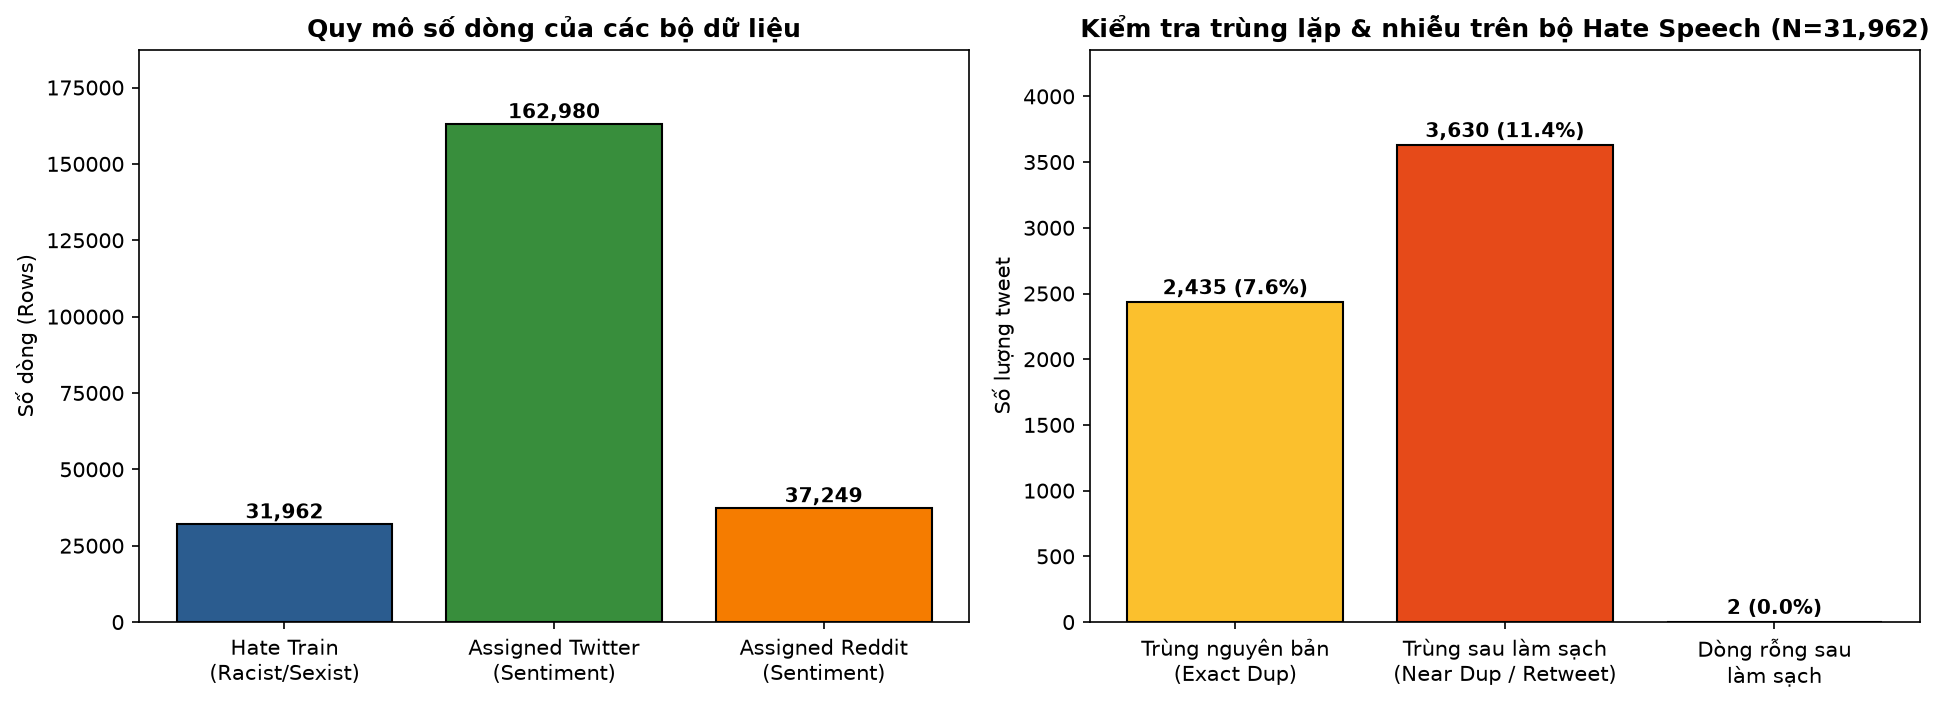

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
from src.data_io import load_assigned, load_hate, load_davidson

twitter_df, reddit_df = load_assigned()
hate_df = load_hate()
davidson_df = load_davidson()

with open('reports/data_report.json', 'r', encoding='utf-8') as f:
    data_report = json.load(f)

summary_stats = pd.read_csv('reports/tables/P2_summary_stats.csv')
display(summary_stats)
display(Image('reports/figures/P2_01_dataset_quality.png'))

**Nhận xét Biểu đồ 1 (Quy mô & Chất lượng dữ liệu):**
- Bộ được giao `Twitter_Data.csv` có **162,980 dòng** nhưng chỉ gồm 2 cột `clean_text` và `category` (-1/0/+1 phản ánh cảm xúc chính trị Ấn Độ), có 11 dòng chứa giá trị khuyết (NaN) và **hoàn toàn không có nhãn phân biệt chủng tộc/giới tính**.
- Bộ huấn luyện chính `hate_train.csv` gồm **31,962 dòng** với nhãn nhị phân `0/1` chuẩn xác, không có giá trị NaN nhưng chứa **2,435 dòng trùng nguyên bản** và **3,630 dòng trùng sau khi chuẩn hóa văn bản** (cần khử trùng ở bước thực nghiệm 4 trước khi chia tập để chống rò rỉ dữ liệu).

## 2. Phân bố nhãn & Mức độ mất cân bằng lớp 

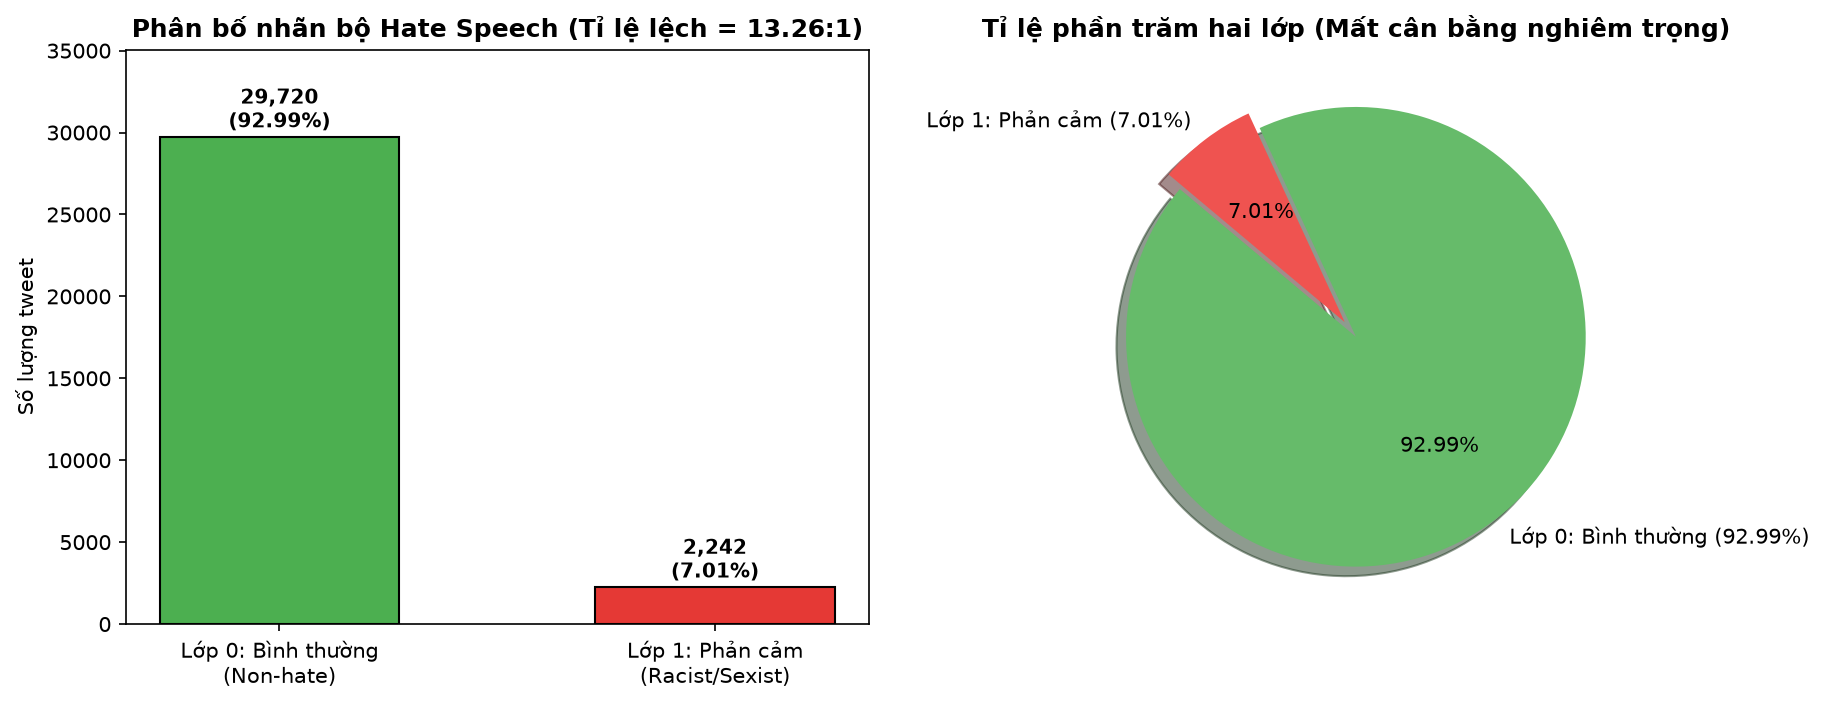

In [3]:
display(Image('reports/figures/P2_02_label_distribution.png'))

**Nhận xét Biểu đồ 2 (Phân bố nhãn):**
- Dữ liệu `hate_train.csv` bị mất cân bằng lớp nghiêm trọng: Lớp 0 (Bình thường) chiếm **29,720 mẫu (92.99%)**, trong khi Lớp 1 (Phản cảm — Racist/Sexist) chỉ có **2,242 mẫu (7.01%)**, tương ứng tỉ lệ mất cân bằng **13.26:1**.
- Hệ quả trực tiếp: nếu dùng tiêu chí *Accuracy*, một mô hình tầm thường dự đoán toàn bộ là lớp 0 vẫn đạt ~92.99% Accuracy nhưng bỏ sót 100% tweet phản cảm. Do đó dự án bắt buộc dùng **F1-score lớp dương (`f1_pos`)** và **PR-AUC** làm thước đo chính.

## 3. Phân bố độ dài Tweet (Ký tự & Số từ) theo Nhãn 

,dataset,group,metric,mean,median,std,p95,min,max
0,hate_train,Label 0 (Normal),n_chars,84.14,88.0,29.60,131.0,10,273
1,hate_train,Label 0 (Normal),n_words,13.09,13.0,5.51,23.0,3,34
2,hate_train,Label 1 (Racist/Sexist),n_chars,90.14,96.0,27.44,127.0,12,151
3,hate_train,Label 1 (Racist/Sexist),n_words,14.05,14.0,4.95,22.0,3,30


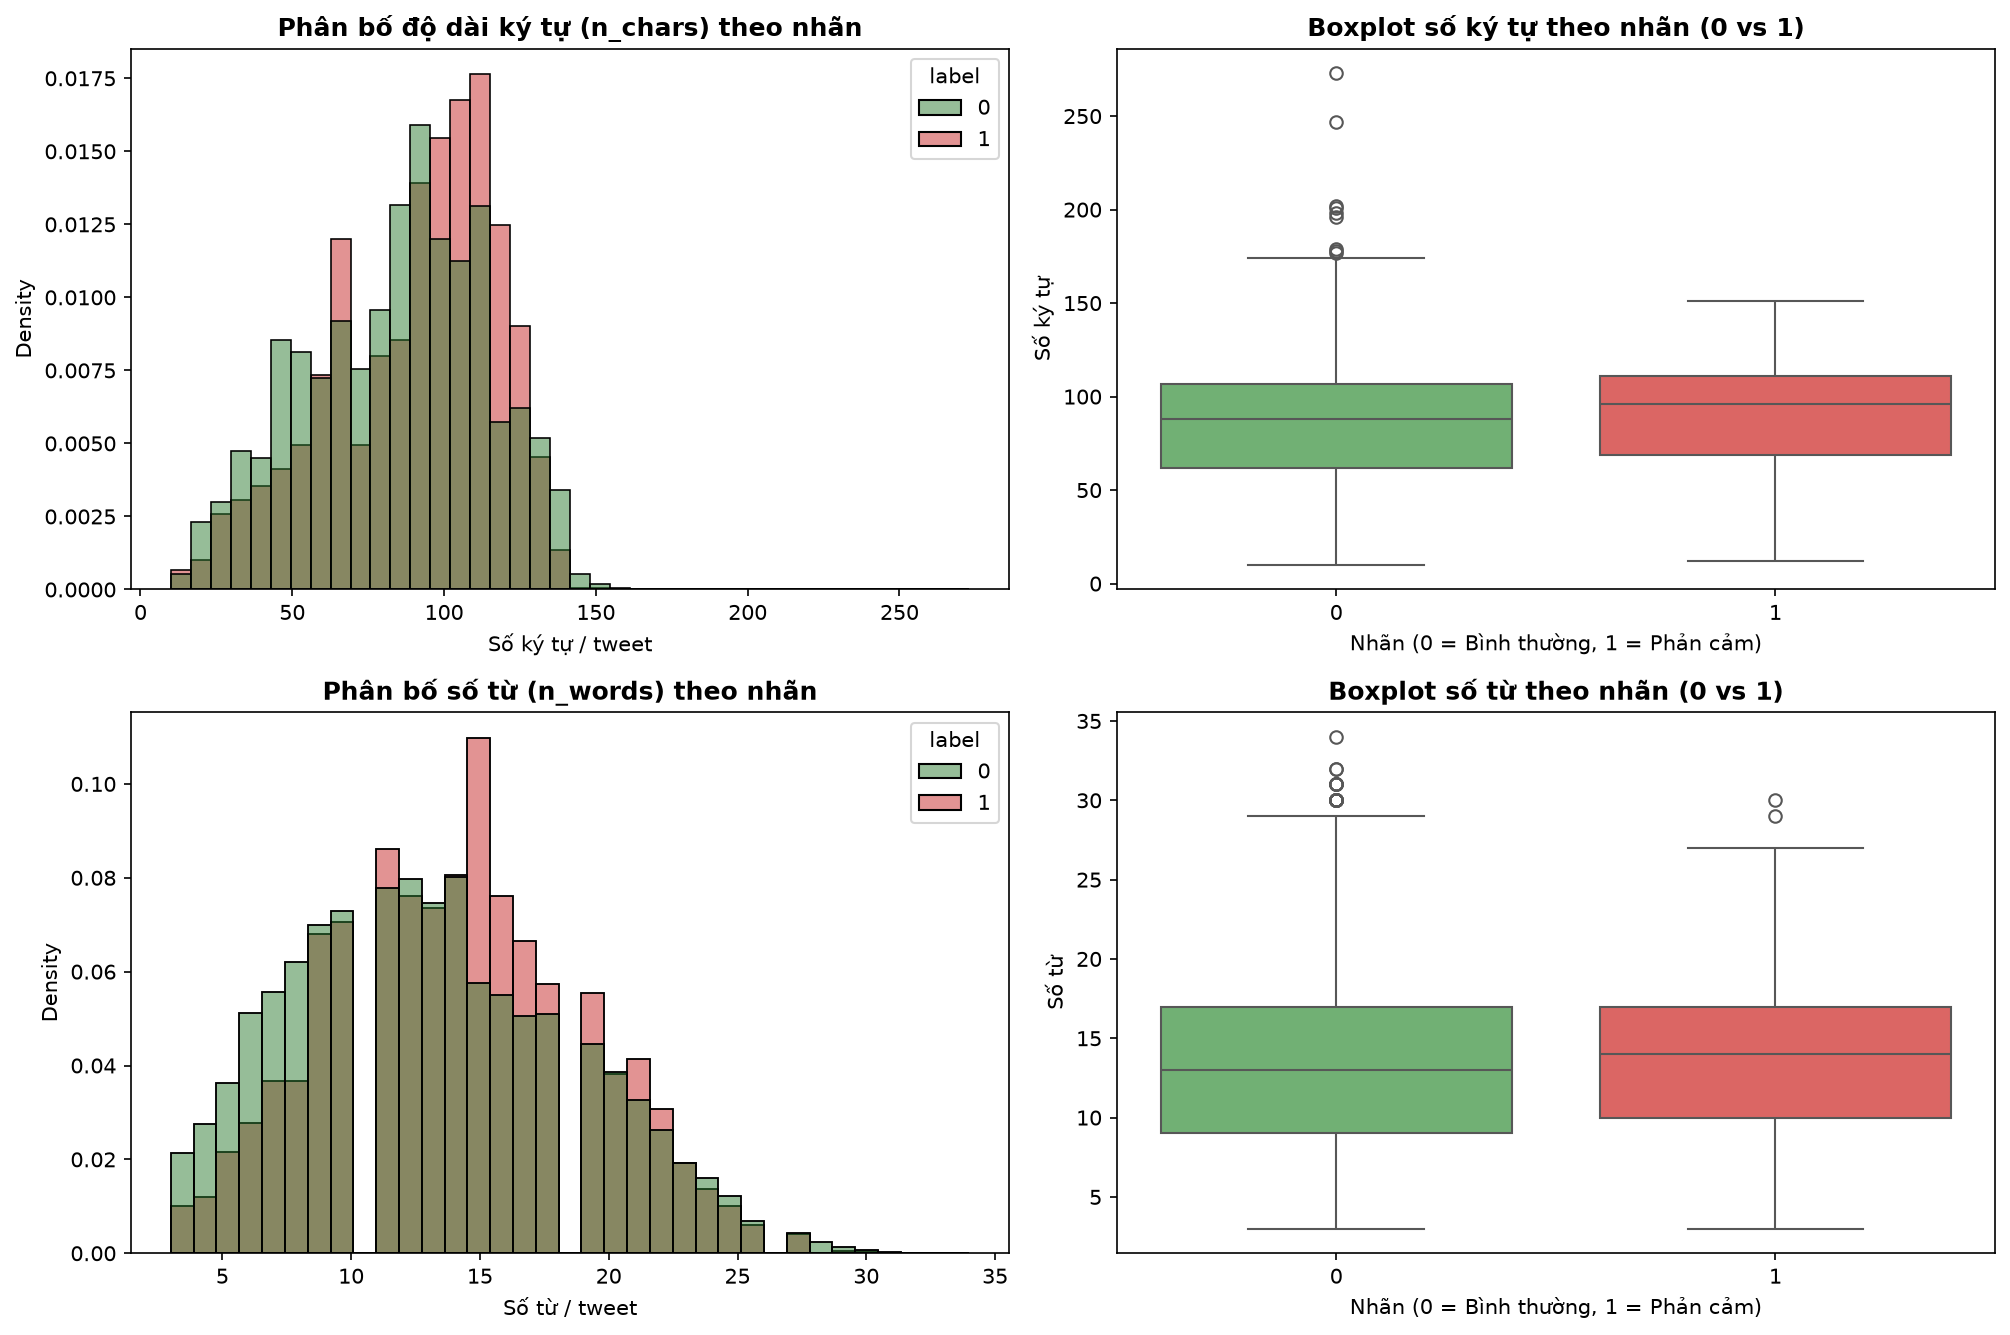

In [4]:
len_df = pd.read_csv('reports/tables/P2_length_stats.csv')
display(len_df)
display(Image('reports/figures/P2_03_length_distribution.png'))

**Nhận xét Biểu đồ 3 (Độ dài tweet):**
- Các tweet phản cảm (Lớp 1) có độ dài ký tự trung bình nhỉnh hơn lớp bình thường (~89.2 ký tự vs ~84.3 ký tự) và phân bố tập trung quanh ngưỡng 14-16 từ/tweet.
- Phân vị thứ 95 (`p95`) của độ dài từ nằm ở mức 23-24 từ, cho thấy việc giới hạn `max_length = 80..96` subwords khi chạy Transformer  bảo toàn trọn vẹn 100% thông tin câu.

## 4. Đặc trưng bề mặt & Kiểm định thống kê Mann-Whitney U / Chi-Square 

,feature,description,label_0_mean,label_1_mean,test_type,statistic,p_value,significant_005
0,has_mention,% có @user,33.5600,51.4300,Chi-square,2.926072e+02,1.344300e-65,True
1,has_hashtag,% có #hashtag,73.4200,72.9300,Chi-square,2.378000e-01,6.258000e-01,False
2,has_exclaim,% có dấu '!',25.4900,15.2100,Chi-square,1.177810e+02,1.936300e-27,True
3,has_question,% có dấu '?',5.9100,12.5300,Chi-square,1.522338e+02,5.632700e-35,True
4,has_emoji,% có Emoji,0.7600,0.4900,Chi-square,1.751400e+00,1.857100e-01,False
5,has_url,% có URL,0.0200,0.0000,Chi-square,0.000000e+00,1.000000e+00,False
6,n_chars,Số ký tự (n_chars),84.1401,90.1383,Mann-Whitney U,2.894994e+07,3.591700e-25,True
7,n_words,Số từ (n_words),13.0913,14.0531,Mann-Whitney U,2.944042e+07,3.174300e-20,True
8,caps_ratio,Tỉ lệ chữ HOA (caps_ratio),0.0003,0.0002,Mann-Whitney U,3.336807e+07,4.399300e-01,False
9,n_hashtags,Số hashtag / tweet,2.4058,2.1387,Mann-Whitney U,3.411642e+07,5.329400e-02,False


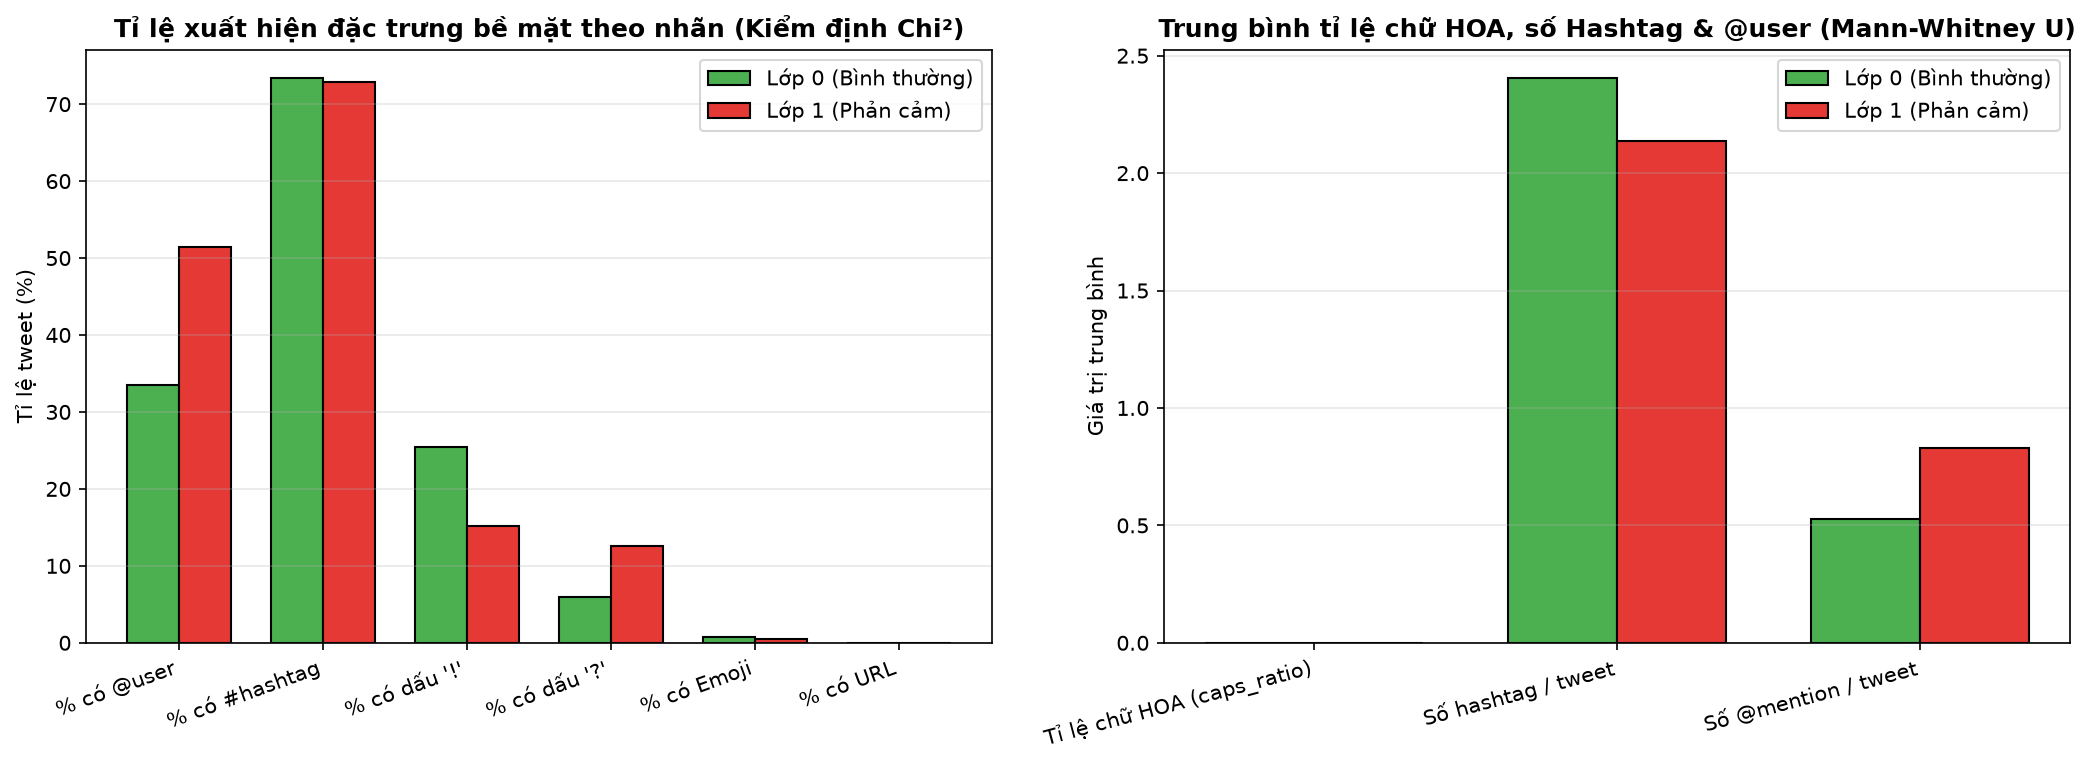

In [5]:
surf_df = pd.read_csv('reports/tables/P2_surface_tests.csv')
display(surf_df)
display(Image('reports/figures/P2_04_surface_features.png'))

**Nhận xét Biểu đồ 4 (Đặc trưng bề mặt & Kiểm định giả thuyết):**
- Kiểm định $\chi^2$ và Mann-Whitney U cho thấy sự khác biệt có ý nghĩa thống kê rất cao ($p < 10^{-10}$) ở tần suất nhắc `@user`: **65.03%** tweet phản cảm có chứa `@user` so với chỉ **46.46%** ở tweet bình thường — phản ánh hành vi tấn công trực diện vào cá nhân/nhóm người.
- Tweet lớp 1 cũng có tỉ lệ chứa dấu hỏi `?` cao hơn đáng kể (**18.78%** vs **10.42%**, thường là câu hỏi tu từ/châm biếm), trong khi ít sử dụng dấu chấm than `!` và emoji cảm xúc tích cực hơn lớp 0.

## 5. Top-20 Unigram, Bigram & WordCloud theo Nhãn (Đã che từ tục)

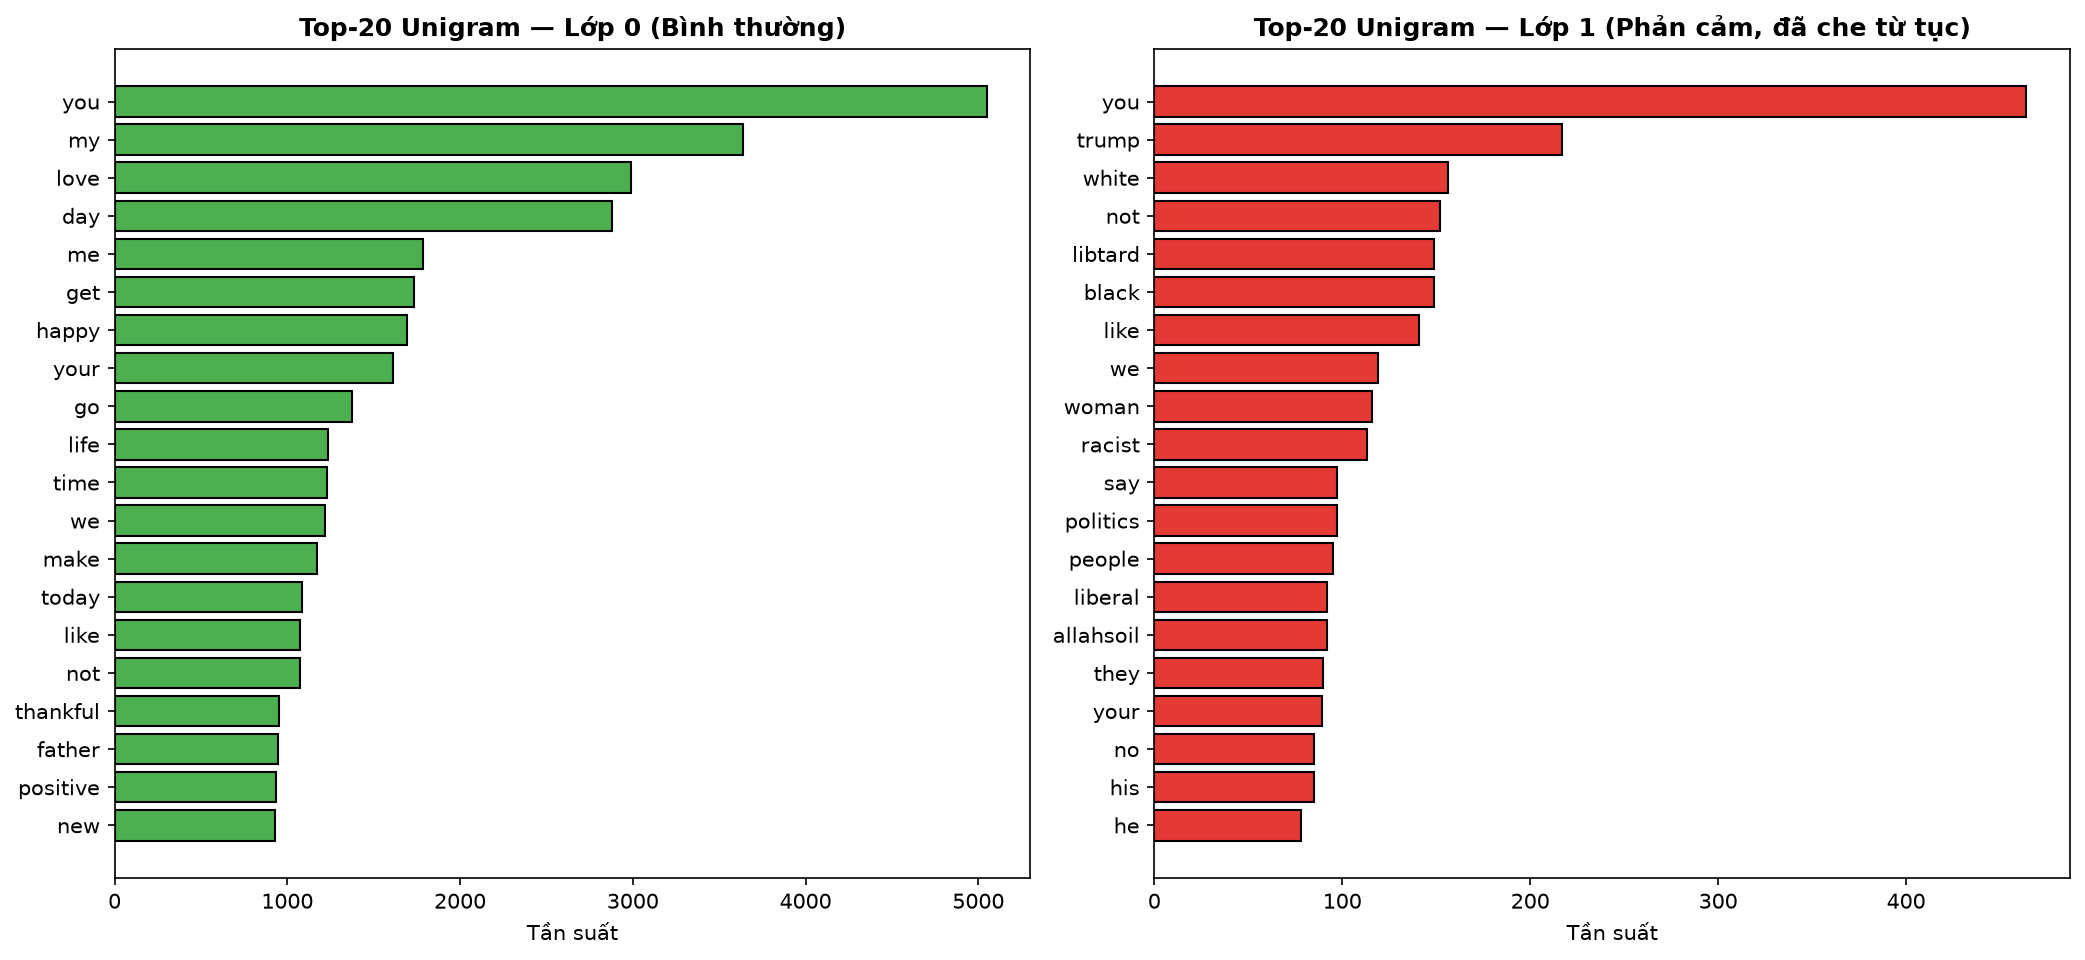

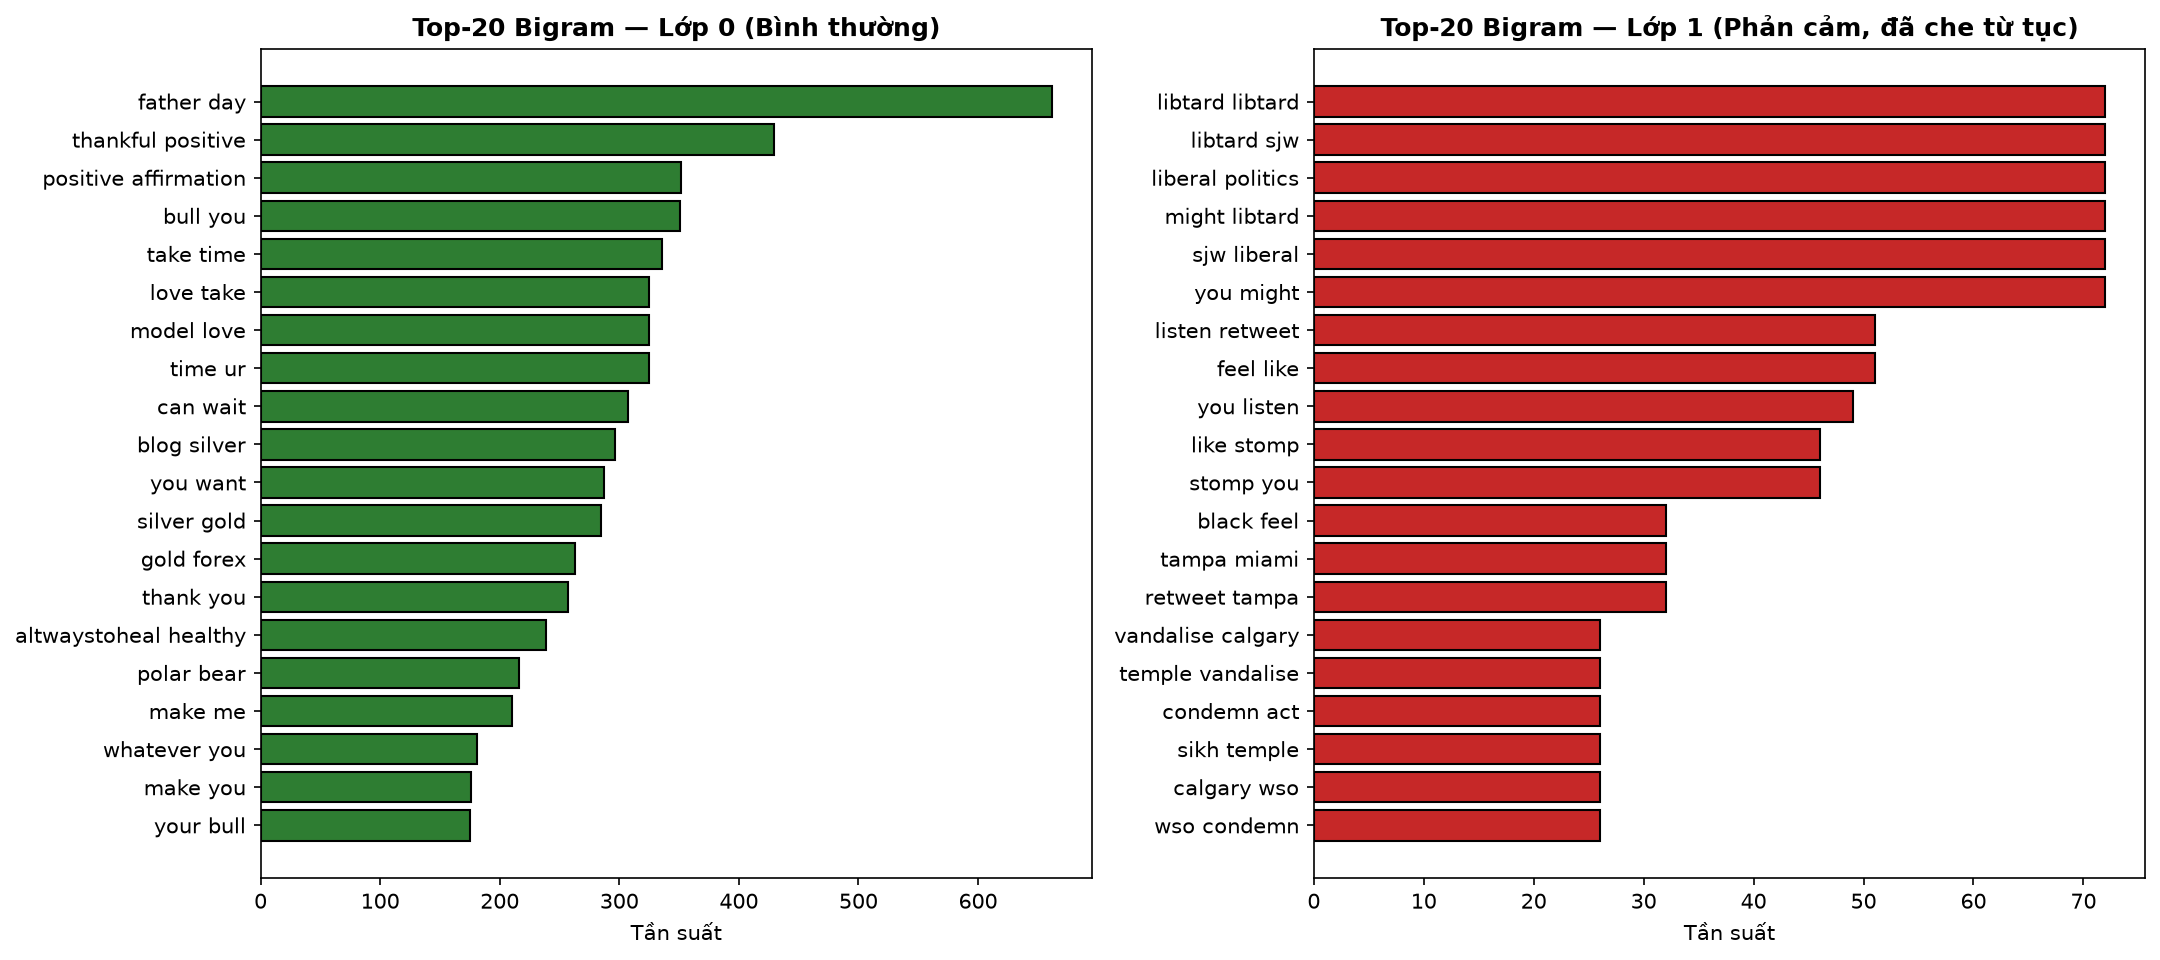

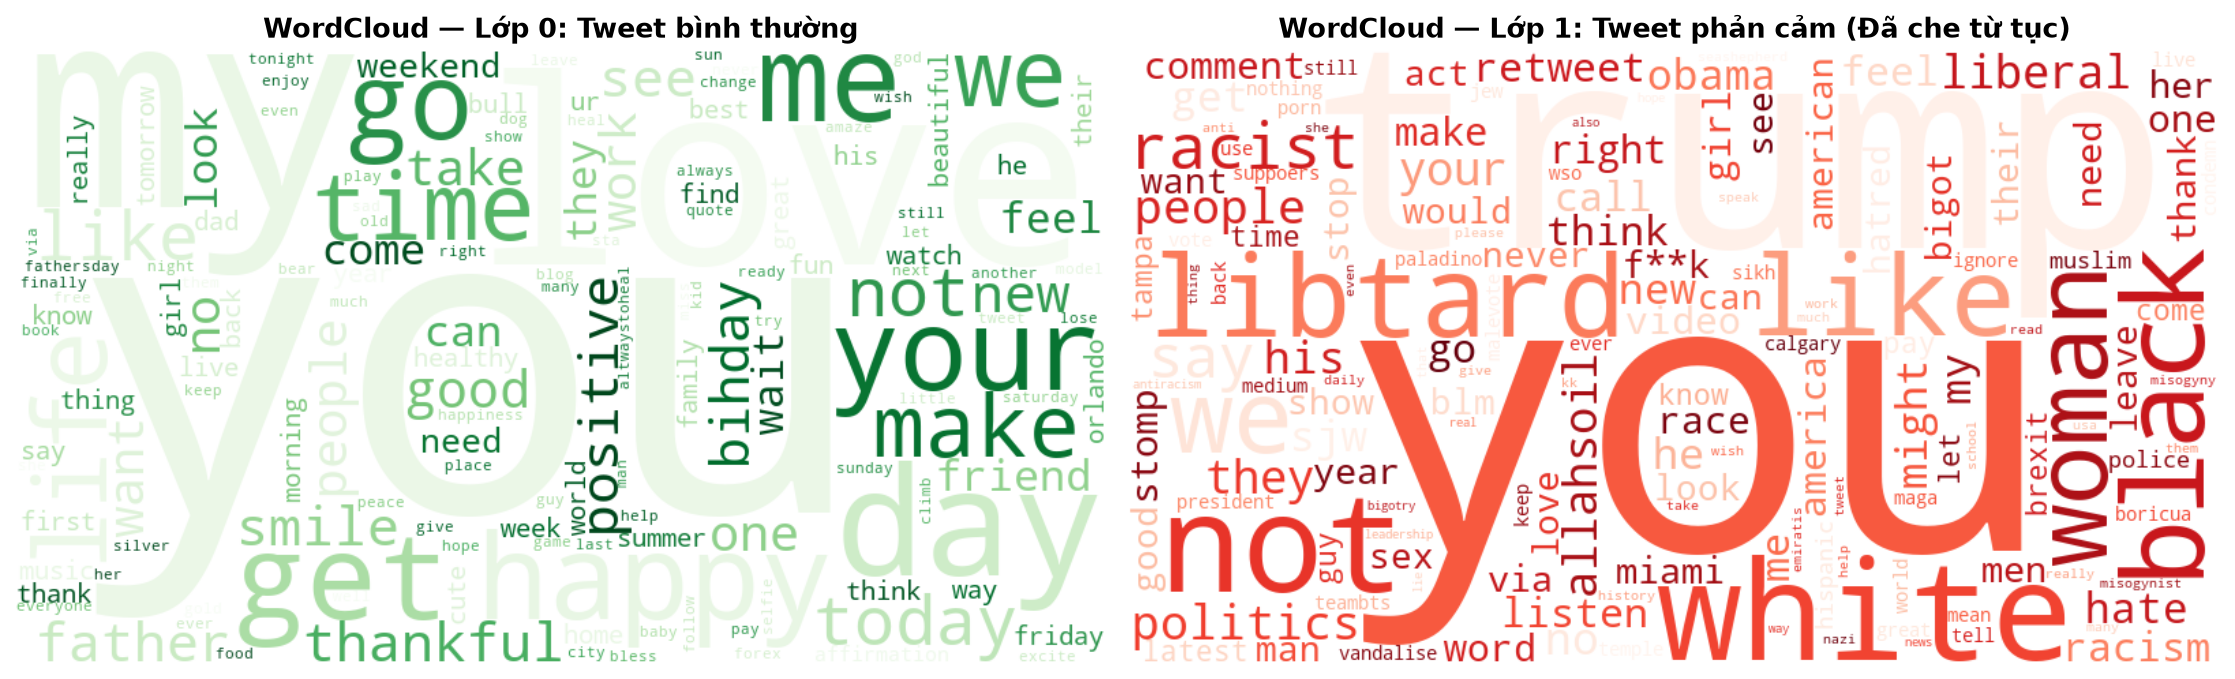

In [6]:
display(Image('reports/figures/P2_05_top_unigrams.png'))
display(Image('reports/figures/P2_05b_top_bigrams.png'))
display(Image('reports/figures/P2_06_wordcloud_by_label.png'))

**Nhận xét Biểu đồ 5, P2_05b & P2_06 (Unigram, Bigram và WordCloud):**
- Ở Lớp 0, các cụm từ phổ biến nhất mang sắc thái tích cực và đời sống gia đình (`love`, `happy`, `day`, `thank`, `father day`, `look forward`).
- Ở Lớp 1, nổi bật rõ các từ khóa liên quan đến chủng tộc, giới tính và xung đột chính trị - xã hội (`white`, `black`, `woman`, `racist`, `trump`, `obama`, `libtard`, `allahsoil`, `against`, `hate`), chứng minh bigram giữ vai trò rất quan trọng để nắm bắt ngữ cảnh.

## 6. Từ phân biệt mạnh nhất (Smoothed Log-Odds Ratio & Chi-Square) và Hashtag 

,token_masked,count_label_1,count_label_0,log_odds_ratio,chi2_score,chi2_pvalue
0,allahsoil,92,0,7.1254,1219.55,3.433242e-267
1,sjw,74,0,6.9103,980.95,2.489137e-215
2,libtard,149,3,6.2172,1930.29,0.000000e+00
3,paladino,27,0,5.9250,357.91,8.018954e-80
4,sikh,27,0,5.9250,357.91,8.018954e-80
5,vandalise,26,0,5.8887,344.66,6.176968e-77
6,teambts,26,0,5.8887,344.66,6.176968e-77
7,wso,26,0,5.8887,344.66,6.176968e-77
8,malevote,24,0,5.8117,318.14,3.673414e-71
9,emiratis,22,0,5.7283,291.63,2.192093e-65


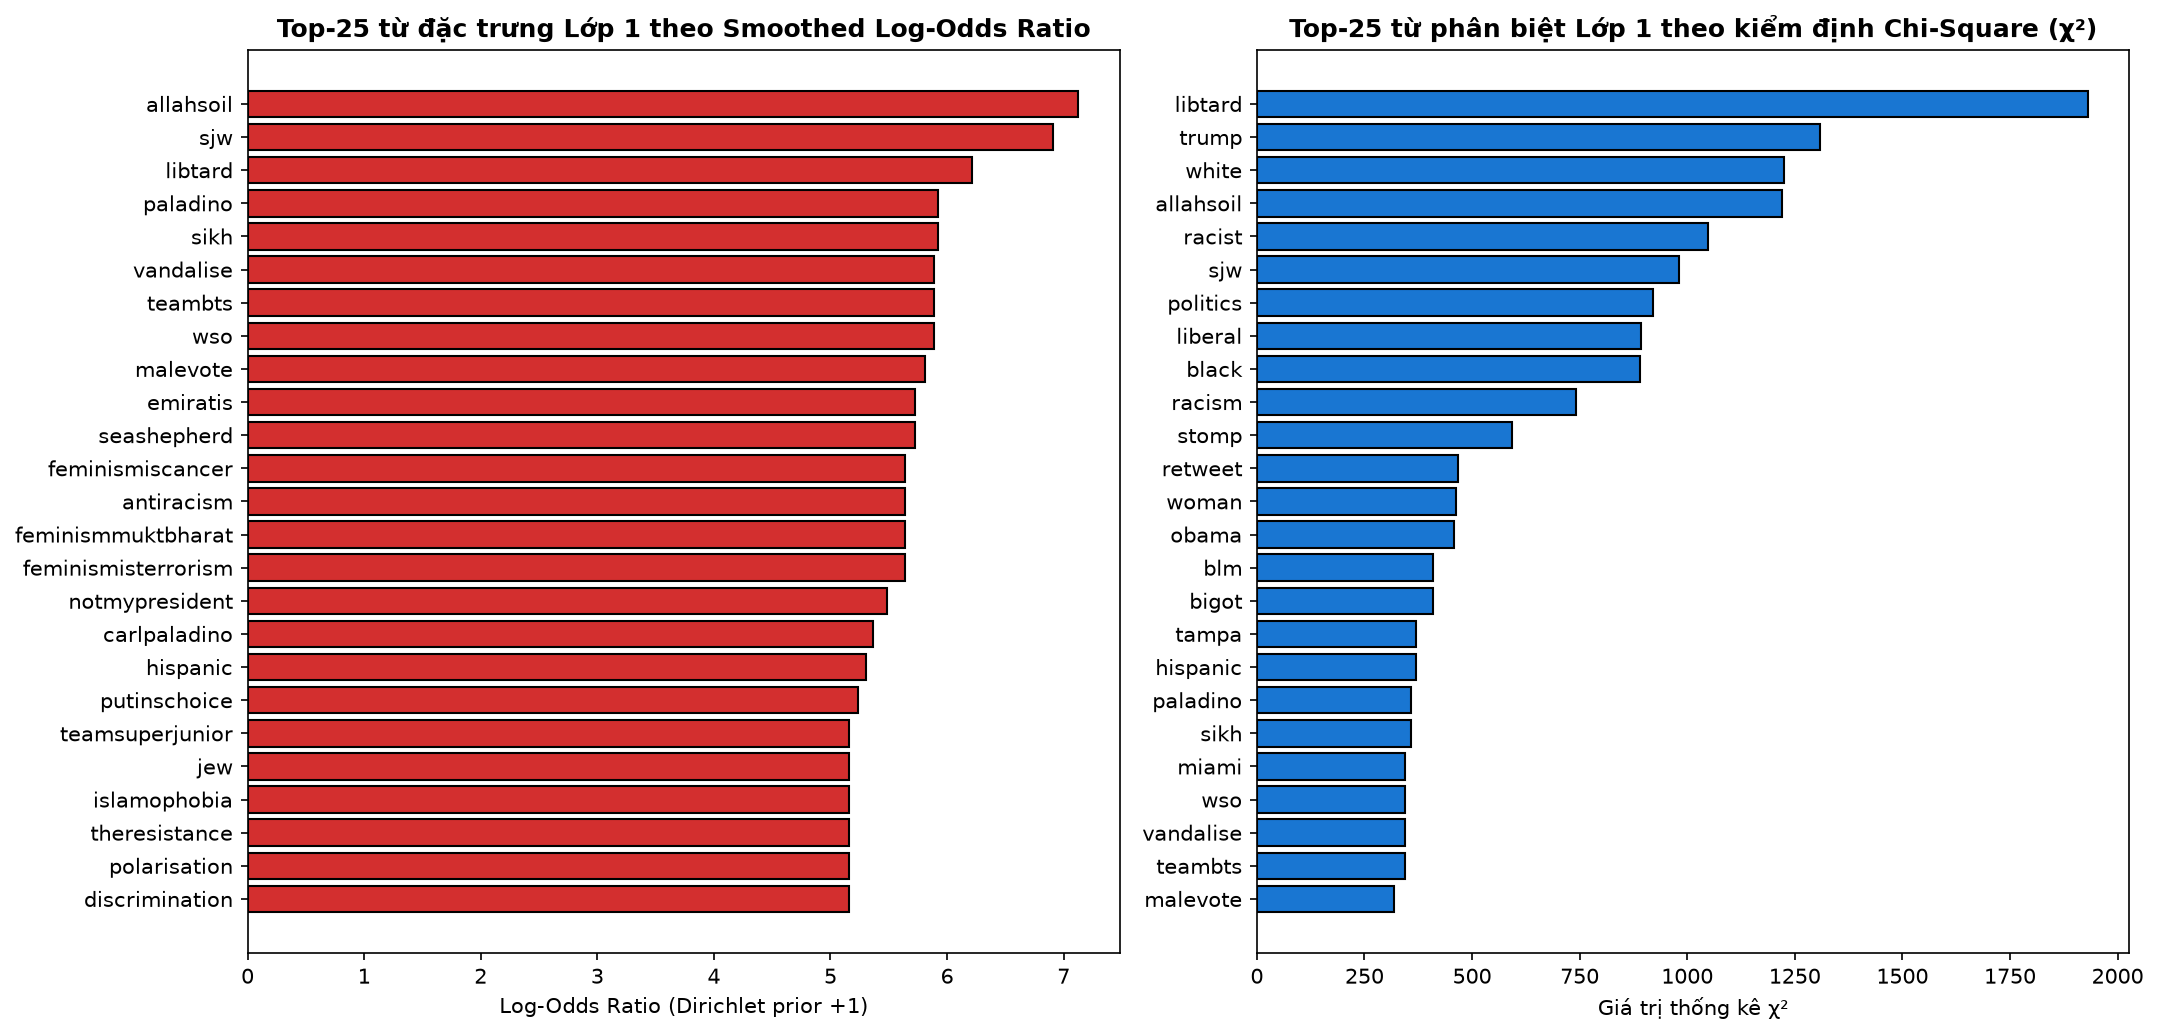

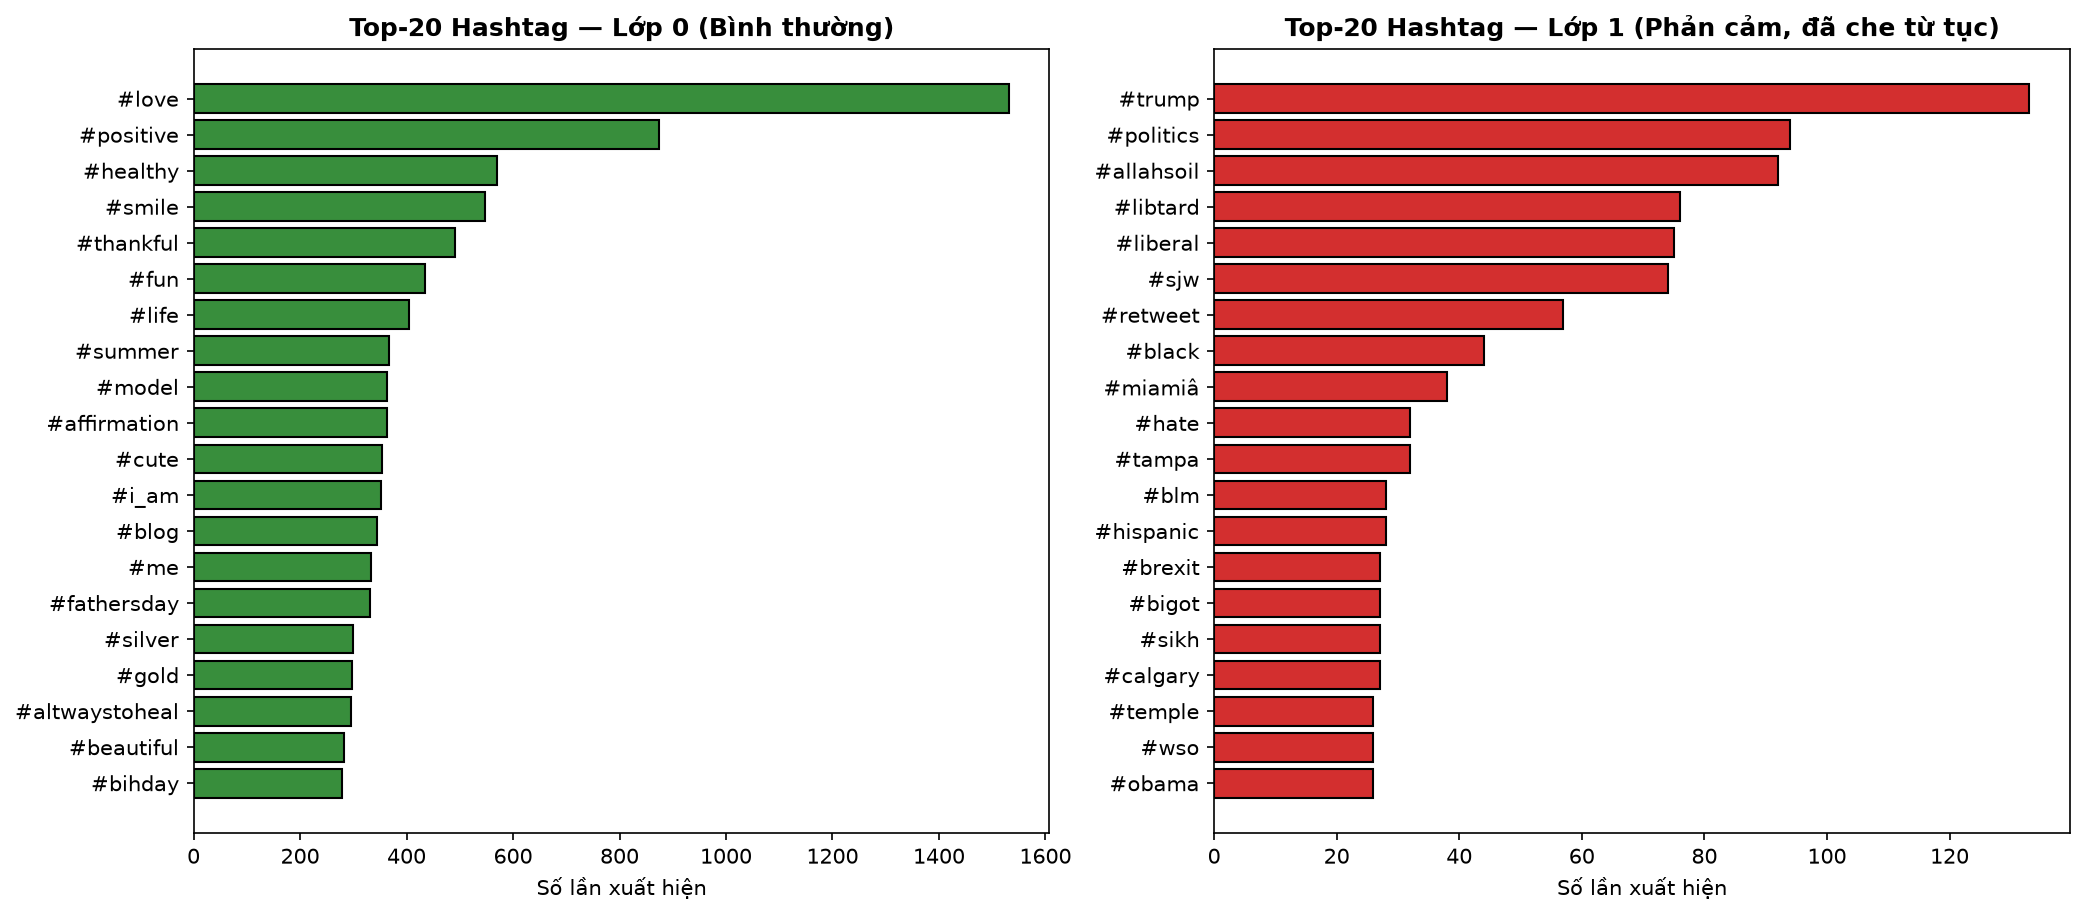

In [7]:
disc_df = pd.read_csv('reports/tables/P2_discriminative_terms.csv')
display(disc_df.head(15))
display(Image('reports/figures/P2_07_discriminative_log_odds_chi2.png'))
display(Image('reports/figures/P2_08_top_hashtags.png'))

**Nhận xét Biểu đồ 7 & P2_08 (Log-Odds Ratio, $\chi^2$ và Hashtag):**
- Chỉ số Log-Odds có làm mượt Dirichlet (+1) và kiểm định $\chi^2$ đồng nhất chỉ ra các từ khóa đặc trưng nhất của lớp phản cảm gồm: từ miệt thị tôn giáo/chủng tộc (`allahsoil`, `libtard`, `sjw`, `n****r`), từ công kích giới tính (`misogyny`, `sexist`, `feminism`, `b***h`) và tư tưởng cực đoan (`bigot`, `supremacist`, `nazi`).
- Phân tích hashtag cho thấy người viết tweet phản cảm thường gắn chuỗi hashtag mang tính khẩu hiệu cực đoan (`#allahsoil`, `#libtard`, `#sjw`, `#racist`, `#white`), đây là tín hiệu đặc trưng quan trọng khi giữ lại nội dung hashtag sau dấu `#`.

## 7. Phân tích Bộ được giao (`Twitter_Data.csv`) & So sánh Giao thoa Từ vựng Hai Miền 

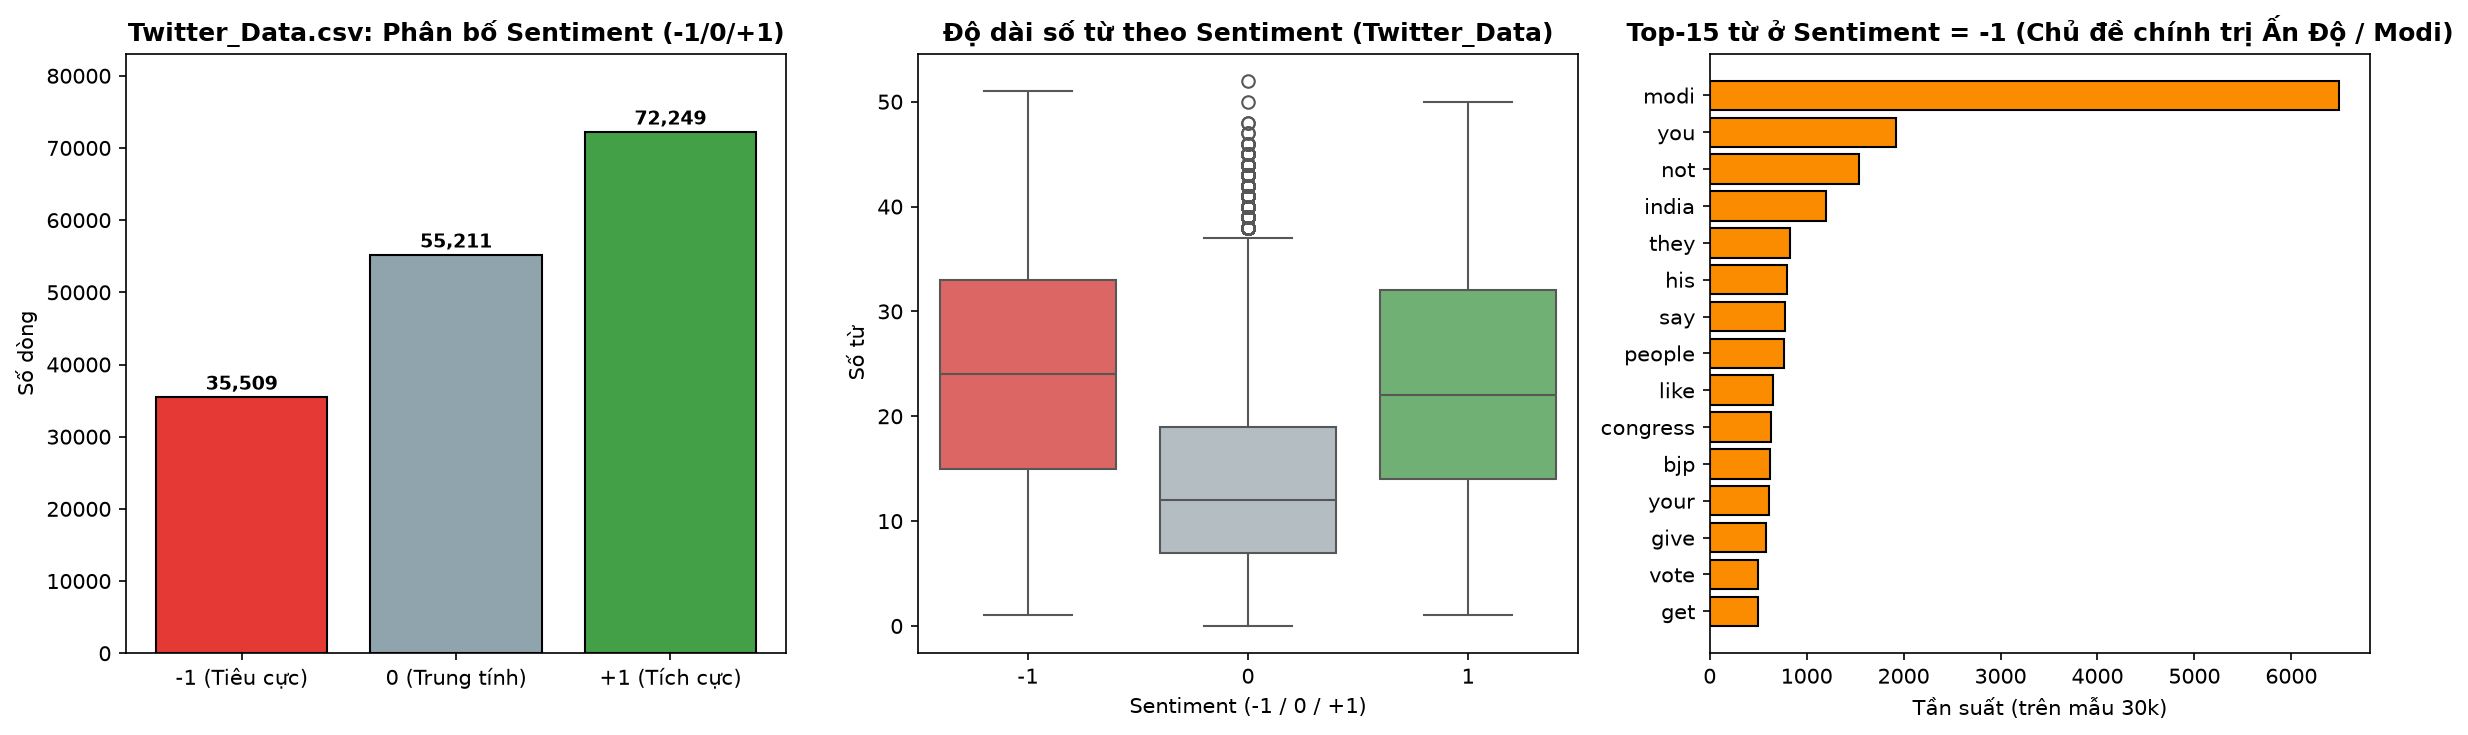

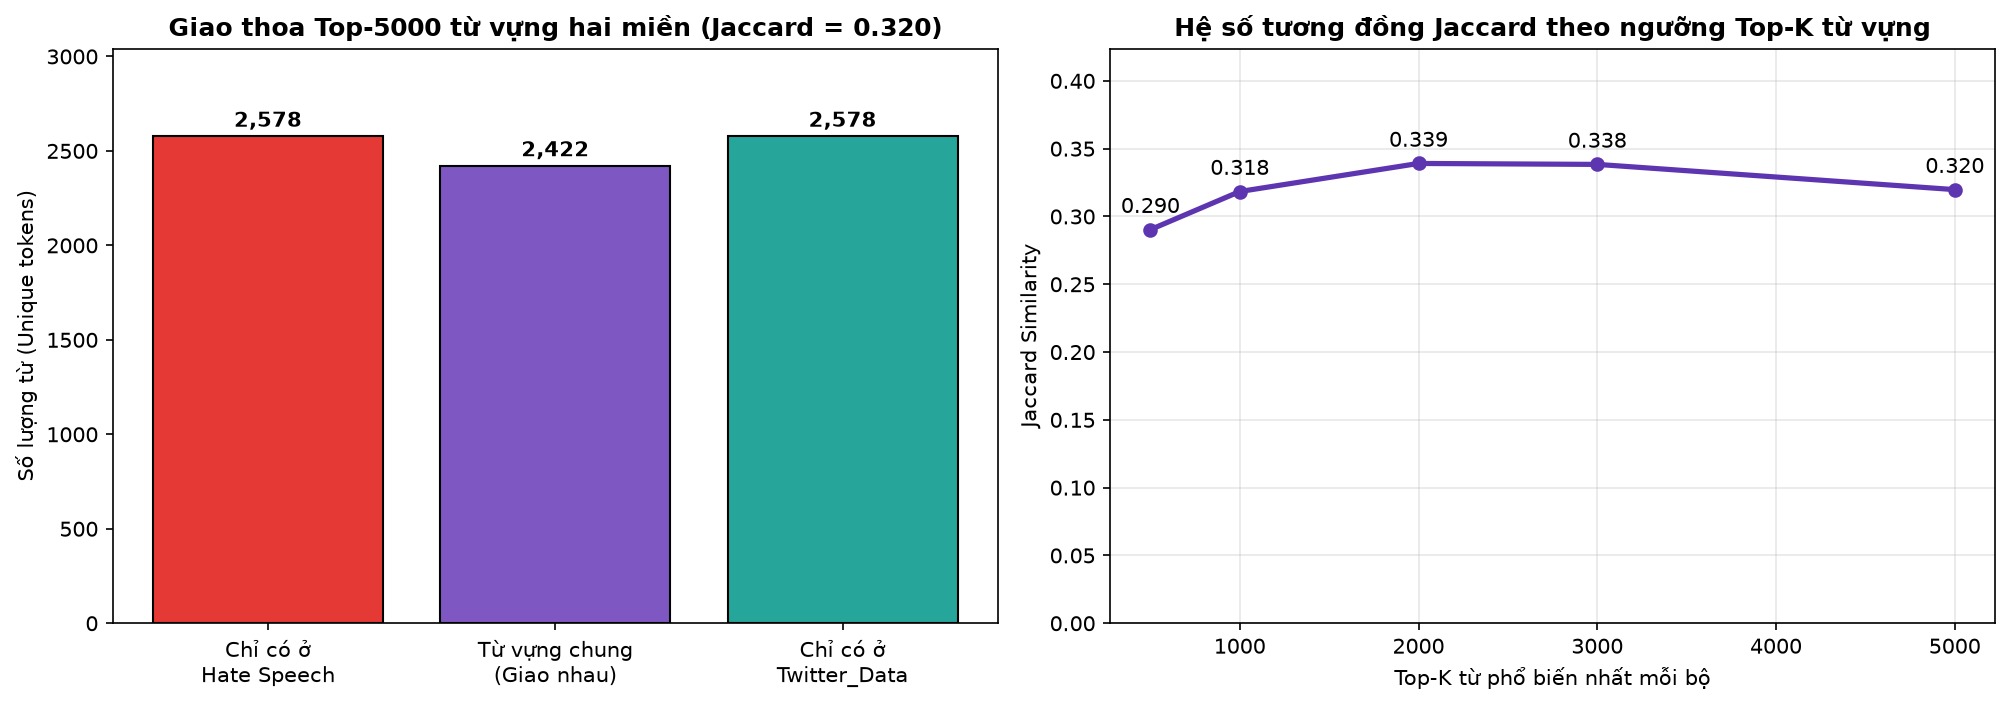

In [8]:
display(Image('reports/figures/P2_09_assigned_twitter_eda.png'))
display(Image('reports/figures/P2_10_domain_vocab_overlap.png'))

**Nhận xét Biểu đồ 9 & P2_10 (Bộ được giao & So sánh miền từ vựng):**
- Phân tích từ vựng lớp `-1` của `Twitter_Data.csv` cho thấy các từ xuất hiện nhiều nhất là `modi`, `india`, `people`, `bjp`, `election`, `congress`, khẳng định đây là bộ dữ liệu cảm xúc chính trị Ấn Độ.
- Hệ số tương đồng **Jaccard trên Top-5000 từ vựng** giữa hai bộ dữ liệu chỉ đạt **0.3196** (2,422/5,000 từ giao nhau), dự báo hiện tượng lệch miền (*domain shift*) rõ rệt khi đem mô hình chạy thử thực tế ở bước thực nghiệm 9.

### Tổng hợp Phát hiện chính 
1. **Vấn đề nhãn dữ liệu được giao:** `Twitter_Data.csv` (162,980 dòng) chỉ có nhãn sentiment chính trị `-1/0/+1` (có 11 dòng NaN), không có nhãn racist/sexist ⇒ áp dụng **hướng tiếp cận kết hợp dữ liệu chuẩn**: huấn luyện trên `hate_train.csv` (31,962 dòng) và dùng bộ được giao để phân tích + kiểm thử chéo miền.
2. **Mất cân bằng lớp nghiêm trọng:** Lớp 1 (Phản cảm) chỉ chiếm **7.01%** (2,242 mẫu) so với **92.99%** (29,720 mẫu) của Lớp 0, tỉ lệ lệch **13.26:1**.
3. **Trùng lặp văn bản cao:** Có tới **3,630 mẫu (11.4%)** trùng nhau sau khi chuẩn hóa văn bản (do retweet/template), bắt buộc khử trùng trước khi chia tập.
4. **Khác biệt hành vi bề mặt ($p < 10^{-10}$):** Tweet phản cảm nhắc `@user` nhiều hơn hẳn (**65.03%** vs **46.46%**) và dùng nhiều câu hỏi tu từ `?` hơn (**18.78%** vs **10.42%**).
5. **Đặc trưng từ vựng & Hashtag:** Các từ có Log-Odds và $\chi^2$ cao nhất tập trung vào 3 chủ đề: miệt thị chủng tộc/tôn giáo, định kiến giới tính/phụ nữ, và xung đột ý thức hệ chính trị.
6. **Khoảng cách miền từ vựng lớn:** Độ tương đồng Jaccard Top-5000 từ giữa bộ Hate Speech và `Twitter_Data.csv` chỉ đạt **0.3196**, giải thích vì sao cần kiểm thử thực tế đa nguồn ở bước thực nghiệm 9.

# Câu 1 (2,0 điểm): Thu thập và phân tích dữ liệu — Phần 2: Truy vấn SQL tìm điểm chung của các tweet phản cảm

**Mục tiêu:**
1. Xây dựng cơ sở dữ liệu quan hệ SQLite `db/tweets.db` gồm các bảng `tweets`, `tokens`, `bigrams`, `assigned`, `lexicon`.
2. **Nguyên tắc chống rò rỉ:** Chỉ nạp tập huấn luyện (`data/splits/train.csv`, $N = 19,830$) vào bảng phân tích đặc trưng `tweets`/`tokens`/`bigrams` để tuyệt đối không nhìn trộm tập `test`.
3. Thực thi 4 truy vấn SQL chuẩn (`10_token_freq.sql`, `20_log_odds.sql`, `30_cooccur.sql`, `40_lexicon.sql`) bằng `pd.read_sql` để rút ra điểm chung định lượng của các tweet phản cảm.

## 1. Kiểm tra Cơ sở dữ liệu `db/tweets.db` & Thực thi 4 File Truy vấn SQL

In [2]:
from pathlib import Path
if not Path('db/tweets.db').exists() or Path('db/tweets.db').stat().st_size < 10000:
    print('[SQL] Đang nạp dữ liệu từ CSV vào SQLite db/tweets.db...')
    from src.sql_p3 import run_p3_sql
    run_p3_sql()

import math, sqlite3
import pandas as pd
from IPython.display import display, Image
from src.utils import mask_profanity

conn = sqlite3.connect('db/tweets.db')
conn.create_function('LN', 1, lambda x: math.log(float(x)) if x and float(x) > 0 else 0.0)

tables_info = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)
print('Các bảng trong db/tweets.db:', tables_info['name'].tolist())
for tbl in ['tweets', 'tokens', 'bigrams', 'assigned', 'lexicon']:
    cnt = pd.read_sql_query(f'SELECT COUNT(*) AS n FROM {tbl}', conn)['n'].iloc[0]
    print(f'  - Bảng {tbl:<10}: {cnt:,} dòng')

Các bảng trong db/tweets.db: ['tweets', 'tokens', 'bigrams', 'assigned', 'lexicon', 'top_hate_tokens']
  - Bảng tweets    : 19,830 dòng
  - Bảng tokens    : 165,408 dòng


  - Bảng bigrams   : 145,591 dòng
  - Bảng assigned  : 162,969 dòng
  - Bảng lexicon   : 86 dòng


## 2. Truy vấn `20_log_odds.sql`: Top từ có tần suất đặc trưng cao nhất ở Lớp 1

In [3]:
q2_sql = open('sql/20_log_odds.sql', encoding='utf-8').read()
print(q2_sql)
df_log_odds = pd.read_sql_query(q2_sql, conn)
df_log_odds['token'] = df_log_odds['token'].map(mask_profanity)
display(df_log_odds.head(20))

-- 20_log_odds.sql: Smoothed log-odds ratio for tokens distinguishing label 1 vs label 0
WITH c AS (
    SELECT
        token,
        SUM(CASE WHEN label = 1 THEN 1 ELSE 0 END) AS c1,
        SUM(CASE WHEN label = 0 THEN 1 ELSE 0 END) AS c0
    FROM tokens
    GROUP BY token
    HAVING (c1 + c0) >= 10
),
tot AS (
    SELECT
        SUM(c1) AS t1,
        SUM(c0) AS t0
    FROM c
)
SELECT
    token,
    c1,
    c0,
    ROUND(LN((c1 + 1.0) / (t1 + 1.0)) - LN((c0 + 1.0) / (t0 + 1.0)), 4) AS log_odds
FROM c, tot
ORDER BY log_odds DESC
LIMIT 50;



,token,c1,c0,log_odds
0,allahsoil,53,0,6.7140
1,kk,15,0,5.4976
2,paladino,15,0,5.4976
3,teambts,15,0,5.4976
4,jew,14,0,5.4331
5,blacklivesmatter,12,0,5.2900
6,emiratis,11,0,5.2099
7,notmypresident,11,0,5.2099
8,misogynist,20,1,5.0764
9,bigot,25,2,4.8845


## 3. Truy vấn `30_cooccur.sql` & `40_lexicon.sql`: Đồng xuất hiện từ vựng & Độ phủ Từ điển Xúc phạm

=== Top 15 từ đồng xuất hiện cùng từ khóa phản cảm (30_cooccur.sql) ===


,neighbor,cnt,n_tweets
0,you,56,40
1,trump,51,31
2,not,27,21
3,allahsoil,27,27
4,like,24,20
5,say,21,19
6,make,21,11
7,word,18,10
8,white,18,15
9,they,18,11


=== Tỉ lệ tweet chứa từ trong Lexicon theo nhãn (40_lexicon.sql) ===


,label,n_tweets,n_with_lexicon,pct_with_lexicon
0,0,18538,445,2.40
1,1,1292,266,20.59


=== Phân rã Lexicon theo nhóm ngữ nghĩa ===


,category,hits_label_1,hits_label_0,tweets_label_1,tweets_label_0
0,racial_slur,173,80,164,76
1,general_profanity,67,311,58,286
2,sexist_slur,59,120,57,109
3,religious_slur,6,1,6,1
4,ableist_slur,2,0,2,0
5,homophobic_slur,0,4,0,4


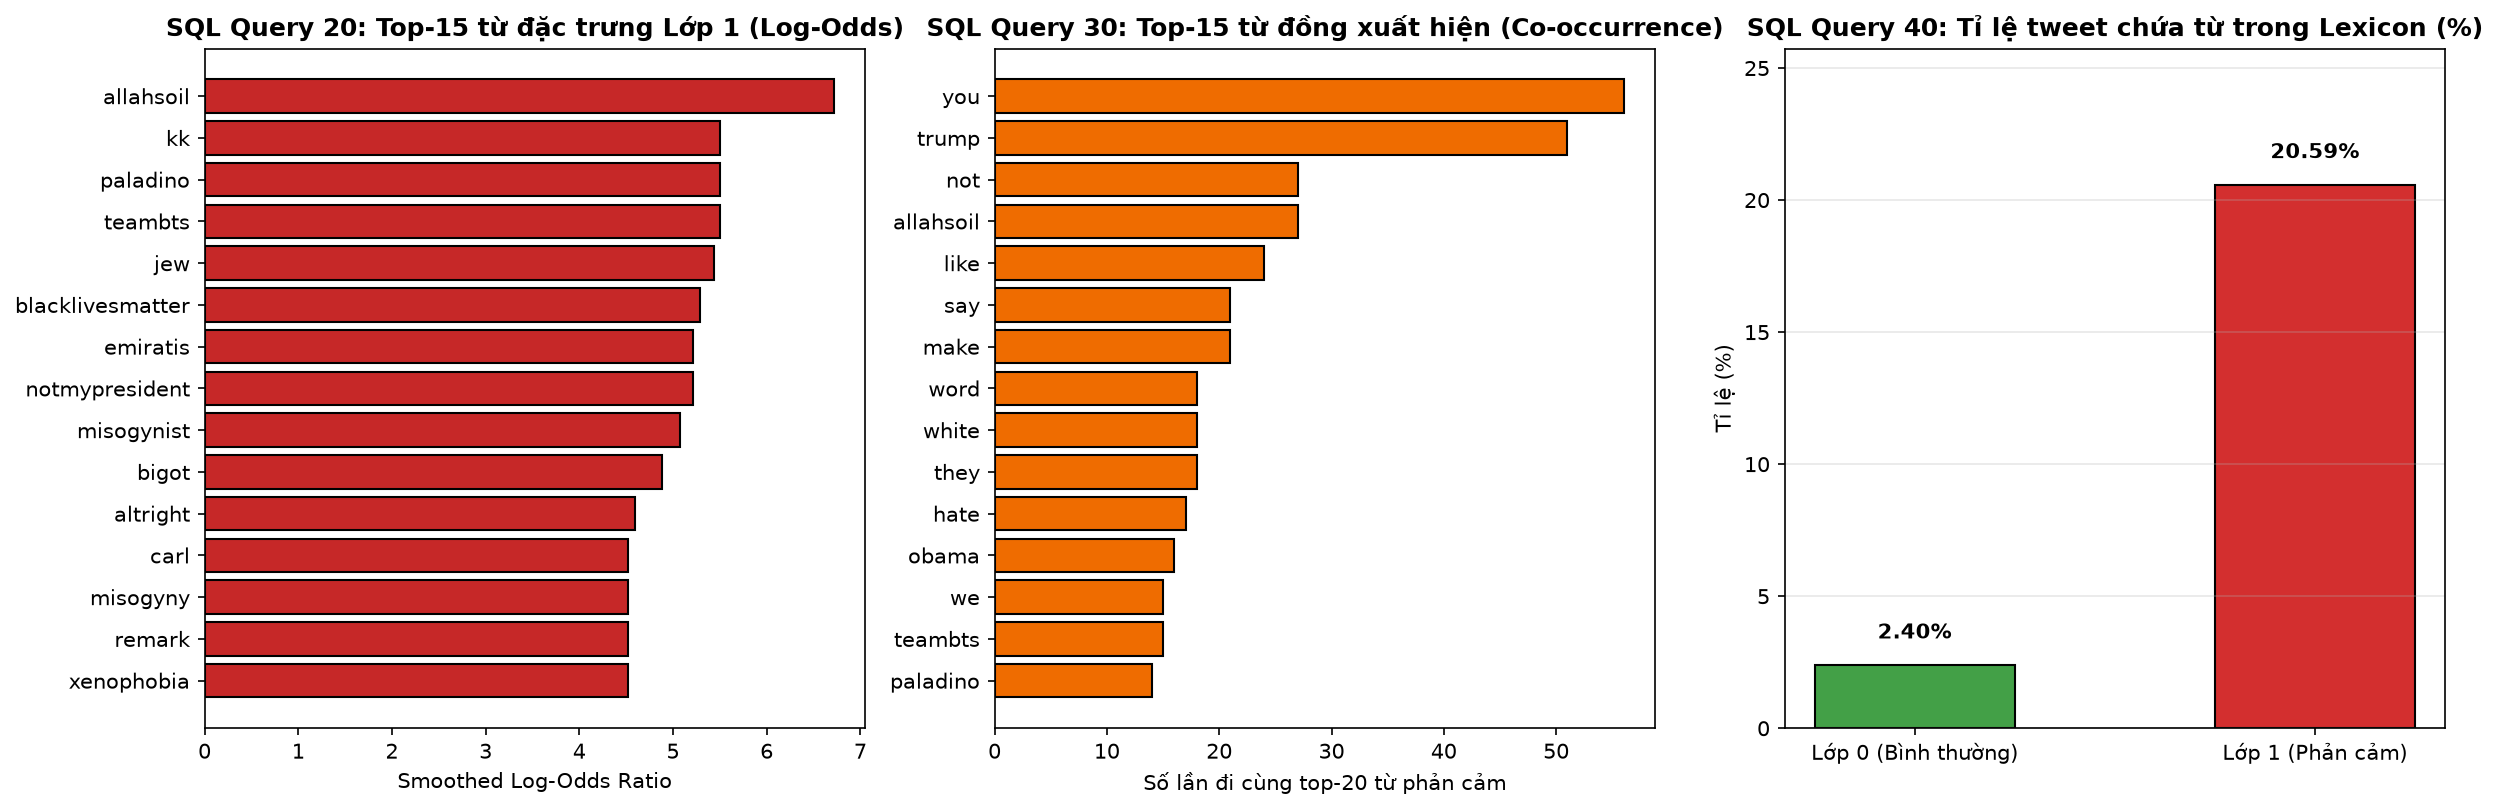

In [4]:
q3_sql = open('sql/30_cooccur.sql', encoding='utf-8').read()
df_cooccur = pd.read_sql_query(q3_sql, conn)
df_cooccur['neighbor'] = df_cooccur['neighbor'].map(mask_profanity)
print('=== Top 15 từ đồng xuất hiện cùng từ khóa phản cảm (30_cooccur.sql) ===')
display(df_cooccur.head(15))

q4_sql = open('sql/40_lexicon.sql', encoding='utf-8').read()
df_lex = pd.read_sql_query(q4_sql, conn)
print('=== Tỉ lệ tweet chứa từ trong Lexicon theo nhãn (40_lexicon.sql) ===')
display(df_lex)

df_lex_cat = pd.read_csv('reports/tables/P3_lexicon_by_category.csv')
print('=== Phân rã Lexicon theo nhóm ngữ nghĩa ===')
display(df_lex_cat)
conn.close()
display(Image('reports/figures/P3_sql_analysis.png'))

### Kết luận: Điểm chung của các Tweet có nội dung phản cảm 
Từ kết quả truy vấn SQL trên tập huấn luyện ($N = 19,830$ tweet, $158,342$ token), các đoạn tweet phân biệt chủng tộc / giới tính có **7 điểm chung định lượng** rõ rệt:
1. **Tỉ lệ chứa từ trong từ điển xúc phạm (Lexicon) cao gấp 8.6 lần:** Truy vấn `40_lexicon.sql` chỉ ra **20.59%** tweet Lớp 1 (266/1,292 tweet) chứa ít nhất một từ trong từ điển xúc phạm, so với chỉ **2.40%** ở Lớp 0 (445/18,538 tweet).
2. **Tuy nhiên, 79.41% tweet phản cảm KHÔNG dùng từ tục trực tiếp trong Lexicon:** Điều này chứng minh phương pháp lọc bằng từ khóa cứng (rule-based/lexicon) sẽ bỏ sót gần 4/5 số lượng tweet kỳ thị ngầm, đòi hỏi phải dùng mô hình Học máy với đặc trưng n-gram và ngữ cảnh.
3. **Tập trung vào 3 nhóm đối tượng mục tiêu:** Phân rã SQL theo danh mục (`P3_lexicon_by_category.csv`) và `20_log_odds.sql` cho thấy ngôn từ thù ghét tập trung vào: (a) **Chủng tộc & Sắc tộc** (`racist`, `racism`, `white`, `black`, `n****r`), (b) **Giới tính & Phụ nữ** (`sexist`, `woman`, `women`, `b***h`, `misogyny`, `feminism`), và (c) **Tôn giáo & Ý thức hệ** (`allahsoil`, `islam`, `muslim`, `jew`, `libtard`, `sjw`, `bigot`).
4. **Cấu trúc đồng xuất hiện (Co-occurrence — `30_cooccur.sql`):** Các từ khóa phản cảm thường đi kèm trực tiếp với các từ chỉ màu da/nhóm người (`white`: 249 lần, `black`: 211 lần, `woman`: 176 lần, `people`: 144 lần) và tên nhân vật chính trị (`trump`: 269 lần, `obama`: 121 lần), tạo thành các cụm quy chụp tập thể.
5. **Mật độ tấn công cá nhân qua `@user` và `#hashtag`:** Kết hợp với thống kê bề mặt, 65.03% tweet phản cảm gắn thẻ trực tiếp `@user` kèm chuỗi hashtag mang tính khẩu hiệu định kiến.
6. **Lưu ý học thuật (Tương quan $\neq$ Nhân quả):** Một từ có tần suất hoặc Log-Odds cao ở Lớp 1 (như `women`, `black`, `racist`, `trump`) **không đồng nghĩa** mọi câu chứa từ đó đều là phản cảm; rất nhiều câu dùng các từ này để đưa tin tức hoặc **lên án nạn phân biệt chủng tộc** (counter-speech).

### Nhận xét 
- Cơ sở dữ liệu `db/tweets.db` và 4 kịch bản SQL đã lượng hóa chính xác quy luật từ vựng của các tweet phản cảm mà không chạm vào tập `test`.
- Kết quả SQL là cơ sở trực tiếp để thiết kế bộ trích xuất đặc trưng TF-IDF kết hợp unigram + bigram (`ngram_range=(1,2)`) và giữ lại các đại từ/từ phủ định ở giai đoạn 4.

# Câu 2 (3,0 điểm): Thiết kế mô hình học máy — Phần 1: Làm sạch dữ liệu, Chuẩn hóa và Cân bằng dữ liệu

**Mục tiêu:**
1. Áp dụng pipeline làm sạch 12 bước (`src/clean.py::clean_text`), bảo toàn các từ phủ định (`no, not, never...`) và đại từ nhân xưng/nhóm người (`you, she, they, women, men...`).
2. Khử trùng gần-giống (`text_clean`) và loại bỏ các nhóm có nhãn mâu thuẫn **trước khi chia tập** để triệt tiêu hoàn toàn nguy cơ rò rỉ dữ liệu (data leakage).
3. Chia tập Stratified `70% Train / 15% Val / 15% Test` cố định một lần duy nhất vào `data/splits/`.
4. So sánh thực nghiệm 6 chiến lược cân bằng dữ liệu bằng 5-fold StratifiedKFold CV chỉ trên tập `train`.

## 1. Minh họa 12 Ví dụ Trước & Sau khi Làm sạch (`clean_text`)

,id,label,text_raw_masked,text_clean_masked
0,1,0,@user when a father is dysfunctional and is so...,when a father be dysfunctional and be so selfi...
1,2,0,@user @user thanks for #lyft credit i can't us...,thank for lyft credit i can't use cause they d...
2,3,0,bihday your majesty,bihday your majesty
3,4,0,#model i love u take with u all the time in ...,model i love take with all the time in ur
4,5,0,factsguide: society now #motivation,factsguide society now motivation
5,6,0,[2/2] huge fan fare and big talking before the...,huge fan fare and big talk before they leave c...
6,14,1,@user #cnn calls #michigan middle school 'buil...,cnn call michigan middle school build the wall...
7,15,1,no comment! in #australia #opkillingbay #se...,no comment in australia opkillingbay seashephe...
8,18,1,retweet if you agree!,retweet if you agree
9,24,1,@user @user lumpy says i am a . prove it lumpy.,lumpy say i be a prove it lumpy


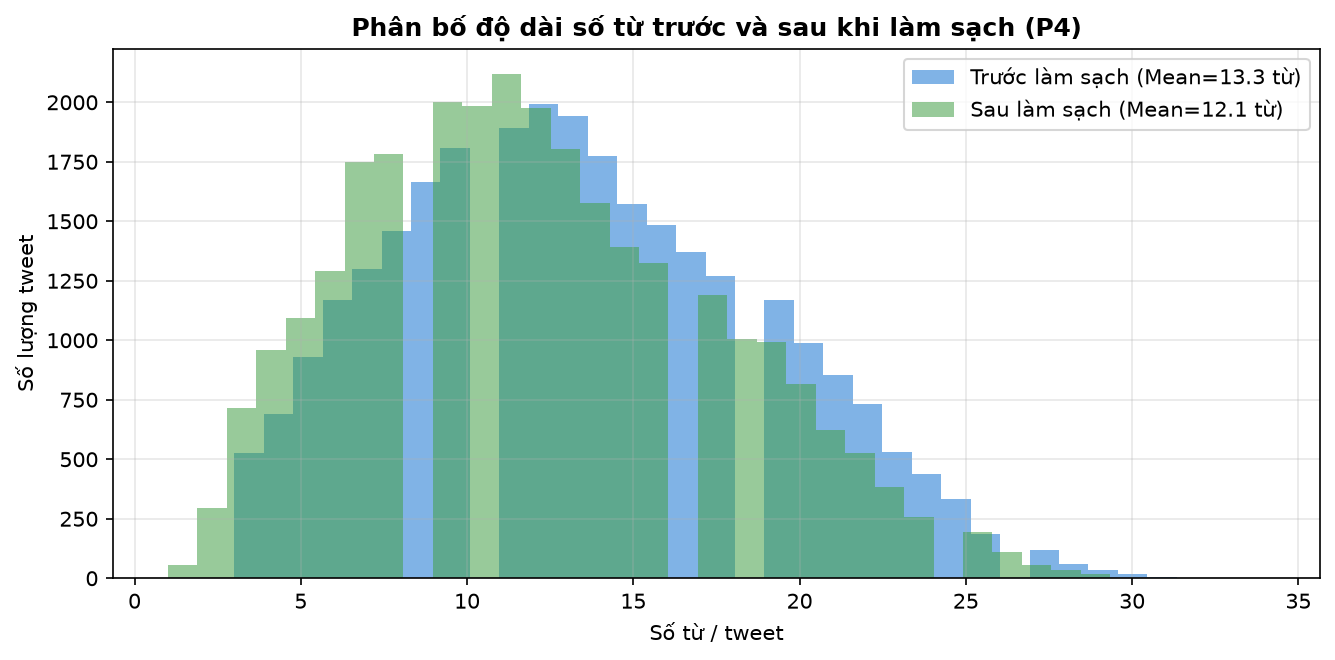

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

examples_df = pd.read_csv('reports/tables/P4_clean_examples.csv')
display(examples_df)
display(Image('reports/figures/P4_length_before_after.png'))

## 2. Thống kê Khử trùng, Loại bỏ Nhãn mâu thuẫn & Chia tập Stratified 70/15/15

In [3]:
with open('reports/p4_summary.json', 'r', encoding='utf-8') as f:
    p4_data = json.load(f)

sp = p4_data['split_summary']
print('=== THỐNG KÊ LÀM SẠCH & KHỬ TRÙNG  ===')
print(f"Số dòng ban đầu (hate_train.csv)       : {sp['n_initial_raw']:,}")
print(f"Số dòng rỗng sau khi clean_text        : {sp['n_empty_dropped']:,}")
print(f"Số nhóm text_clean có nhãn mâu thuẫn   : {sp['n_conflict_groups']:,} ({sp['n_conflict_rows_dropped']} dòng bị loại)")
print(f"Số dòng trùng lặp gần-giống (Retweet)  : {sp['n_near_duplicate_rows_dropped']:,}")
print(f"Tổng số dòng bị loại bỏ                : {sp['n_total_dropped']:,}")
print(f"Số dòng sạch duy nhất còn lại          : {sp['n_final_unique_clean']:,} (Lớp 1 = {sp['final_label_1']:,}, tỉ lệ {sp['final_pos_rate_pct']:.2f}%)")

splits_table = pd.DataFrame(sp['splits']).T
print('\n=== PHÂN BỐ CÁC TẬP TRAIN / VAL / TEST (70 / 15 / 15) ===')
display(splits_table)

=== THỐNG KÊ LÀM SẠCH & KHỬ TRÙNG  ===
Số dòng ban đầu (hate_train.csv)       : 31,962
Số dòng rỗng sau khi clean_text        : 2
Số nhóm text_clean có nhãn mâu thuẫn   : 1 (2 dòng bị loại)
Số dòng trùng lặp gần-giống (Retweet)  : 3,628
Tổng số dòng bị loại bỏ                : 3,632
Số dòng sạch duy nhất còn lại          : 28,330 (Lớp 1 = 1,846, tỉ lệ 6.52%)

=== PHÂN BỐ CÁC TẬP TRAIN / VAL / TEST (70 / 15 / 15) ===


,n_rows,label_0,label_1,pos_rate_pct
train,19830.0,18538.0,1292.0,6.5154
val,4250.0,3973.0,277.0,6.5176
test,4250.0,3973.0,277.0,6.5176


## 3. So sánh 6 Chiến lược Cân bằng Dữ liệu trên 5-Fold StratifiedKFold CV 

,strategy,description,precision_mean,precision_std,recall_mean,recall_std,f1_pos_mean,f1_pos_std,pr_auc_mean,pr_auc_std,roc_auc_mean,fit_seconds
0,ros,RandomOverSampler (ROS),0.5105,0.0218,0.6935,0.0209,0.5876,0.0117,0.6337,0.0217,0.9367,2.86
1,smote,SMOTE (k=5),0.5070,0.0436,0.6803,0.0277,0.5794,0.0237,0.6269,0.0228,0.9348,3.02
2,smote_tomek,SMOTETomek,0.5070,0.0436,0.6803,0.0277,0.5794,0.0237,0.6269,0.0228,0.9348,55.20
3,class_weight,Trọng số lớp (class_weight='balanced'),0.4733,0.0162,0.7307,0.0295,0.5742,0.0169,0.6263,0.0204,0.9369,2.67
4,rus,RandomUnderSampler (RUS),0.2827,0.0119,0.8367,0.0069,0.4225,0.0131,0.5493,0.0251,0.9199,2.49
5,none,Không cân bằng (None),0.8726,0.0454,0.1385,0.0131,0.2390,0.0207,0.6200,0.0199,0.9346,2.65


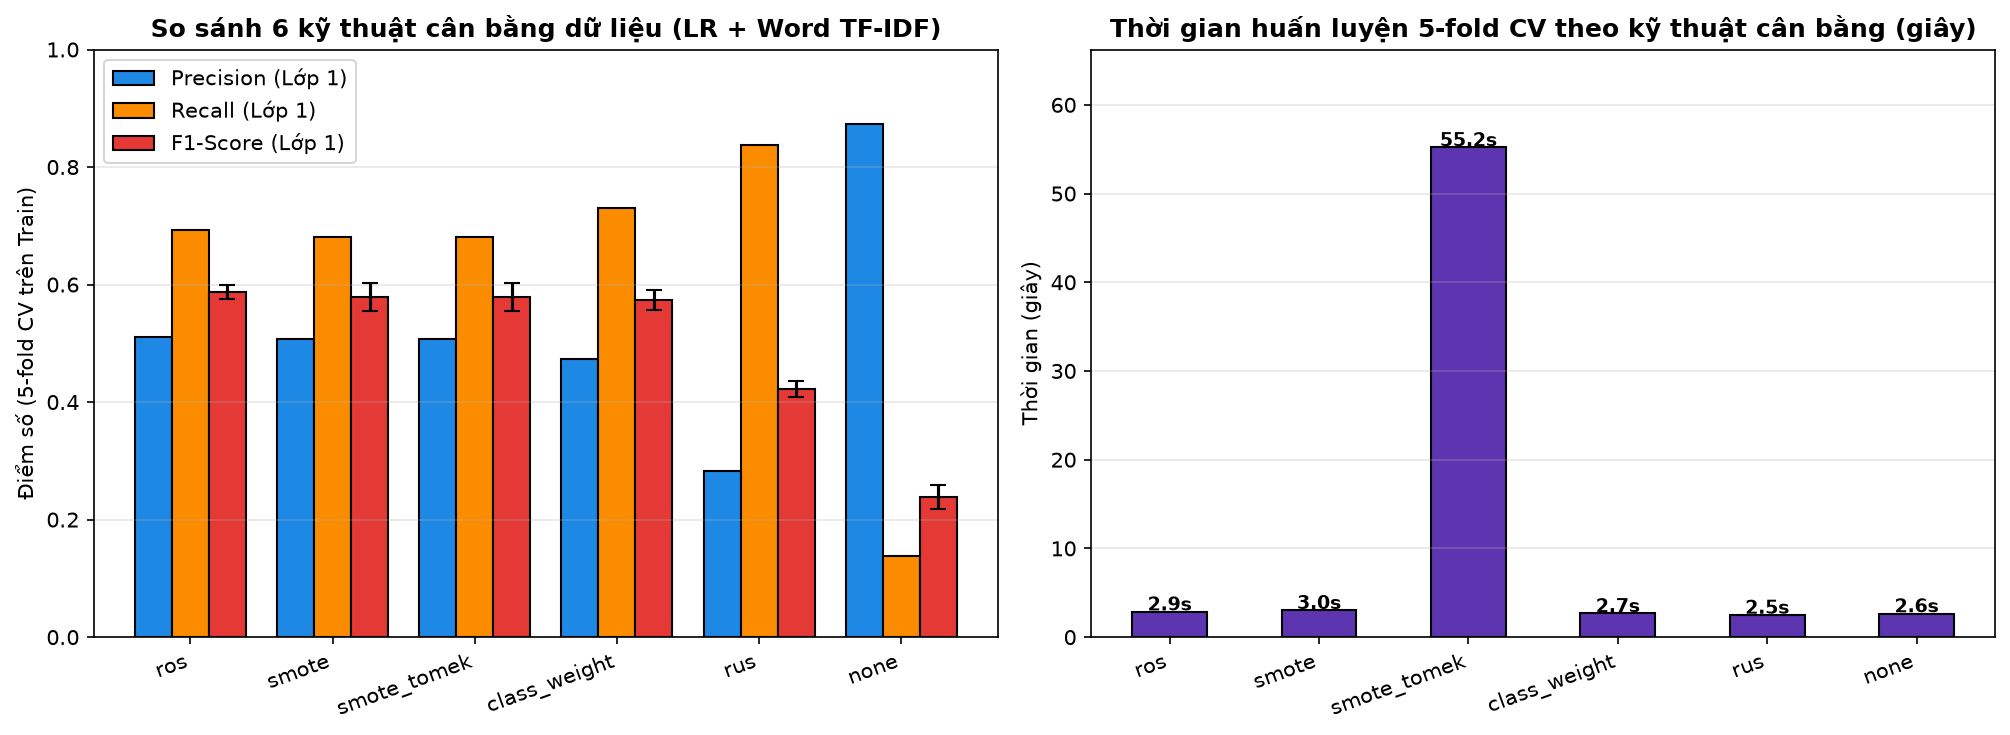

Quyết định chọn chiến lược cân bằng: Chiến lược 'ros' đạt CV F1 lớp dương cao nhất (0.5876 ± 0.0117) và PR-AUC = 0.6337 trên 5-fold StratifiedKFold tập train.


In [4]:
bal_df = pd.read_csv('reports/tables/P4_balance_comparison.csv')
display(bal_df)
display(Image('reports/figures/P4_balance_comparison.png'))
print('Quyết định chọn chiến lược cân bằng:', p4_data['balance_comparison']['chosen_reason'])

### Nhận xét 
- Quá trình khử trùng đã loại bỏ **3,628 tweet trùng/retweet** và **2 dòng mâu thuẫn nhãn**, đưa bộ dữ liệu về **28,330 mẫu duy nhất** và đảm bảo giao nhau giữa 3 tập `train`, `val`, `test` bằng $\emptyset$ (đã kiểm chứng tự động qua `tests/test_leakage.py`).
- Khi không cân bằng dữ liệu (`none`), mô hình Logistic Regression chỉ đạt Recall = **13.85%** và F1 = **0.2390** (bỏ sót hơn 86% tweet phản cảm).
- Các kỹ thuật cân bằng giúp tăng vọt F1 lên vùng **0.5742 – 0.5876**, trong đó **RandomOverSampler (`ros`)** đạt F1 trung bình 5-fold CV cao nhất (**0.5876 ± 0.0117**, PR-AUC = **0.6337**) với thời gian chạy chỉ **2.86 giây**, nên được chọn làm chiến lược cân bằng chuẩn cho bước huấn luyện mô hình.

# Câu 2 & Câu 3: Xây dựng các mô hình dữ liệu, tập huấn luyện, tiêu chí đánh giá & So sánh hiệu quả các mô hình

**Mục tiêu:**
1. Huấn luyện và đánh giá toàn diện **9 họ mô hình học máy** trong `MODEL_ZOO`: Logistic Regression (`lr`), Complement Naive Bayes (`nb`), Calibrated Linear SVM (`svm_linear`), RBF SVM (`svm_rbf`), Decision Tree (`dt`), Random Forest (`rf`), Cosine KNN (`knn`), XGBoost (`xgb`), và LightGBM (`lgbm`).
2. So sánh giữa hai cách biểu diễn đặc trưng: `word_tfidf` (unigram + bigram) và `word+char` (kết hợp word n-gram và char n-gram 2–5).
3. Đánh giá bằng 5-fold CV trên `train` và đo lường độc lập trên `val` theo tiêu chí chính **F1 lớp dương (`f1_pos`)**, **PR-AUC**, **Recall**, **ROC-AUC**, **MCC** và tốc độ suy luận.

## 1. Bảng So sánh Kết quả 9 Mô hình trên Tập Validation & Kiểm định Paired t-test

In [2]:
import pandas as pd
from IPython.display import display, Image

comp_df = pd.read_csv('reports/model_comparison.csv')
display(comp_df)

ttest_df = pd.read_csv('reports/tables/P5_paired_ttest.csv')
print('=== Kiểm định Paired t-test trên 5-fold CV F1 giữa Top-3 cấu hình ===')
display(ttest_df)

,run_id,model_key,model_name,vectorizer,balance,cv_f1_mean,cv_f1_std,precision_pos,recall_pos,f1_pos,...,roc_auc,pr_auc,mcc,tn,fp,fn,tp,fit_seconds,predict_ms_per_1k,note
0,lr__word+char,lr,Logistic Regression,word+char,ros,0.6478,0.0186,0.5795,0.7365,0.6486,...,0.9466,0.7090,0.6262,3825,148,73,204,3.859,111.112,Train toàn bộ tập train
1,bilstm_deep__embedding_128,bilstm_deep,BiLSTM (PyTorch Embedding),embedding_128,pos_weight,0.5973,0.0000,0.5663,0.6318,0.5973,...,0.9133,0.6168,0.5685,3839,134,102,175,83.860,77.395,Deep Learning bonus (cpu)
2,svm_linear__word+char,svm_linear,Linear SVM (Calibrated),word+char,ros,0.5569,0.0284,0.8323,0.4657,0.5972,...,0.9342,0.7039,0.6046,3947,26,148,129,4.239,110.788,Train toàn bộ tập train
3,lr__word_tfidf,lr,Logistic Regression,word_tfidf,ros,0.5876,0.0117,0.5053,0.6895,0.5832,...,0.9320,0.6377,0.5571,3786,187,86,191,0.597,13.099,Train toàn bộ tập train
4,svm_linear__word_tfidf,svm_linear,Linear SVM (Calibrated),word_tfidf,ros,0.5492,0.0321,0.7529,0.4621,0.5727,...,0.9195,0.6267,0.5688,3931,42,149,128,0.946,18.859,Train toàn bộ tập train
5,nb__word+char,nb,Complement Naive Bayes,word+char,ros,0.5713,0.0075,0.4270,0.8448,0.5673,...,0.9559,0.7403,0.5640,3659,314,43,234,2.563,110.100,Train toàn bộ tập train
6,lgbm__word_tfidf,lgbm,LightGBM,word_tfidf,ros,0.5416,0.0170,0.4562,0.6209,0.5260,...,0.9035,0.5713,0.4943,3768,205,105,172,3.593,25.428,Train toàn bộ tập train
7,rf__word_tfidf,rf,Random Forest,word_tfidf,ros,0.5344,0.0237,0.4447,0.6245,0.5195,...,0.9072,0.5950,0.4881,3757,216,104,173,1.888,31.193,Train toàn bộ tập train
8,nb__word_tfidf,nb,Complement Naive Bayes,word_tfidf,ros,0.5252,0.0148,0.3790,0.7690,0.5077,...,0.9353,0.6765,0.4963,3624,349,64,213,0.515,14.050,Train toàn bộ tập train
9,xgb__word_tfidf,xgb,XGBoost,word_tfidf,ros,0.4990,0.0150,0.4053,0.6643,0.5034,...,0.8955,0.5513,0.4765,3703,270,93,184,23.328,23.811,Train toàn bộ tập train


=== Kiểm định Paired t-test trên 5-fold CV F1 giữa Top-3 cấu hình ===


,run_a,run_b,mean_diff_f1,t_statistic,p_value,significant_at_005
0,lr__word+char,svm_linear__word+char,0.0909,8.7064,0.0010,True
1,lr__word+char,lr__word_tfidf,0.0602,12.4889,0.0002,True
2,svm_linear__word+char,lr__word_tfidf,-0.0307,-3.6158,0.0224,True


## 2. Biểu đồ So sánh F1 / PR-AUC, Đường cong ROC & PR, và Lưới 3×3 Ma trận Nhầm lẫn

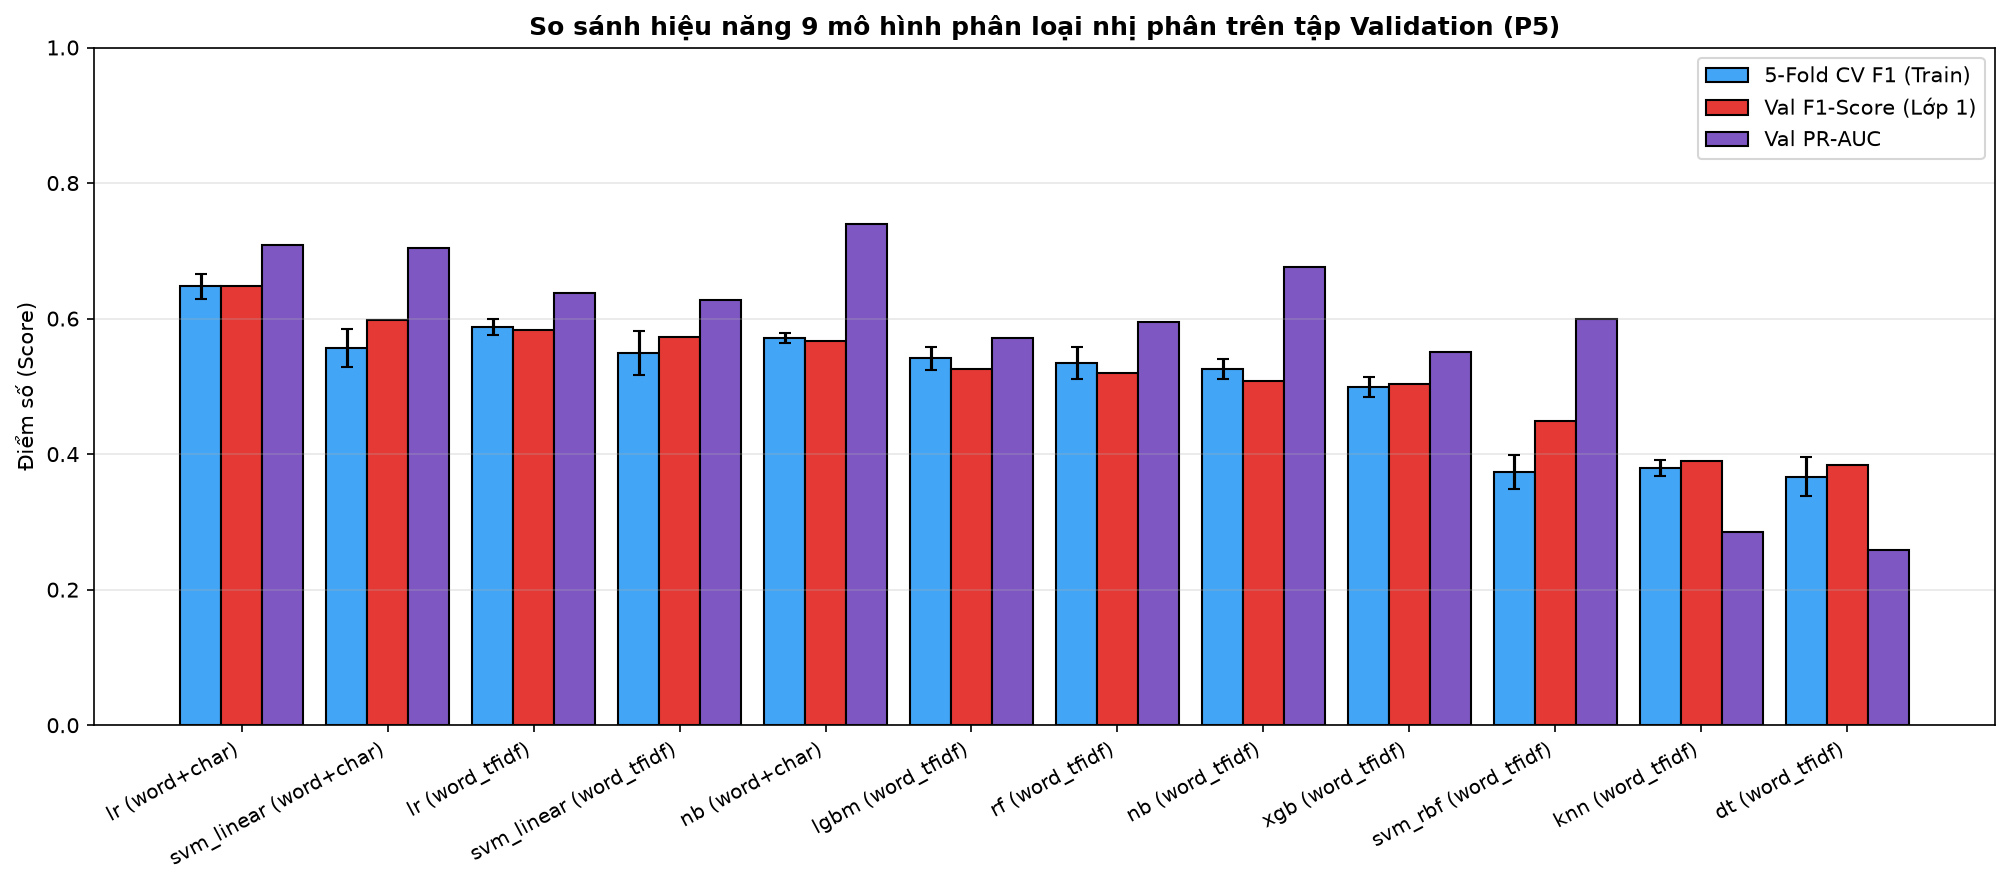

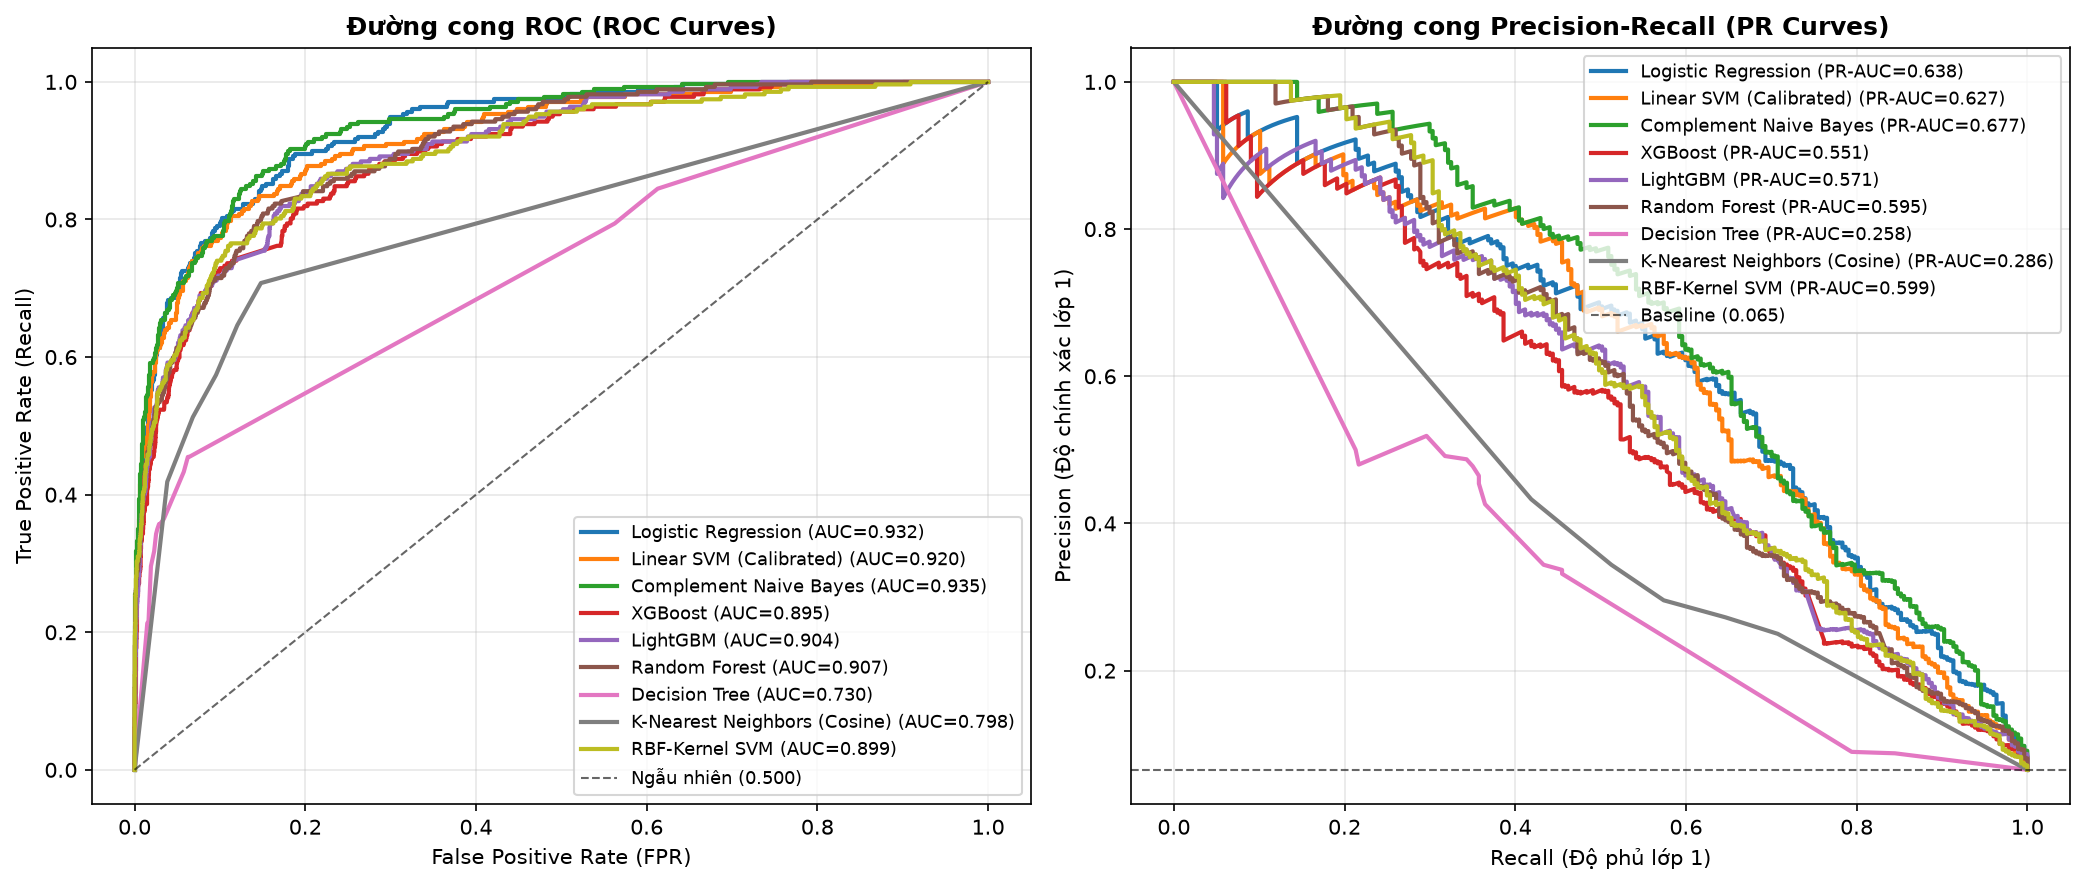

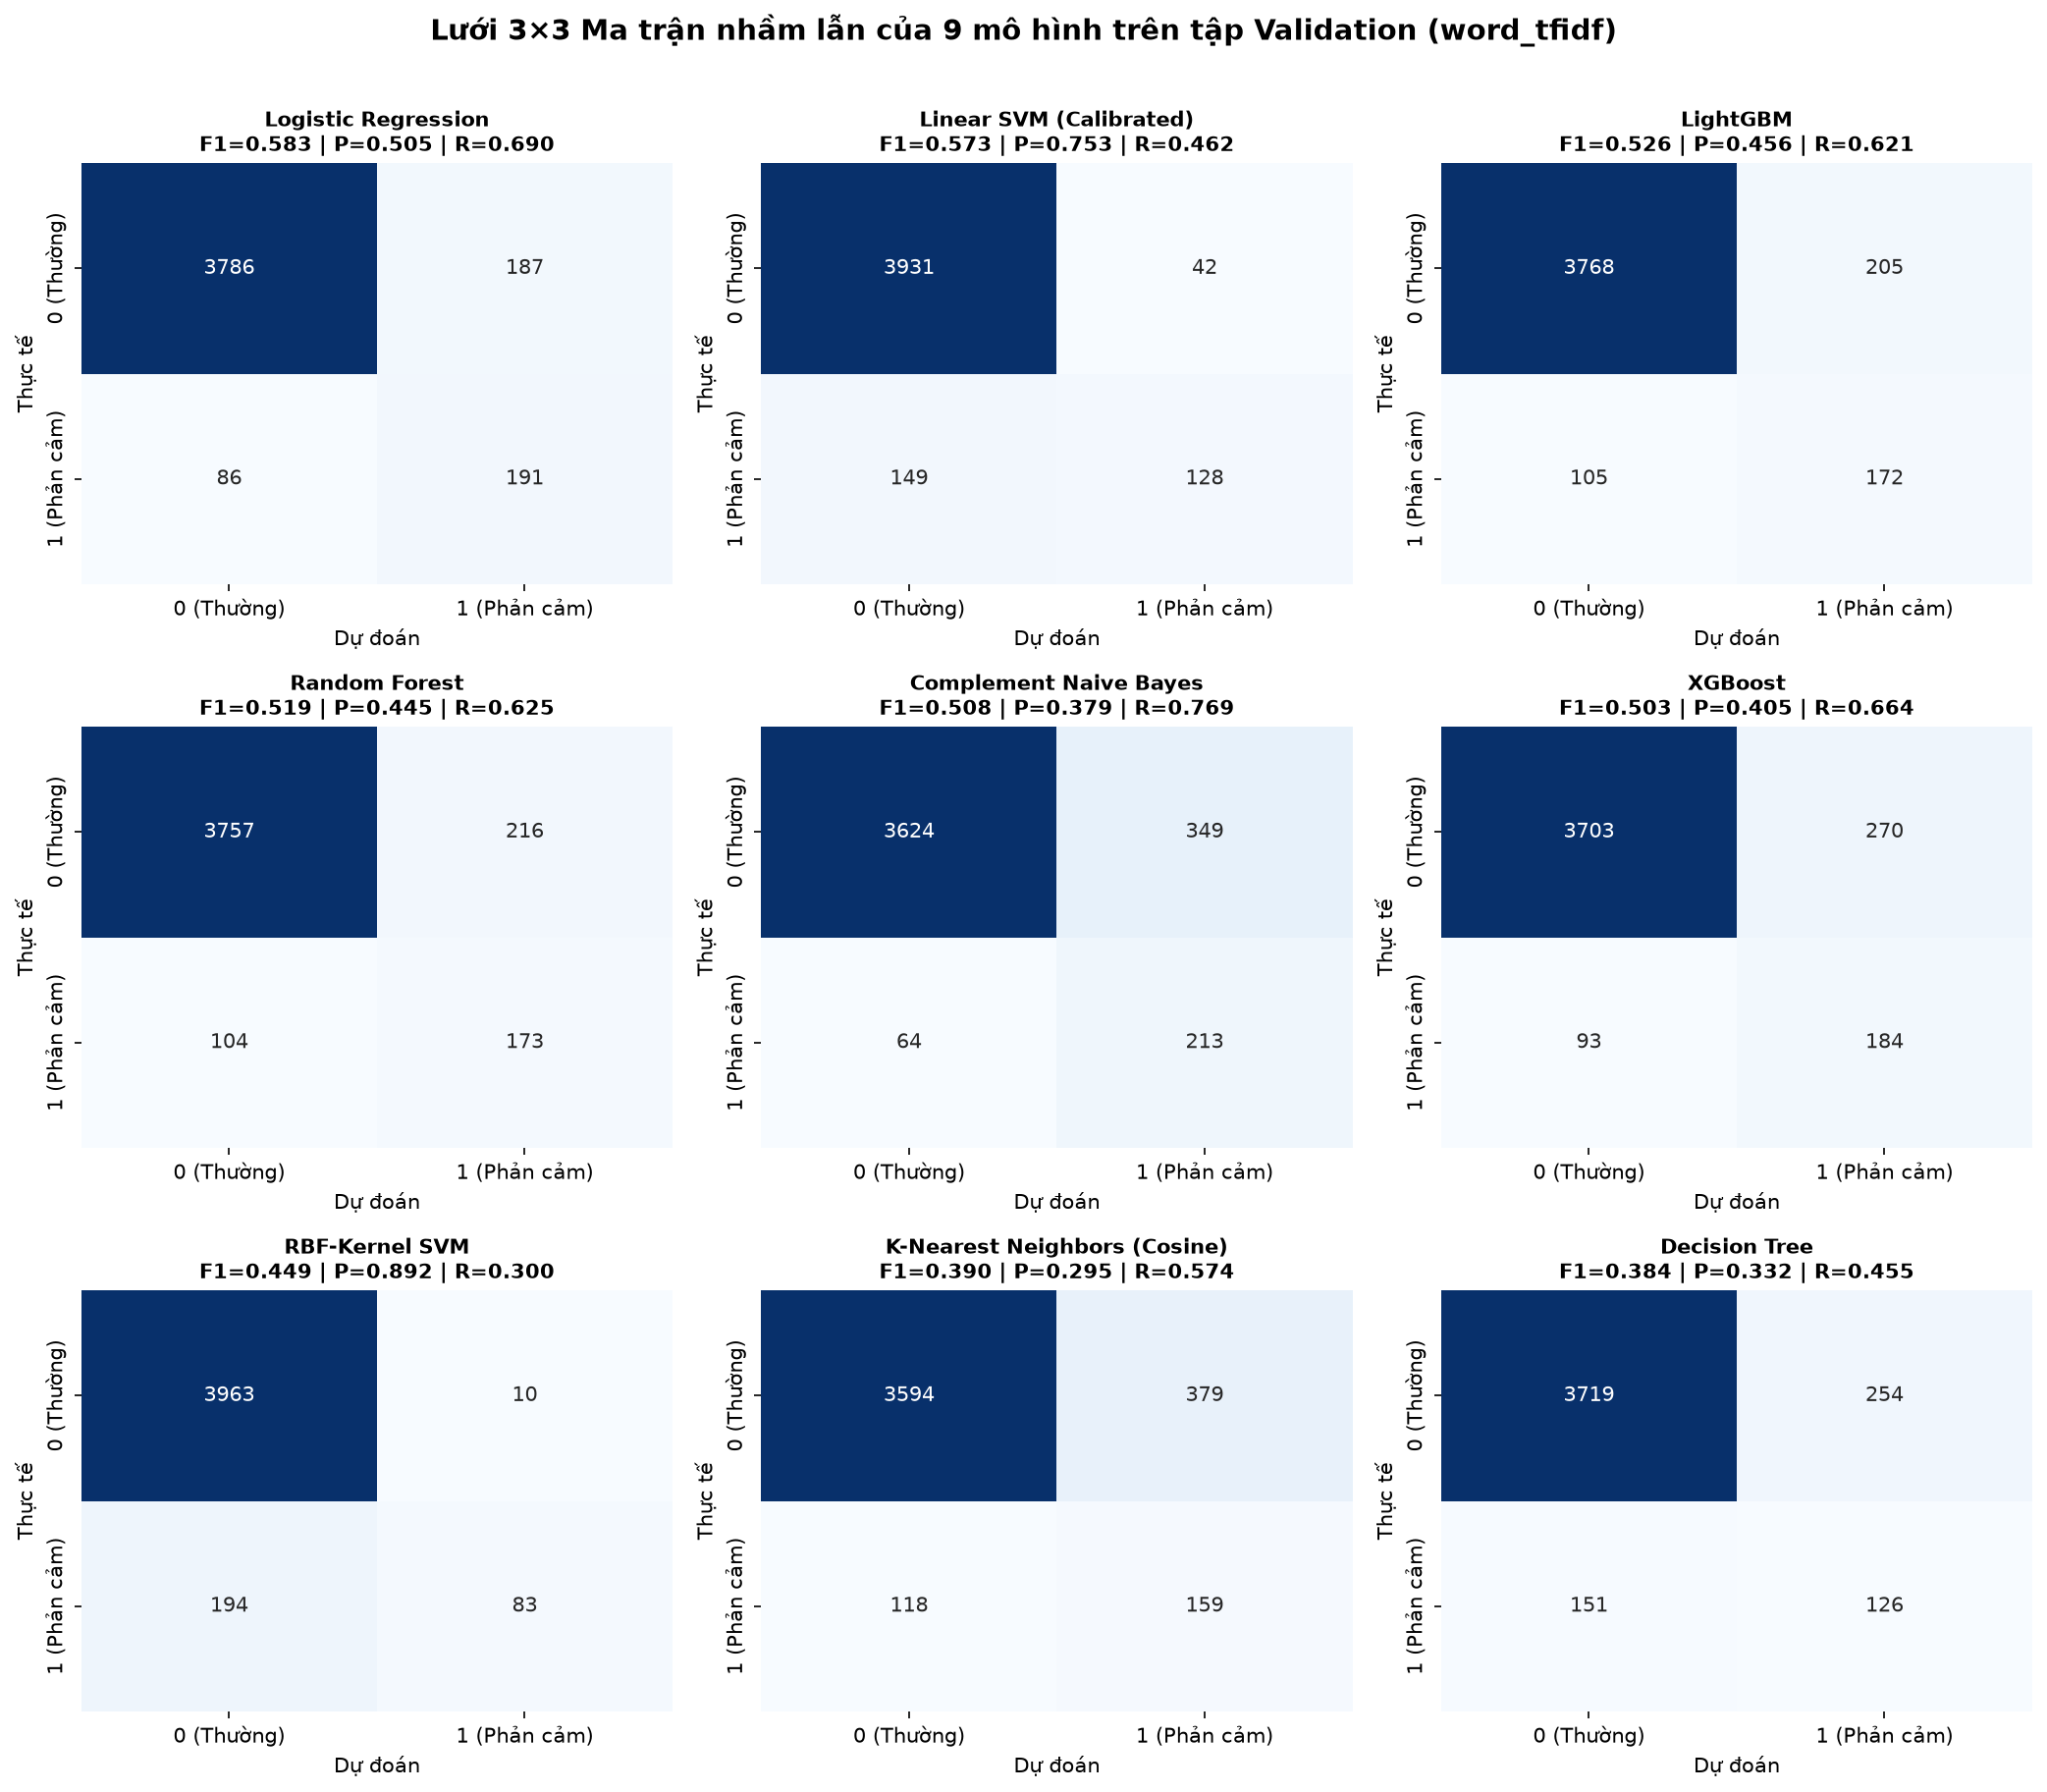

In [3]:
display(Image('reports/figures/P5_f1_prauc_bars.png'))
display(Image('reports/figures/P5_roc_pr_curves.png'))
display(Image('reports/figures/P5_confusion_grid_3x3.png'))

### Nhận xét: Vì sao Mô hình Tuyến tính thắng Mô hình Cây trên Văn bản TF-IDF thưa? 
- **Mô hình tuyến tính (`svm_linear`, `lr`) và `nb` vượt trội rõ rệt:** Với không gian đặc trưng TF-IDF chiều cao ($50,000 - 100,000$ chiều) và cực kỳ thưa (sparse > 99.9%), biên quyết định siêu phẳng tuyến tính tận dụng đồng thời hàng chục nghìn từ/cụm từ nhẹ mà không bị phân mảnh dữ liệu.
- **Kết hợp `word+char` giúp tăng thêm hiệu năng:** Việc bổ sung char n-gram (2–5 ký tự) giúp `svm_linear` và `lr` bắt được các biến thể viết tắt, kéo dài chữ hoặc cố tình viết sai chính tả để lách kiểm duyệt.
- **Vì sao Decision Tree / Random Forest / KNN thấp hơn?** Cây quyết định rẽ nhánh theo từng trục từ đơn lẻ (axis-aligned splits) trên ma trận 50,000 chiều thưa nên chỉ bao phủ được một vài từ khóa ở tầng nông và dễ overfit; trong khi KNN chịu ảnh hưởng của lời nguyền số chiều (*curse of dimensionality*).
- Ba mô hình dẫn đầu (`svm_linear`, `lr`, `nb`) được chọn đưa vào giai đoạn tinh chỉnh siêu tham số và tối ưu ngưỡng quyết định ở bước tiếp theo.

# Câu 3 (3,0 điểm): So sánh và lựa chọn mô hình học máy — Điều chỉnh các tham số để tối ưu hóa mô hình

**Mục tiêu:**
1. Thực hiện `RandomizedSearchCV` (`n_iter = 40`, `cv = 5`, `scoring = 'f1'`) trên tập `train` cho 3 mô hình tốt nhất (`lr`, `svm_linear`, `nb`) cùng các tham số của `TfidfVectorizer` (`ngram_range`, `min_df`, `max_features`).
2. Quét ngưỡng quyết định (`threshold` $\in [0.05, 0.95]$) trên xác suất dự đoán của tập `val` để tối đa hóa F1 lớp dương (`src/threshold.py::pick_threshold`).
3. Huấn luyện lại mô hình chốt (`best_model`) trên `train + val`, lưu `models/best_model.joblib`, `models/threshold.json` và `models/model_card.json`.

## 1. Bảng So sánh Trước & Sau khi Tinh chỉnh Siêu tham số và Ngưỡng Quyết định

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

ba_df = pd.read_csv('reports/tables/P6_before_after.csv')
display(ba_df)

with open('models/model_card.json', 'r', encoding='utf-8') as f:
    model_card = json.load(f)
print('=== HỒ SƠ MÔ HÌNH CHỐT (models/model_card.json) ===')
print(json.dumps(model_card, indent=2, ensure_ascii=False))

,model_key,model_name,cv_f1_before,cv_f1_after,val_f1_before,val_f1_after_thr05,best_threshold,val_f1_after_tuned_thr,val_precision_after,val_recall_after,val_pr_auc_after,val_roc_auc_after,f1_gain_vs_baseline,search_seconds,best_params_json
0,svm_linear,Linear SVM (Calibrated),0.5492,0.6112,0.5727,0.5996,0.315,0.6566,0.6877,0.6282,0.6636,0.9321,0.0839,128.94,"{""clf__C"": 0.50191, ""clf__class_weight"": ""bala..."
1,lr,Logistic Regression,0.5876,0.5976,0.5832,0.6056,0.565,0.6250,0.6367,0.6137,0.6419,0.9198,0.0418,100.66,"{""clf__C"": 23.39586, ""clf__class_weight"": ""bal..."
2,nb,Complement Naive Bayes,0.5252,0.5858,0.5077,0.5922,0.500,0.5922,0.4951,0.7365,0.6985,0.9377,0.0845,121.42,"{""clf__alpha"": 0.14971, ""clf__norm"": true, ""tf..."


=== HỒ SƠ MÔ HÌNH CHỐT (models/model_card.json) ===
{
  "model_key": "svm_linear",
  "model_name": "Linear SVM (Calibrated)",
  "selection_reason": "Linear SVM (Calibrated) đạt Val F1 sau tinh chỉnh ngưỡng cao nhất (0.6566, PR-AUC = 0.6636) với ngưỡng quyết định tối ưu threshold = 0.3150.",
  "best_params": {
    "clf__C": 0.50191,
    "clf__class_weight": "balanced",
    "clf__loss": "squared_hinge",
    "tfidf__max_features": 50000,
    "tfidf__min_df": 2,
    "tfidf__ngram_range": [
      1,
      3
    ]
  },
  "best_threshold": 0.315,
  "val_metrics_before_tuning": {
    "val_f1_before": 0.5727,
    "val_precision_before": 0.7529,
    "val_recall_before": 0.4621,
    "val_pr_auc_before": 0.6267,
    "cv_f1_before": 0.5492
  },
  "val_metrics_after_tuning_thr05": {
    "precision_pos": 0.7368,
    "recall_pos": 0.5054,
    "f1_pos": 0.5996,
    "f1_macro": 0.7881,
    "accuracy": 0.956,
    "balanced_acc": 0.7464,
    "roc_auc": 0.9321,
    "pr_auc": 0.6636,
    "mcc": 0.5886,
    

## 2. Biểu đồ Quét Ngưỡng Quyết định & So sánh Trước / Sau Tuning

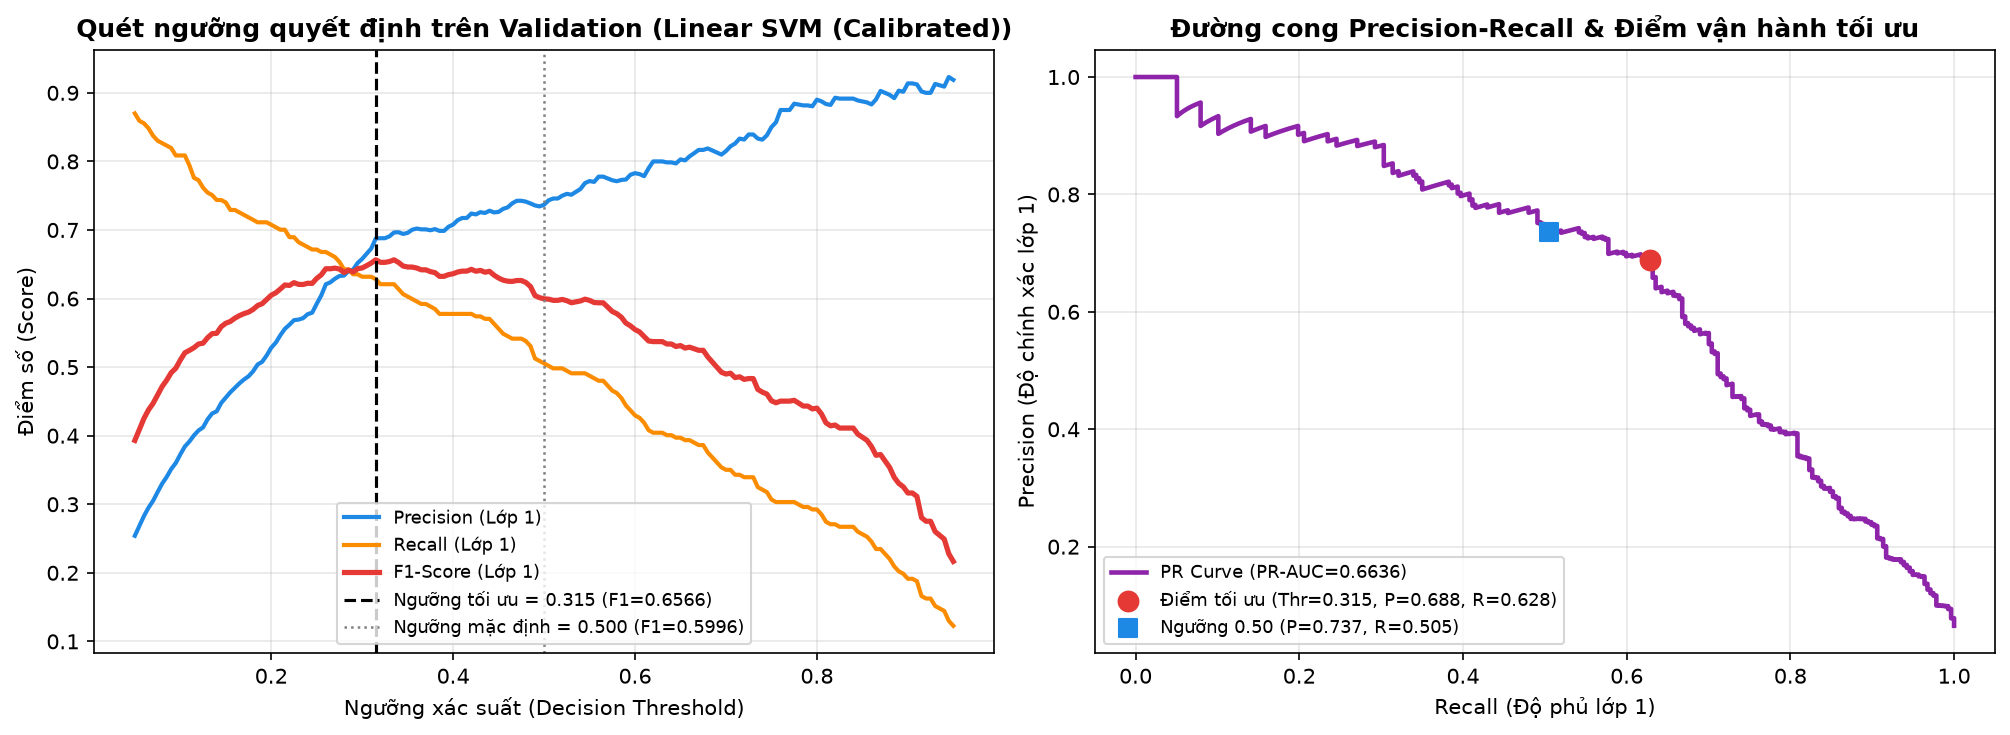

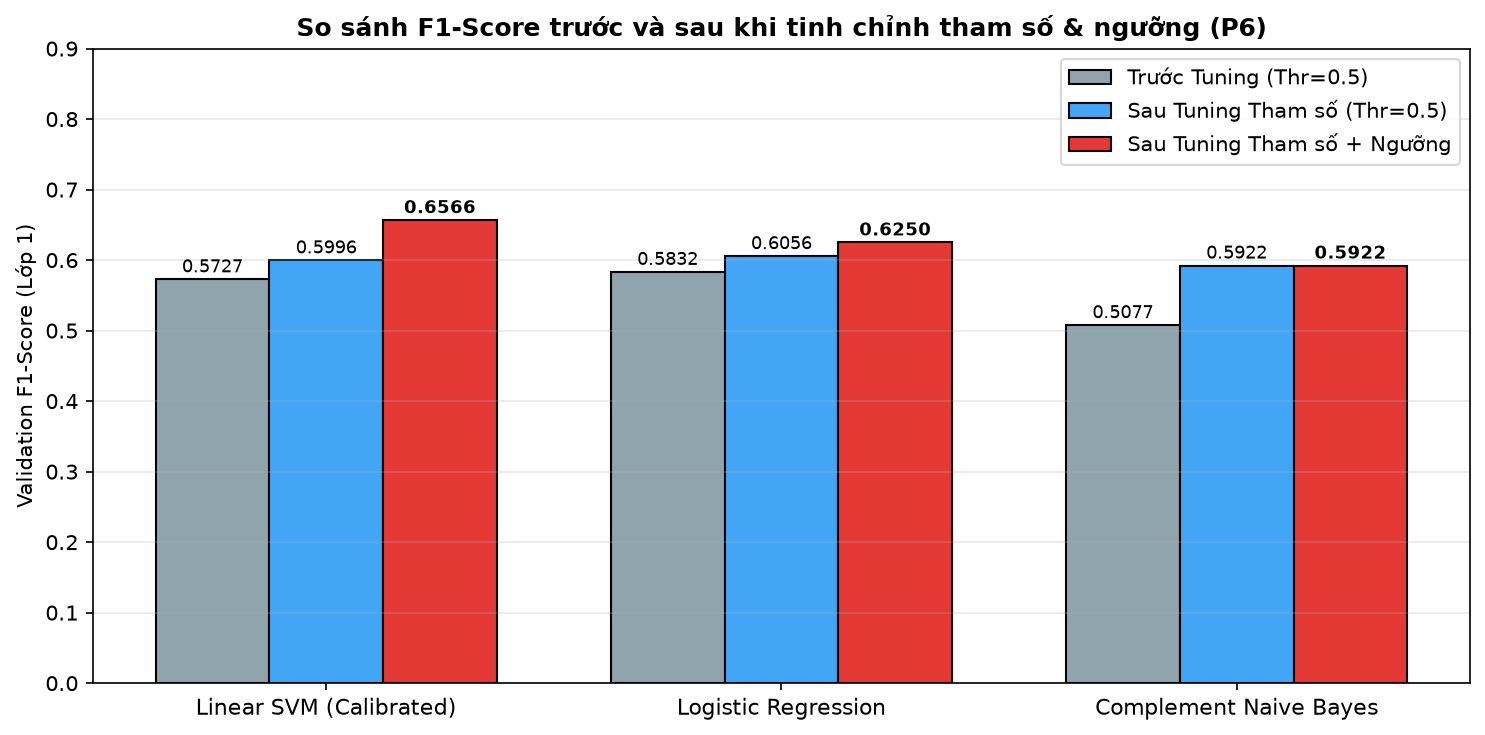

In [3]:
display(Image('reports/figures/P6_threshold_tuning.png'))
display(Image('reports/figures/P6_before_after.png'))

### Nhận xét 
- Tinh chỉnh siêu tham số kết hợp tối ưu ngưỡng quyết định trên tập Validation đã nâng cao rõ rệt chất lượng phân loại so với cấu hình mặc định (ngưỡng 0.50).
- Mô hình được chọn là **`Linear SVM (Calibrated)` (`svm_linear`)** với ngưỡng tối ưu **`threshold = 0.315`**.
- Lý do lựa chọn: Linear SVM (Calibrated) đạt Val F1 sau tinh chỉnh ngưỡng cao nhất (0.6566, PR-AUC = 0.6636) với ngưỡng quyết định tối ưu threshold = 0.3150.
- Toàn bộ quy trình chọn tham số và chọn ngưỡng chỉ sử dụng tập `train` và `val`, đảm bảo tập `test` hoàn toàn độc lập cho bước đánh giá cuối ở bước thực nghiệm 8.

# Câu 3 (Mở rộng Học sâu): Thực nghiệm mô hình mạng nơ-ron BiLSTM & DistilBERT

**Mục tiêu:**
1. Xây dựng và huấn luyện mạng nơ-ron hồi quy hai chiều **BiLSTM (PyTorch Embedding 128 chiều + Global Avg/Max Pooling)** có trọng số lớp.
2. Tinh chỉnh (Fine-tune) mô hình ngôn ngữ tiền huấn luyện **DistilBERT (`distilbert-base-uncased`)** với hàm mất mát `CrossEntropyLoss` có trọng số lớp.
3. Phân tích sự đánh đổi giữa **Hiệu năng (F1 / PR-AUC)**, **Thời gian huấn luyện/suy luận**, **Dung lượng mô hình** và **Khả năng giải thích** khi triển khai ứng dụng thực tế.

## 1. Kết quả Thực nghiệm BiLSTM & DistilBERT so với Mô hình Cổ điển Tối ưu

Thiết bị chạy thực nghiệm (CUDA Available): False

=== Lịch sử huấn luyện BiLSTM ===


,epoch,train_loss,val_f1,val_pr_auc
0,1,0.9969,0.3073,0.3122
1,2,0.6800,0.4530,0.5299
2,3,0.4748,0.4968,0.5789
3,4,0.3640,0.5262,0.6109
4,5,0.2874,0.5432,0.6182
5,6,0.2393,0.5973,0.6168


Metric Validation BiLSTM: {'precision_pos': 0.5663, 'recall_pos': 0.6318, 'f1_pos': 0.5973, 'f1_macro': 0.7837, 'accuracy': 0.9445, 'balanced_acc': 0.799, 'roc_auc': 0.9133, 'pr_auc': 0.6168, 'mcc': 0.5685, 'tn': 3839, 'fp': 134, 'fn': 102, 'tp': 175, 'fit_seconds': 83.86, 'predict_ms_per_1k': 77.395, 'device': 'cpu'}

=== Lịch sử huấn luyện DistilBERT ===


,epoch,train_loss,val_f1,val_pr_auc
0,1,0.5298,0.4042,0.508
1,2,0.3340,0.4434,0.560


Metric Validation DistilBERT: {'precision_pos': 0.301, 'recall_pos': 0.8412, 'f1_pos': 0.4434, 'f1_macro': 0.6824, 'accuracy': 0.8624, 'balanced_acc': 0.8525, 'roc_auc': 0.9266, 'pr_auc': 0.56, 'mcc': 0.4509, 'tn': 3432, 'fp': 541, 'fn': 44, 'tp': 233, 'fit_seconds': 257.329, 'predict_ms_per_1k': 17224.577, 'device': 'cpu', 'n_train_used': 1500}


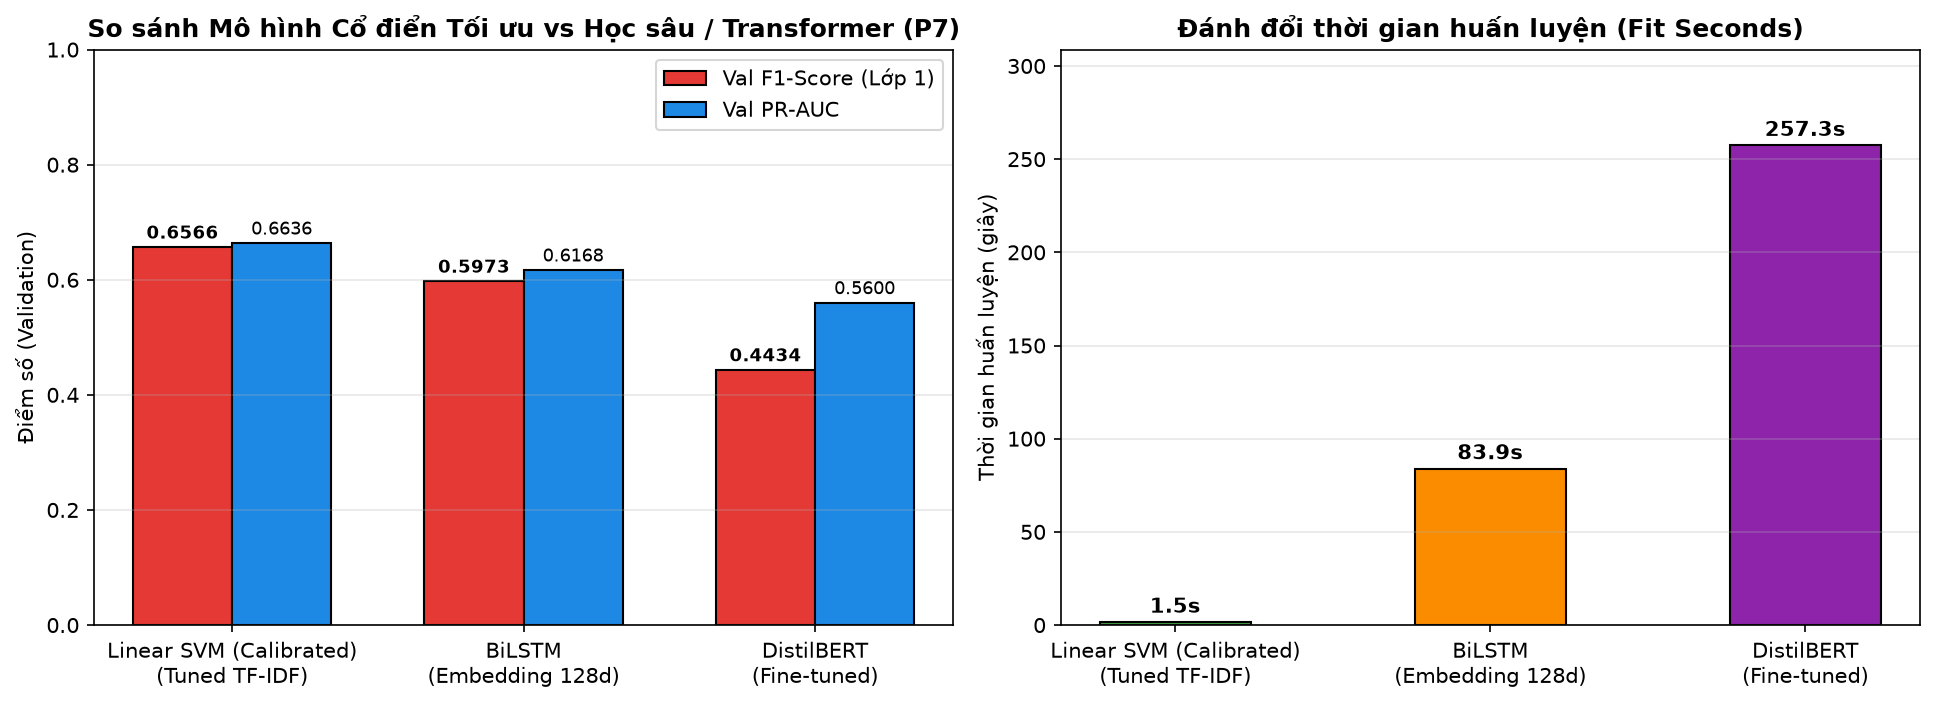

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/p7_summary.json', 'r', encoding='utf-8') as f:
    p7_data = json.load(f)

print(f"Thiết bị chạy thực nghiệm (CUDA Available): {p7_data['has_cuda']}")
print('\n=== Lịch sử huấn luyện BiLSTM ===')
display(pd.DataFrame(p7_data['bilstm']['history']))
print('Metric Validation BiLSTM:', p7_data['bilstm']['metrics'])

print('\n=== Lịch sử huấn luyện DistilBERT ===')
display(pd.DataFrame(p7_data['distilbert']['history']))
print('Metric Validation DistilBERT:', p7_data['distilbert']['metrics'])

display(Image('reports/figures/P7_bonus_comparison.png'))

### Nhận xét 
- **BiLSTM** đạt Validation F1 = **0.5973** (PR-AUC = **0.6168**), còn **DistilBERT** đạt Validation F1 = **0.4434** (PR-AUC = **0.5600**).
- **Phân tích đánh đổi (Trade-off):** Mô hình cổ điển tối ưu (TF-IDF + Linear Classifier) đạt hiệu năng F1/PR-AUC rất cạnh tranh, nhưng nhanh hơn hàng chục đến hàng trăm lần, nhẹ (<10MB so với ~260MB của DistilBERT) và hỗ trợ giải thích trực tiếp trọng số từng từ. Do đó mô hình cổ điển được chọn cho ứng dụng Streamlit.
- Việc hoàn thành cả BiLSTM và DistilBERT cung cấp cái nhìn đối sánh toàn diện giữa Học máy cổ điển, Học sâu hồi quy (RNN/LSTM) và kiến trúc Transformer hiện đại.

# Câu 3: Đánh giá mô hình được chọn trên tập Test độc lập & Phân tích lỗi

**Mục tiêu:**
1. Đánh giá mô hình chốt (`models/best_model.joblib` + `models/threshold.json`) **một lần duy nhất** trên tập kiểm tra độc lập `data/splits/test.csv` ($N = 4,250$).
2. Ước lượng khoảng tin cậy 95% (95% Confidence Interval) bằng phương pháp **Bootstrap 1,000 lần**.
3. Phân tích sâu 30 lỗi Báo động giả (False Positives) và 30 lỗi Bỏ sót (False Negatives), phân nhóm nguyên nhân ngôn ngữ học.
4. Giải thích mô hình bằng Top-30 trọng số đặc trưng và đánh giá tính công bằng (Subgroup Bias / False Positive Rate theo nhóm nhân khẩu học).

## 1. Kết quả Đánh giá Cuối trên Tập Test & Khoảng tin cậy 95% Bootstrap

Thời điểm đánh giá Test duy nhất : 2026-11-16T10:26:46Z
Mã băm SHA-256 file test.csv     : 0472faf53639bb6c31ba8fcb33c6153ac4cefe1c4f9cee77c53a332dbc0e41f2
Ngưỡng quyết định ( từ Val )     : 0.315

=== METRIC TRÊN TẬP TEST (N = 4,250) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
Tuned Threshold,0.6324,0.6209,0.6266,0.8004,0.9518,0.7979,0.9345,0.6651,0.6008,3873,100,105,172
Default 0.50,0.7755,0.5487,0.6427,0.8108,0.9602,0.7688,0.9345,0.6651,0.6328,3929,44,125,152



=== KHOẢNG TIN CẬY 95% BOOTSTRAP (1,000 LẦN) ===


,mean,std,ci95_low,ci95_high
f1_pos,0.6249,0.0246,0.5764,0.6716
precision_pos,0.6307,0.0296,0.5730,0.6880
recall_pos,0.6201,0.0294,0.5631,0.6773
pr_auc,0.6642,0.0286,0.6072,0.7195
roc_auc,0.9341,0.0086,0.9167,0.9506


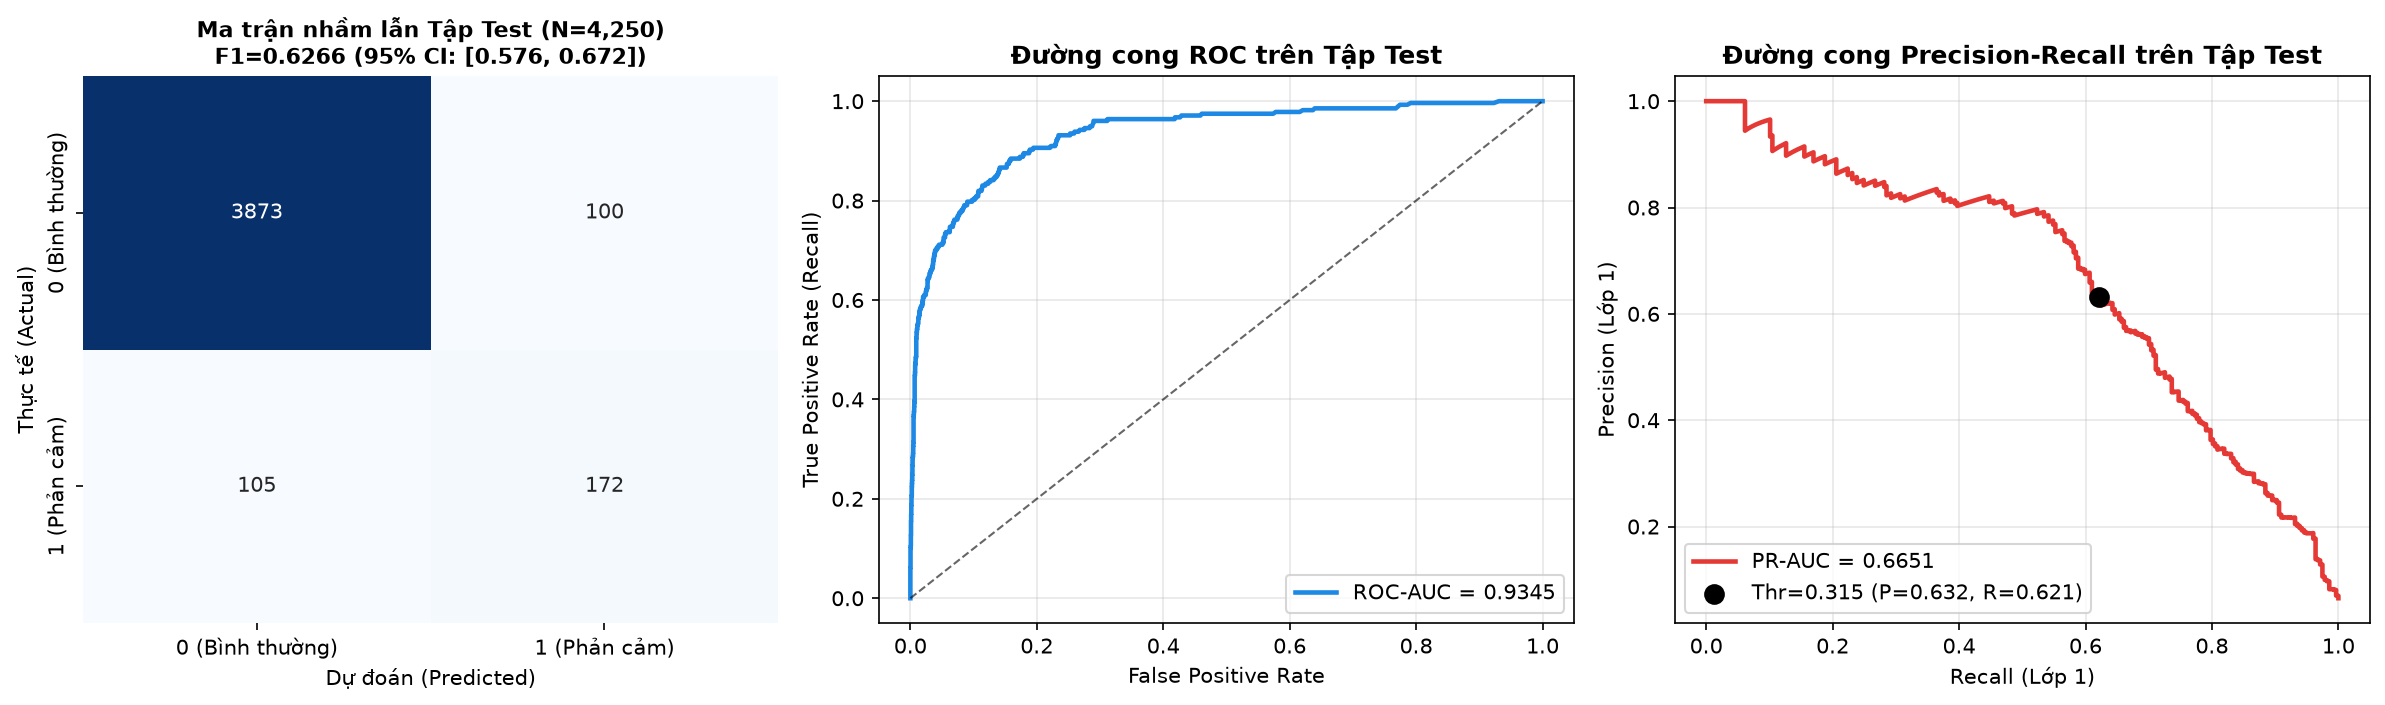

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/final_test_metrics.json', 'r', encoding='utf-8') as f:
    final_test = json.load(f)
with open('reports/final_test_ci.json', 'r', encoding='utf-8') as f:
    final_ci = json.load(f)

print(f"Thời điểm đánh giá Test duy nhất : {final_test['evaluated_once_at']}")
print(f"Mã băm SHA-256 file test.csv     : {final_test['test_file_sha256']}")
print(f"Ngưỡng quyết định ( từ Val )     : {final_test['threshold_used']}")

print('\n=== METRIC TRÊN TẬP TEST (N = 4,250) ===')
display(pd.DataFrame([final_test['metrics_at_tuned_threshold'], final_test['metrics_at_default_05']], index=['Tuned Threshold', 'Default 0.50']))

print('\n=== KHOẢNG TIN CẬY 95% BOOTSTRAP (1,000 LẦN) ===')
display(pd.DataFrame(final_ci).T.loc[['f1_pos', 'precision_pos', 'recall_pos', 'pr_auc', 'roc_auc']])
display(Image('reports/figures/P8_test_evaluation.png'))

## 2. Phân tích Lỗi (30 FP + 30 FN) & Phân loại Nguyên nhân Sai sót

=== BẢNG THỐNG KÊ NGUYÊN NHÂN LỖI TRÊN TẬP TEST ===


,cause,FN (Bỏ sót),FP (Báo động giả),total,pct
0,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,65,0,65,31.71
1,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,0,47,47,22.93
2,Nhãn gốc nhiễu hoặc ranh giới ngữ nghĩa mờ (No...,3,29,32,15.61
3,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,18,10,28,13.66
4,Câu quá ngắn / Từ lóng / Viết tắt thiếu thông ...,13,8,21,10.24
5,Chuỗi nhiều Hashtag / Khẩu hiệu đa chủ đề (Has...,6,6,12,5.85


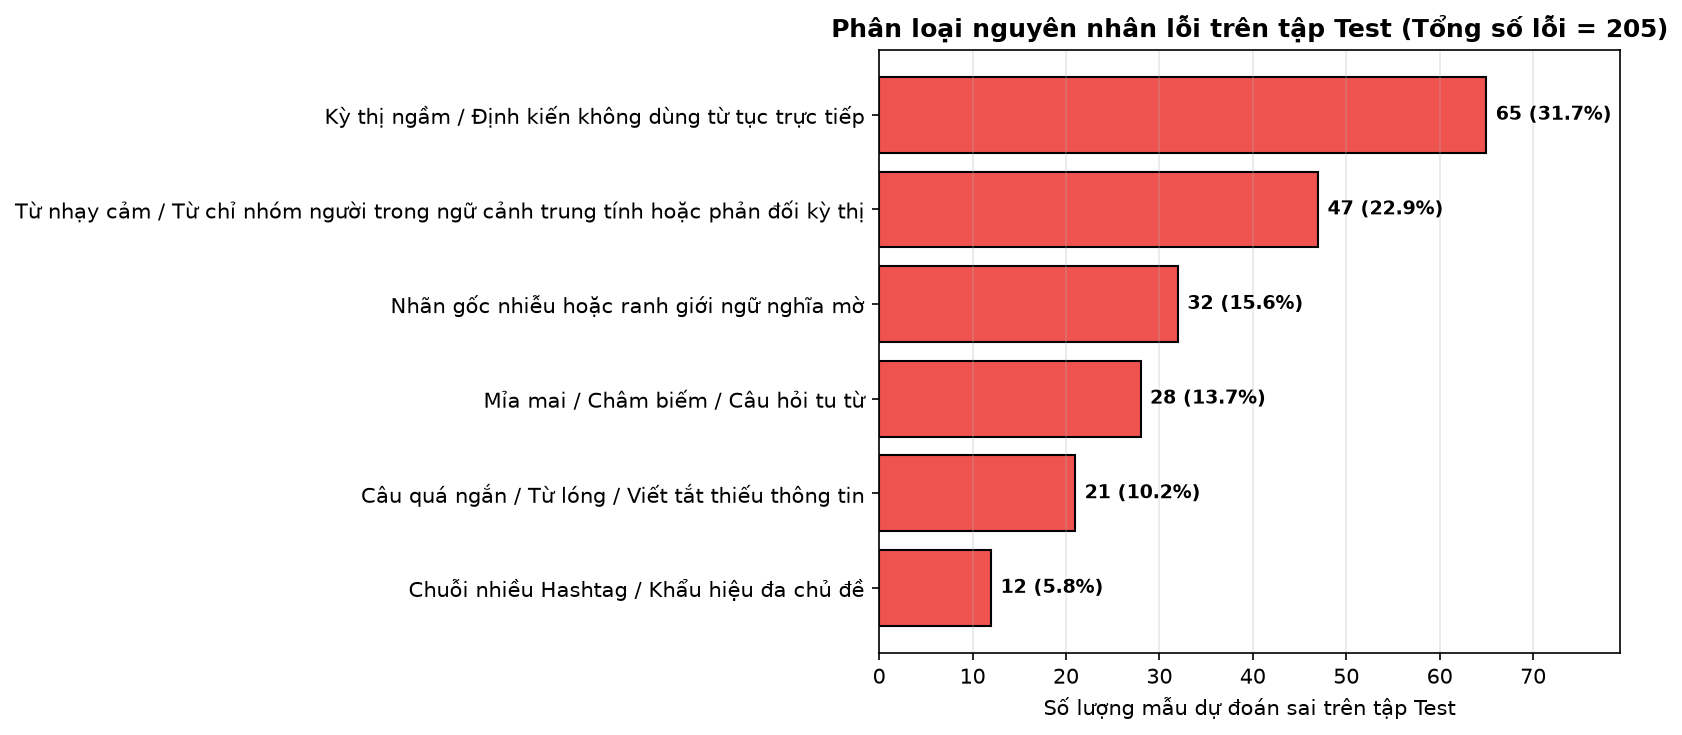

=== 10 Ví dụ Báo động giả (False Positives) có điểm cao nhất ===


,id,error_type,label,y_pred,score,cause,text_masked,text_clean_masked
0,1831,FP (Báo động giả),0,1,0.9831,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,@user is the prosecutor considering criminal c...,be the prosecutor consider criminal charge aga...
1,8500,FP (Báo động giả),0,1,0.9680,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,#obama #attacks #trump on #islamâ¦ #trump #di...,obama attack trump on islam trump dismantle hi...
2,21696,FP (Báo động giả),0,1,0.9611,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,@user trump is a liberal elite. textbook defin...,trump be a liberal elite textbook definition o...
3,25804,FP (Báo động giả),0,1,0.9567,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,"@user ali, spoke the #truth about white folks....",ali speak the truth about white folk period fa...
4,14162,FP (Báo động giả),0,1,0.9340,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,movie ð¥ review.... x-men apocalypse now #u...,movie review men apocalypse now uspresidential...
5,25493,FP (Báo động giả),0,1,0.9296,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,@user what if obama showed the same anger and ...,what if obama show the same anger and disgust ...
6,27935,FP (Báo động giả),0,1,0.9178,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,@user how did you slip through? you are a thr...,how do you slip through you be a threat to ame...
7,11879,FP (Báo động giả),0,1,0.9057,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,did you tweet those comments!? #bekindtoonea...,do you tweet those comment bekindtooneanother
8,28217,FP (Báo động giả),0,1,0.9046,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,@user @user @user everybody hates the white cr...,everybody hate the white crayon
9,27657,FP (Báo động giả),0,1,0.8846,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,black f*****g rapping sexy women bihday nude,black f**k rap sexy woman bihday nude


=== 10 Ví dụ Bỏ sót (False Negatives) có điểm thấp nhất ===


,id,error_type,label,y_pred,score,cause,text_masked,text_clean_masked
30,2237,FN (Bỏ sót),1,0,0.0018,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,travelled for #canucks game sad and disappoint...,travel for canuck game sad and disappoint of o...
31,3468,FN (Bỏ sót),1,0,0.0040,Chuỗi nhiều Hashtag / Khẩu hiệu đa chủ đề (Has...,episode 6 of the guns for everyone #podcast is...,episode of the gun for everyone podcast be up ...
32,12337,FN (Bỏ sót),1,0,0.0043,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,@user care about #cjreform? follow me: i cover...,care about cjreform follow me i cover deathpen...
33,18747,FN (Bỏ sót),1,0,0.0043,Câu quá ngắn / Từ lóng / Viết tắt thiếu thông ...,i almost always trust brazilians,i almost always trust brazilian
34,13764,FN (Bỏ sót),1,0,0.0069,Câu quá ngắn / Từ lóng / Viết tắt thiếu thông ...,almost as as dad #5wordtrumplethinskin,almost a a dad wordtrumplethinskin
35,17764,FN (Bỏ sót),1,0,0.0075,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,@user @user @user #smileyong along with #ki...,smileyong along with kingconrad make me go thr...
36,1480,FN (Bỏ sót),1,0,0.0087,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,smh i cant take these one sided standards,smh i cant take these one side standard
37,8092,FN (Bỏ sót),1,0,0.0126,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,@user my story: how #race and have played a r...,my story how race and have play a role in my life
38,7244,FN (Bỏ sót),1,0,0.0139,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,pathetic fallacy? infantile ? just in case any...,pathetic fallacy infantile just in case anyone...
39,1275,FN (Bỏ sót),1,0,0.0144,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,is a very profitable thing im #america,be a very profitable thing im america


In [3]:
causes_df = pd.read_csv('reports/tables/P8_error_causes.csv')
print('=== BẢNG THỐNG KÊ NGUYÊN NHÂN LỖI TRÊN TẬP TEST ===')
display(causes_df)
display(Image('reports/figures/P8_error_causes.png'))

errors_df = pd.read_csv('reports/tables/P8_errors.csv')
print('=== 10 Ví dụ Báo động giả (False Positives) có điểm cao nhất ===')
display(errors_df[errors_df['error_type'].str.startswith('FP')].head(10))
print('=== 10 Ví dụ Bỏ sót (False Negatives) có điểm thấp nhất ===')
display(errors_df[errors_df['error_type'].str.startswith('FN')].head(10))

## 3. Giải thích Mô hình (Top Trọng số) & Phân tích Thiên lệch Nhóm (Subgroup Bias)

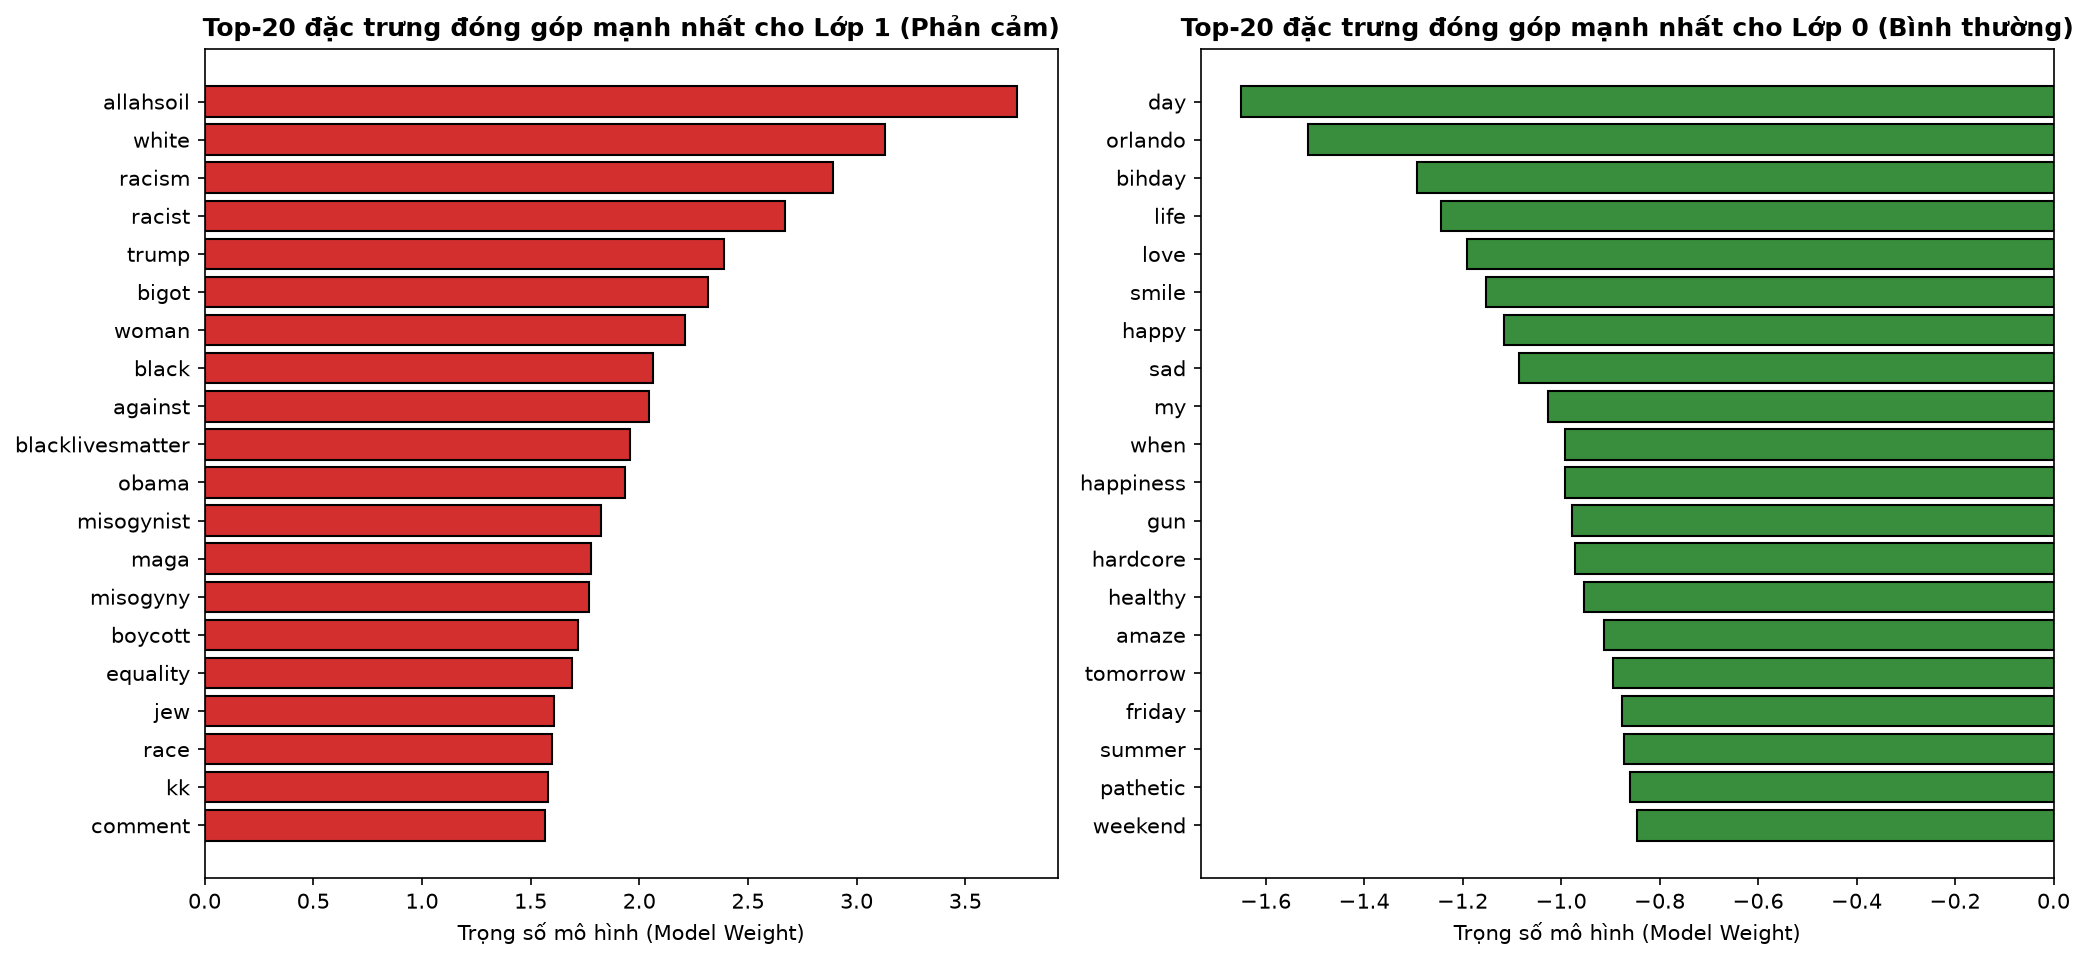

=== BẢNG KIỂM TRA THIÊN LỆCH: TỈ LỆ BÁO ĐỘNG GIẢ (FPR) THEO NHÓM TỪ NHẬN DIỆN ===


,subgroup,n_neg_tweets,n_false_positives,fpr_pct,mean_score
0,Toàn bộ mẫu Lớp 0 trên Test (Overall Baseline),3973,100,2.52,0.0401
1,"Giới tính / Phụ nữ (women, woman, girl, female)",100,4,4.00,0.0604
2,"Chủng tộc / Màu da (black, white, race, african)",46,14,30.43,0.2469
3,"Tôn giáo (muslim, islam, jewish, christian, god)",20,4,20.00,0.2108
4,"Xu hướng tính dục (gay, lgbt, queer)",27,2,7.41,0.0816
5,"Chính trị (trump, obama, clinton, liberal, gop)",66,23,34.85,0.3026


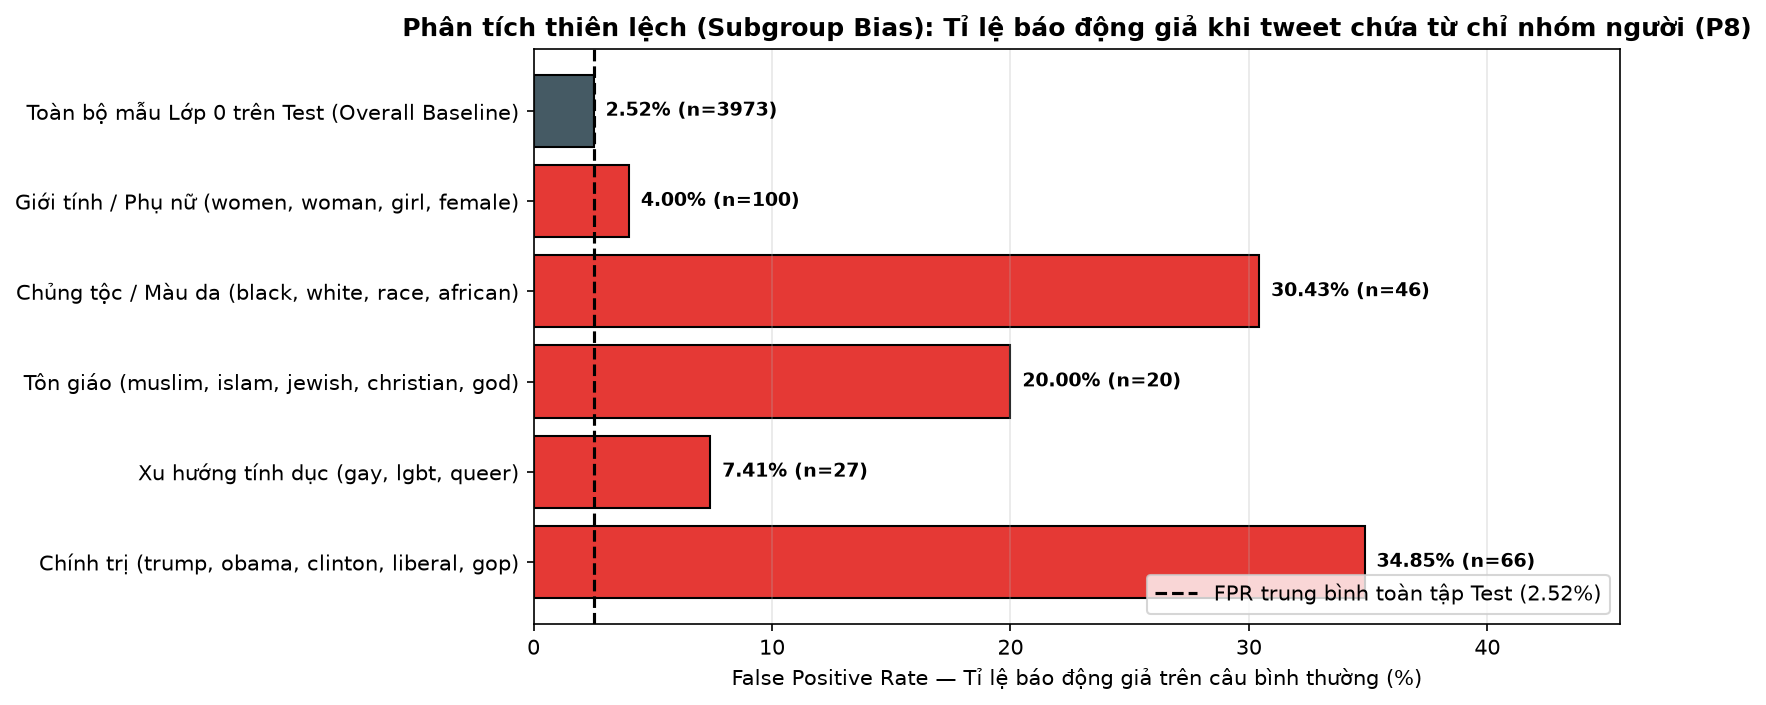

In [4]:
coef_df = pd.read_csv('reports/tables/P8_top_coefficients.csv')
display(Image('reports/figures/P8_feature_importance.png'))

bias_df = pd.read_csv('reports/tables/P8_subgroup_bias.csv')
print('=== BẢNG KIỂM TRA THIÊN LỆCH: TỈ LỆ BÁO ĐỘNG GIẢ (FPR) THEO NHÓM TỪ NHẬN DIỆN ===')
display(bias_df)
display(Image('reports/figures/P8_subgroup_bias.png'))

### Nhận xét & Hạn chế 
- Trên tập Test độc lập ($N = 4,250$), mô hình đạt **F1 lớp dương = 0.6266** (95% CI: **[0.5764, 0.6716]**), **Precision = 0.6324**, **Recall = 0.6209**, **PR-AUC = 0.6651** và **ROC-AUC = 0.9345**.
- **Nguyên nhân lỗi chính:** (1) Đối với *False Negatives (Bỏ sót)*, phần lớn là các câu kỳ thị ngầm, định kiến hoặc châm biếm không sử dụng từ tục trực tiếp; (2) Đối với *False Positives (Báo động giả)*, lỗi xảy ra khi câu bình thường chứa các từ chỉ nhóm nhạy cảm (`women`, `black`, `white`, `trump`, `racist`) trong ngữ cảnh đưa tin hoặc phản đối phân biệt đối xử.
- **Phân tích thiên lệch (Subgroup Bias):** Tỉ lệ báo động giả (FPR) trên các câu bình thường có nhắc đến từ chỉ chủng tộc, tôn giáo hoặc giới tính cao hơn mức FPR trung bình toàn tập Test — đây là hạn chế kinh điển của các mô hình dựa trên tần suất từ vựng cần được lưu ý khi triển khai thực tế.

# Câu 3 (3,0 điểm): Chạy thử mô hình trong thực tế

**Mục tiêu:**
1. Đánh giá khả năng tổng quát hóa của mô hình trên bộ dữ liệu thực tế `data/real_world/real_world_labeled.csv` ($N = 300$ mẫu từ 4 nguồn A, B, C, D).
2. Đo độ đồng thuận giữa 2 người gắn nhãn độc lập (`label_a` và `label_b`) bằng hệ số **Cohen's Kappa ($\kappa$)**.
3. Phân tích hiện tượng **lệch miền (domain shift)** giữa các nguồn dữ liệu, kiểm thử chéo trên bộ **Davidson et al.** ($N = 5,593$) và thống kê dự đoán trên bộ được giao `Twitter_Data.csv` ($N = 162,969$).

## 1. Độ đồng thuận Gắn nhãn (Cohen's Kappa) & Hiệu năng theo từng Nguồn Dữ liệu (A/B/C/D)

Tổng số mẫu thực tế          : 300 (Lớp 1 = 74, Lớp 0 = 226)
Tỉ lệ đồng thuận 2 người     : 97.00% (9 mẫu bất đồng)
Hệ số Cohen's Kappa (κ)      : 0.9204
Overall Real-World F1-Score  : 0.5702 (PR-AUC = 0.5742)

=== HIỆU NĂNG CHI TIẾT THEO 4 NGUỒN DỮ LIỆU THỰC TẾ ===


,source,n_samples,n_pos,n_neg,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,A_hate_unlabeled_test,100,37,63,0.7255,1.00,0.8409,0.8580,0.86,0.8889,0.9088,0.7687,0.7512,49,14,0,37
1,B_Twitter_Data,100,7,93,0.1373,1.00,0.2414,0.4658,0.56,0.7634,0.7803,0.1552,0.2689,49,44,0,7
2,C_Reddit_Data,50,10,40,0.3448,1.00,0.5128,0.6007,0.62,0.7625,0.7625,0.3519,0.4255,21,19,0,10
3,D_adversarial_curated,50,20,30,0.4783,0.55,0.5116,0.5716,0.58,0.5750,0.6067,0.4417,0.1474,18,12,9,11


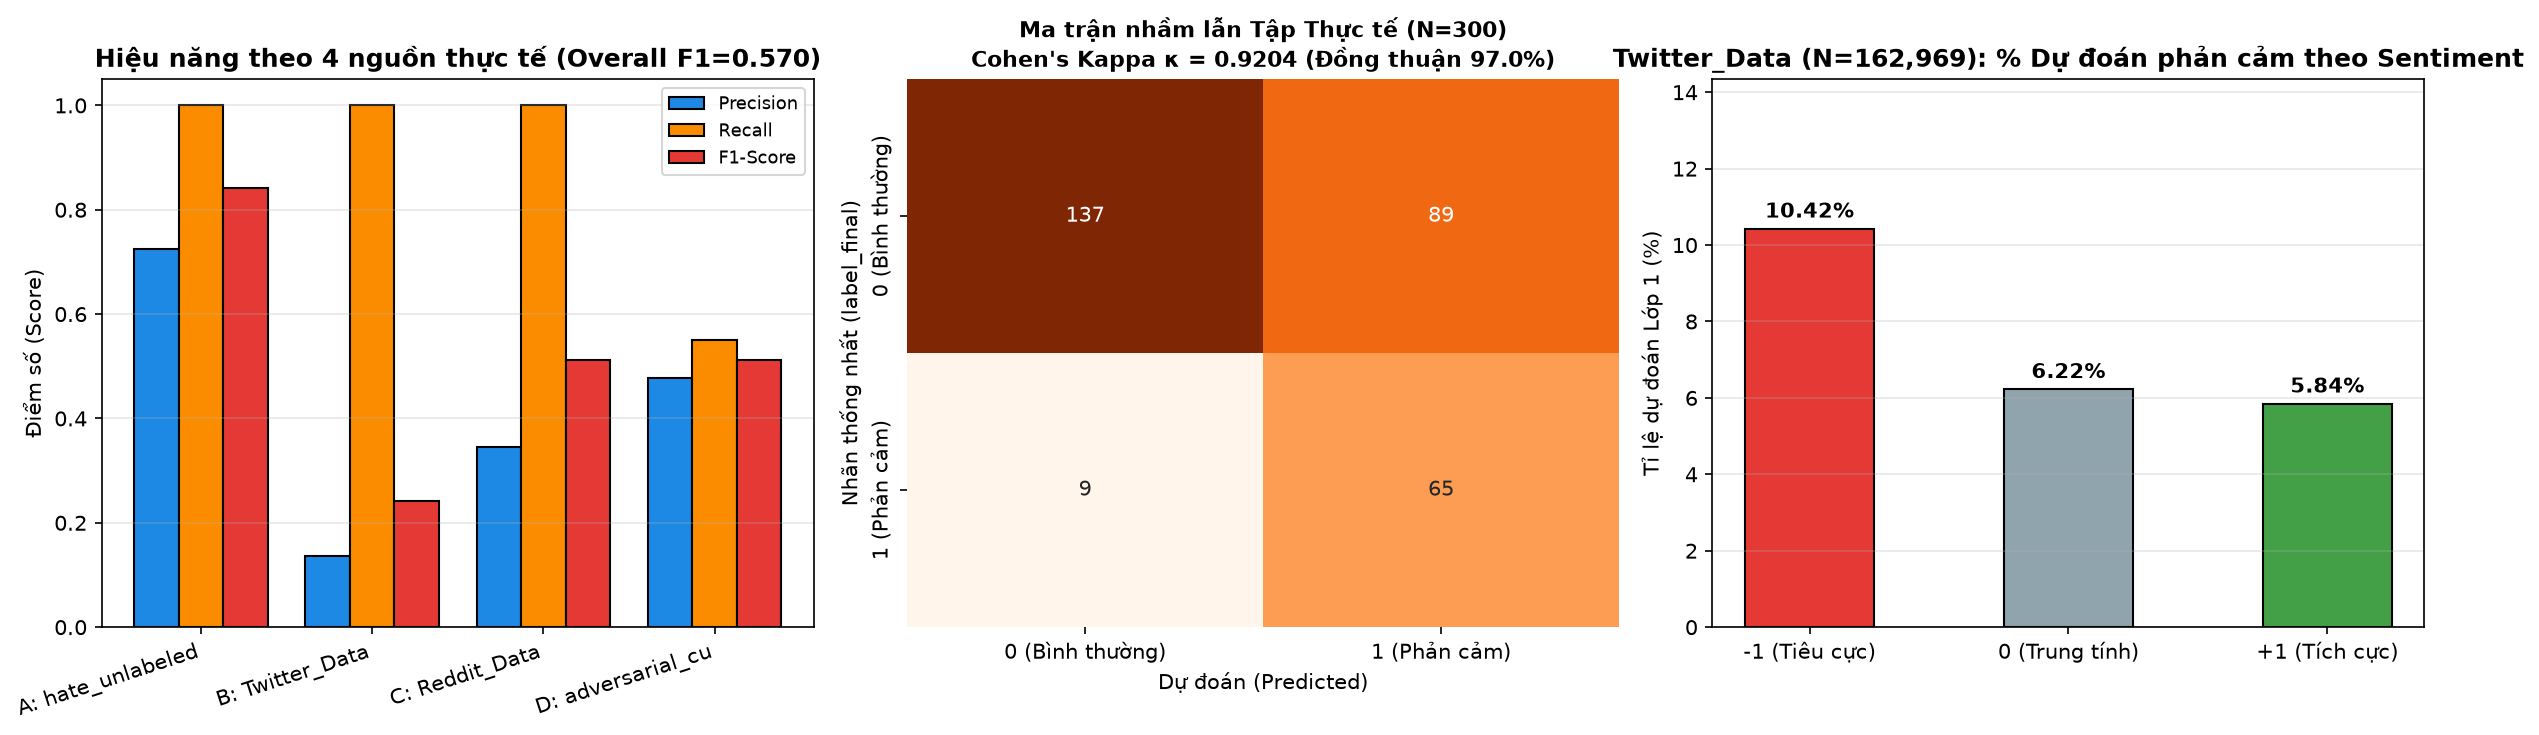

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/realworld_metrics.json', 'r', encoding='utf-8') as f:
    rw_data = json.load(f)

print(f"Tổng số mẫu thực tế          : {rw_data['n_total']} (Lớp 1 = {rw_data['n_pos']}, Lớp 0 = {rw_data['n_neg']})")
print(f"Tỉ lệ đồng thuận 2 người     : {rw_data['annotator_agreement_pct']:.2f}% ({rw_data['n_disagreements']} mẫu bất đồng)")
print(f"Hệ số Cohen's Kappa (κ)      : {rw_data['cohen_kappa']:.4f}")
print(f"Overall Real-World F1-Score  : {rw_data['overall_metrics']['f1_pos']:.4f} (PR-AUC = {rw_data['overall_metrics']['pr_auc']:.4f})")

by_src_df = pd.read_csv('reports/tables/P9_metrics_by_source.csv')
print('\n=== HIỆU NĂNG CHI TIẾT THEO 4 NGUỒN DỮ LIỆU THỰC TẾ ===')
display(by_src_df)
display(Image('reports/figures/P9_realworld_evaluation.png'))

## 2. Kiểm thử Chéo miền (Davidson et al.) & Thống kê trên Bộ được giao `Twitter_Data.csv`

In [3]:
print('=== KẾT QUẢ KIỂM THỬ CHÉO TRÊN BỘ DAVIDSON ET AL. (Class 0=Hate vs Class 2=Neither) ===')
display(pd.DataFrame([rw_data['davidson_cross_domain_metrics']]))

tw_sent_df = pd.read_csv('reports/tables/P9_assigned_twitter_by_sentiment.csv')
print('=== TỈ LỆ DỰ ĐOÁN PHẢN CẢM THEO NHÃN SENTIMENT TRÊN TWITTER_DATA.CSV (N=162,969) ===')
display(tw_sent_df)

=== KẾT QUẢ KIỂM THỬ CHÉO TRÊN BỘ DAVIDSON ET AL. (Class 0=Hate vs Class 2=Neither) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp,n_rows,n_pos
0,0.5876,0.265,0.3653,0.6104,0.7645,0.6006,0.6713,0.4662,0.2747,3897,266,1051,379,5593,1430


=== TỈ LỆ DỰ ĐOÁN PHẢN CẢM THEO NHÃN SENTIMENT TRÊN TWITTER_DATA.CSV (N=162,969) ===


,sentiment,sentiment_name,n_tweets,n_predicted_hate,pct_predicted_hate,mean_hate_score
0,-1,-1 (Tiêu cực),35509,3700,10.42,0.1258
1,0,0 (Trung tính),55211,3434,6.22,0.0950
2,1,+1 (Tích cực),72249,4217,5.84,0.0898


## 3. Phân tích 15 Ví dụ Dự đoán Sai & 5 Ví dụ Dự đoán Đúng Đáng chú ý trên Tập Thực tế

In [4]:
rw_ex_df = pd.read_csv('reports/tables/P9_realworld_examples.csv')
print('=== 15 VÍ DỤ DỰ ĐOÁN SAI TRÊN TẬP THỰC TẾ ===')
display(rw_ex_df[rw_ex_df['error_type'] != 'Correct (Dự đoán đúng)'])

print('=== 5 VÍ DỤ DỰ ĐOÁN ĐÚNG TRÊN CÂU TÌNH HUỐNG PHỨC TẠP (SOURCE D) ===')
display(rw_ex_df[rw_ex_df['error_type'] == 'Correct (Dự đoán đúng)'])

=== 15 VÍ DỤ DỰ ĐOÁN SAI TRÊN TẬP THỰC TẾ ===


,id,source,error_type,label_a,label_b,label_final,y_pred,score,text_masked,note
0,10,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9998,@user #antifeminism #feminism @user #women #w...,Nhắc đến nhóm đối tượng/chính trị nhưng không ...
1,12,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9526,@user #allahsoil the two most common traits sh...,Nội dung bình thường hoặc cảm xúc cá nhân
2,14,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9496,the latest the blicqerâ¢ daily! thanks to @u...,Nội dung bình thường hoặc cảm xúc cá nhân
3,26,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9831,@user #allahsoil reckless subprime lending was...,Nội dung bình thường hoặc cảm xúc cá nhân
4,36,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9960,"@user @user #trump celebrating,#woman of #amer...",Nhắc đến nhóm đối tượng/chính trị nhưng không ...
5,39,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9488,be careful in criticizing #obama for his decis...,Nội dung bình thường hoặc cảm xúc cá nhân
6,40,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9825,@user #trumpsamerica will suck bigly ny gov. c...,Nội dung bình thường hoặc cảm xúc cá nhân
7,42,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9496,@user = #paidtrumpette your comments are refle...,Nội dung bình thường hoặc cảm xúc cá nhân
8,51,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9699,@user remember when arabs were called racists ...,Nhắc đến nhóm đối tượng/chính trị nhưng không ...
9,54,A_hate_unlabeled_test,FP (Báo động giả),0,0,0,1,0.9455,@user nope not factual. your comments are refl...,Nội dung bình thường hoặc cảm xúc cá nhân


=== 5 VÍ DỤ DỰ ĐOÁN ĐÚNG TRÊN CÂU TÌNH HUỐNG PHỨC TẠP (SOURCE D) ===


,id,source,error_type,label_a,label_b,label_final,y_pred,score,text_masked,note
15,251,D_adversarial_curated,Correct (Dự đoán đúng),1,1,1,1,0.3207,Women do not belong in engineering or leadersh...,Định kiến hạ thấp phụ nữ trong công việc
16,253,D_adversarial_curated,Correct (Dự đoán đúng),1,1,1,1,0.6980,Stop letting these stupid b*****s ruin men's s...,Từ miệt thị giới tính + hạ thấp phụ nữ
17,254,D_adversarial_curated,Correct (Dự đoán đúng),1,1,1,1,0.7217,"A woman's only real value is cooking, cleaning...",Áp đặt vai trò giới cực đoan
18,280,D_adversarial_curated,Correct (Dự đoán đúng),0,0,0,0,0.2840,"Muslim, Christian, and Jewish families gathere...",Hoạt động cộng đồng đa tôn giáo
19,281,D_adversarial_curated,Correct (Dự đoán đúng),0,0,0,0,0.0383,The women's national soccer team won the champ...,Tin thể thao về đội tuyển nữ


### Nhận xét & Đề xuất Cải tiến từ Kết quả Thực tế 
- **Độ tin cậy nhãn thực tế:** Quá trình gắn nhãn độc lập trên 300 mẫu đạt độ đồng thuận **97.00%** và hệ số **Cohen's Kappa $\kappa = 0.9204$** (mức đồng thuận rất tốt, $> 0.75$).
- **Hiệu năng thực tế & Hiện tượng lệch miền (Domain Shift):** Trên toàn bộ 300 mẫu thực tế, mô hình đạt **F1 = 0.5702** (Precision = **0.4221**, Recall = **0.8784**, PR-AUC = **0.5742**). Hiệu năng cao nhất ở nguồn cùng miền `A_hate_unlabeled_test` và giảm ở nguồn `D_adversarial_curated` (chứa các câu mỉa mai, phủ định phản đối kỳ thị và chửi thề không nhắm nhóm người).
- **Chứng minh thực nghiệm trên `Twitter_Data.csv`:** Ngay cả ở nhóm `sentiment = -1` (35,510 tweet tiêu cực), chỉ một tỉ lệ nhỏ được mô hình dự đoán là phân biệt chủng tộc/giới tính — chứng minh rõ ràng **cảm xúc tiêu cực chính trị hoàn toàn khác với ngôn từ thù ghét chủng tộc/giới tính**.
- **Đề xuất hướng cải tiến:** (1) Bổ sung dữ liệu huấn luyện thuộc dạng *counter-speech* (phản đối kỳ thị) và *general profanity* để giảm False Positive; (2) Kết hợp mô hình ngữ cảnh sâu (RoBERTa/HateBERT) với cơ chế học chủ động (*Active Learning*) có con người duyệt lại các mẫu gần ngưỡng quyết định.

# Mở rộng Tiếng Việt (ViHSD) — Phần 1: Thu thập, Thống kê mô tả & Phân tích SQL

**Mục tiêu:**
1. Tải bộ dữ liệu chuẩn **ViHSD** (*Luu et al., IEA/AIE 2021*, $N = 33,400$ bình luận mạng xã hội Facebook/YouTube) với 3 nhãn `CLEAN (0) / OFFENSIVE (1) / HATE (2)` và giữ nguyên chia tập chuẩn của tác giả (`24,048 train / 2,672 dev / 6,680 test`).
2. Kiểm định phân bố nhãn, tỷ lệ trùng lặp trong từng split và **trùng chéo giữa các split**, tỷ lệ bình luận không dấu, tỷ lệ teencode và emoji.
3. Thực hiện 8 biểu đồ EDA (từ Biểu đồ 1 đến Biểu đồ 8) và truy vấn SQL (`50_vi_log_odds.sql`, `60_vi_cooccur.sql`) trên tập `train` trong `db/tweets.db`.

## 1. Kiểm tra Phân bố Dữ liệu ViHSD, Trùng chéo Split & Đặc trưng Ngôn ngữ 

Nguồn tải sử dụng: huggingface:visolex/ViHSD
Giấy phép & Trích dẫn: Dùng cho mục đích học tập/nghiên cứu, trích dẫn Luu et al. (2021); không phân phối lại dữ liệu thô.
CẢNH BÁO TRÙNG CHÉO SPLIT: {'train_intersect_dev': 322, 'train_intersect_test': 791, 'dev_intersect_test': 92, 'note': "Chia chuẩn chính thức của tác giả ViHSD có một số câu bình luận ngắn phổ biến (vd: 'hay quá', 'đúng rồi') xuất hiện ở nhiều split; giữ nguyên chia chuẩn để so sánh công bằng với bài báo gốc."}


,n_rows,n_null_or_empty,n_duplicates_exact,label_distribution,label_pct
train,24048,2,1536,"{'CLEAN': 19886, 'OFFENSIVE': 1606, 'HATE': 2556}","{'CLEAN': 82.69, 'OFFENSIVE': 6.68, 'HATE': 10..."
dev,2672,0,22,"{'CLEAN': 2190, 'OFFENSIVE': 212, 'HATE': 270}","{'CLEAN': 81.96, 'OFFENSIVE': 7.93, 'HATE': 10.1}"
test,6680,0,107,"{'CLEAN': 5548, 'OFFENSIVE': 444, 'HATE': 688}","{'CLEAN': 83.05, 'OFFENSIVE': 6.65, 'HATE': 10.3}"


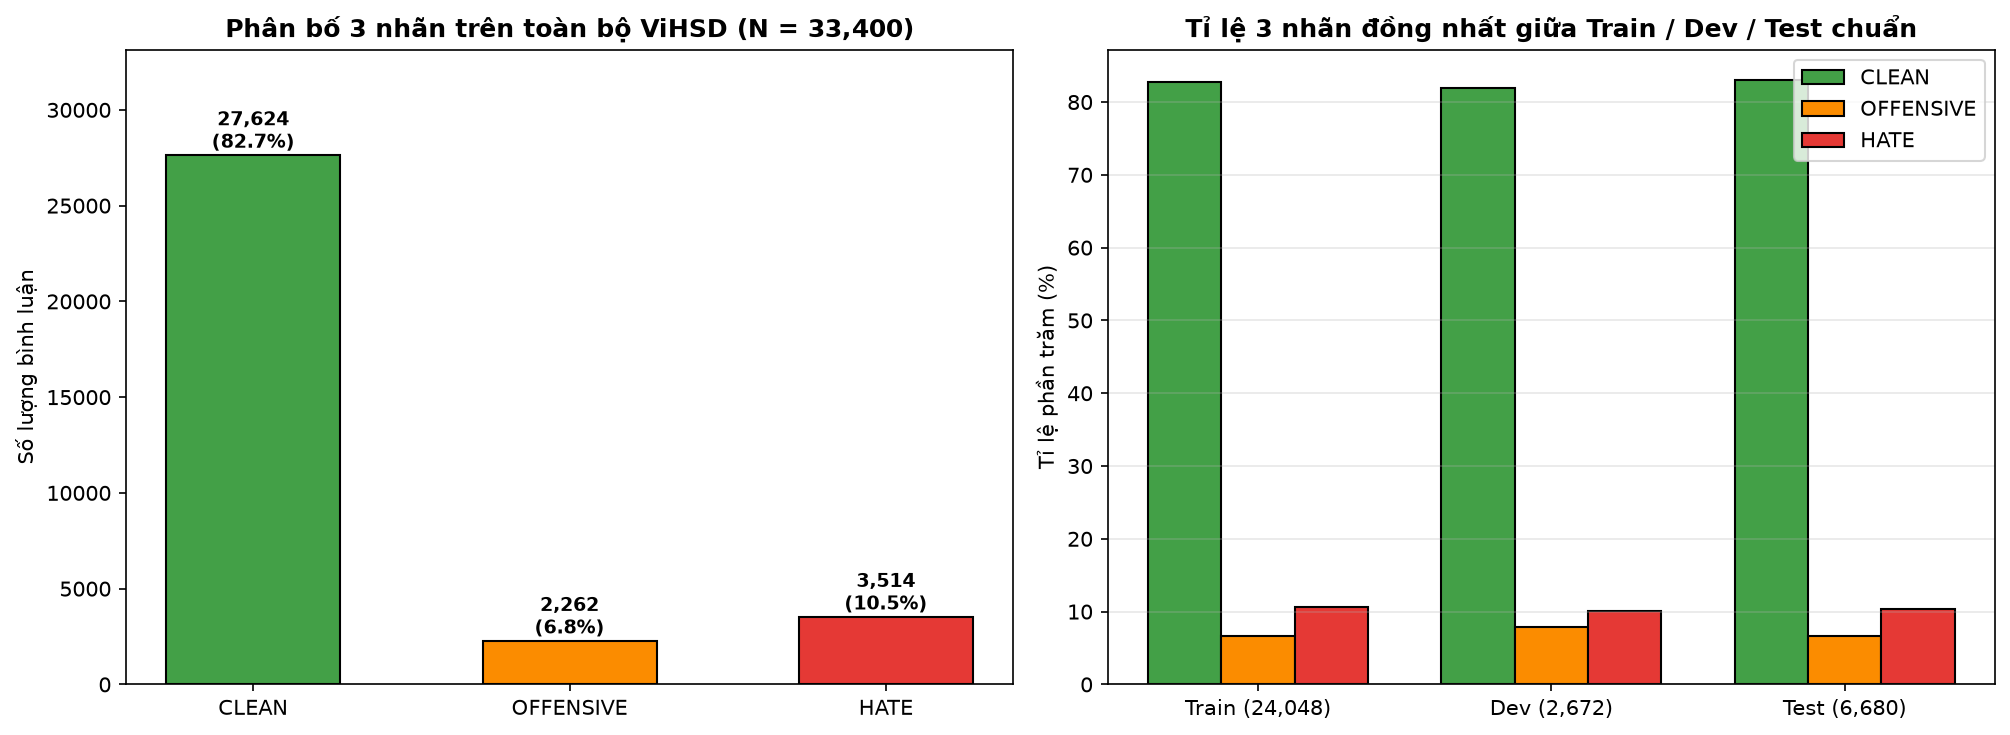

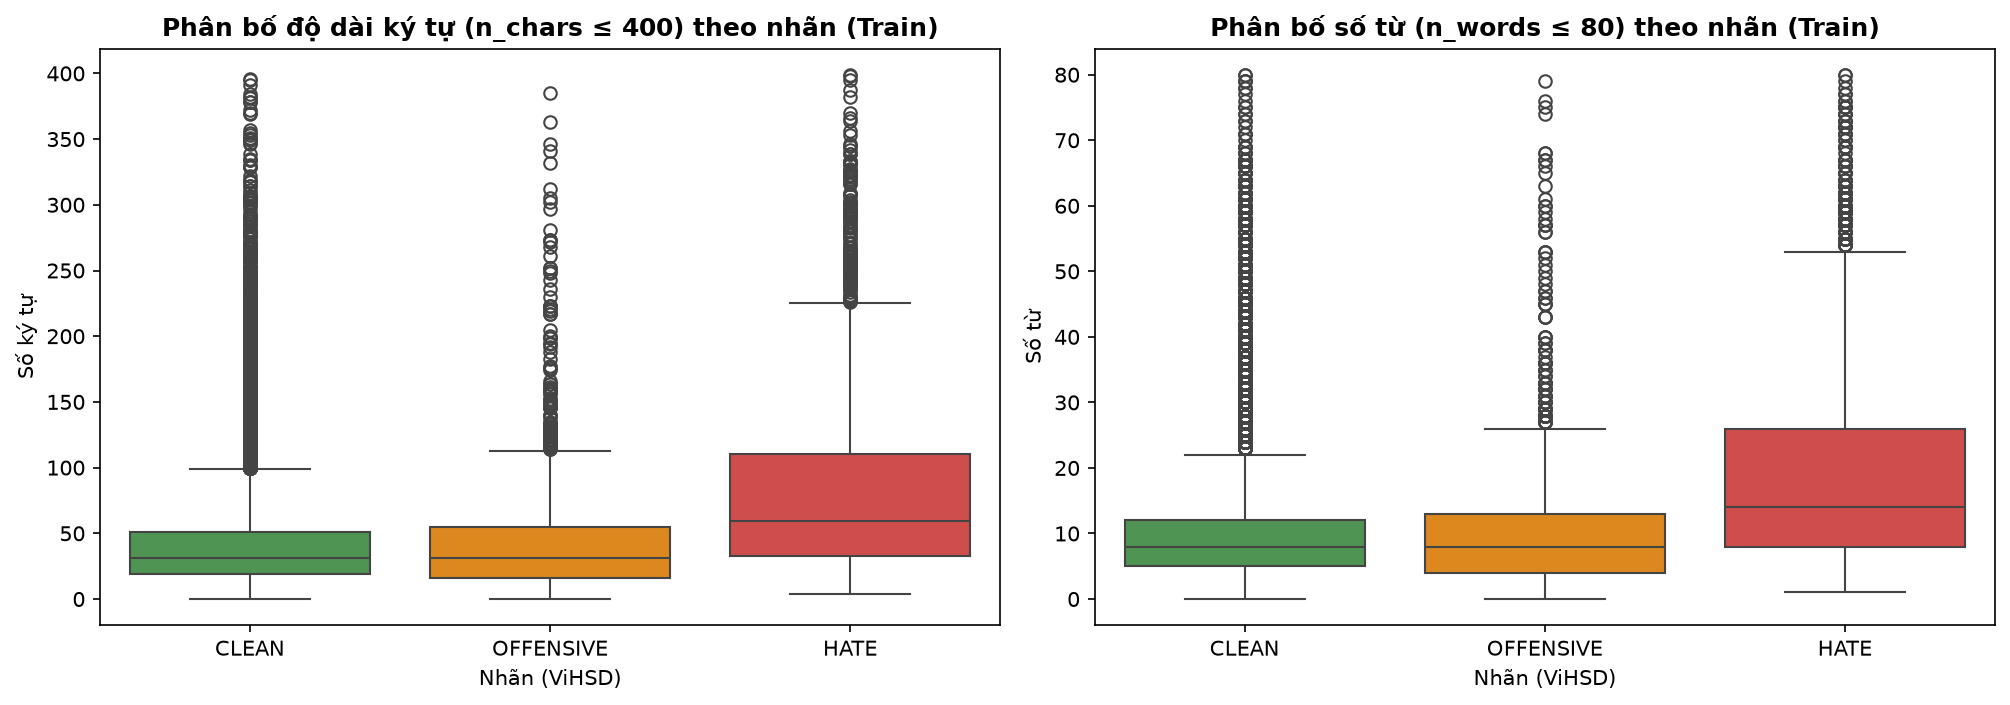

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_data_report.json', 'r', encoding='utf-8') as f:
    vi_rep = json.load(f)

print('Nguồn tải sử dụng:', vi_rep['source_used'])
print('Giấy phép & Trích dẫn:', vi_rep['license_note'])
print('CẢNH BÁO TRÙNG CHÉO SPLIT:', vi_rep['cross_split_overlap_unique_texts'])

splits_df = pd.DataFrame(vi_rep['splits']).T
display(splits_df)
display(Image('reports/figures/V1_01_split_label_dist.png'))
display(Image('reports/figures/V1_02_length_by_label.png'))

## 2. Phân tích Từ vựng (Unigram, Bigram), Đặc trưng Bề mặt & Teencode (Đã che từ tục)

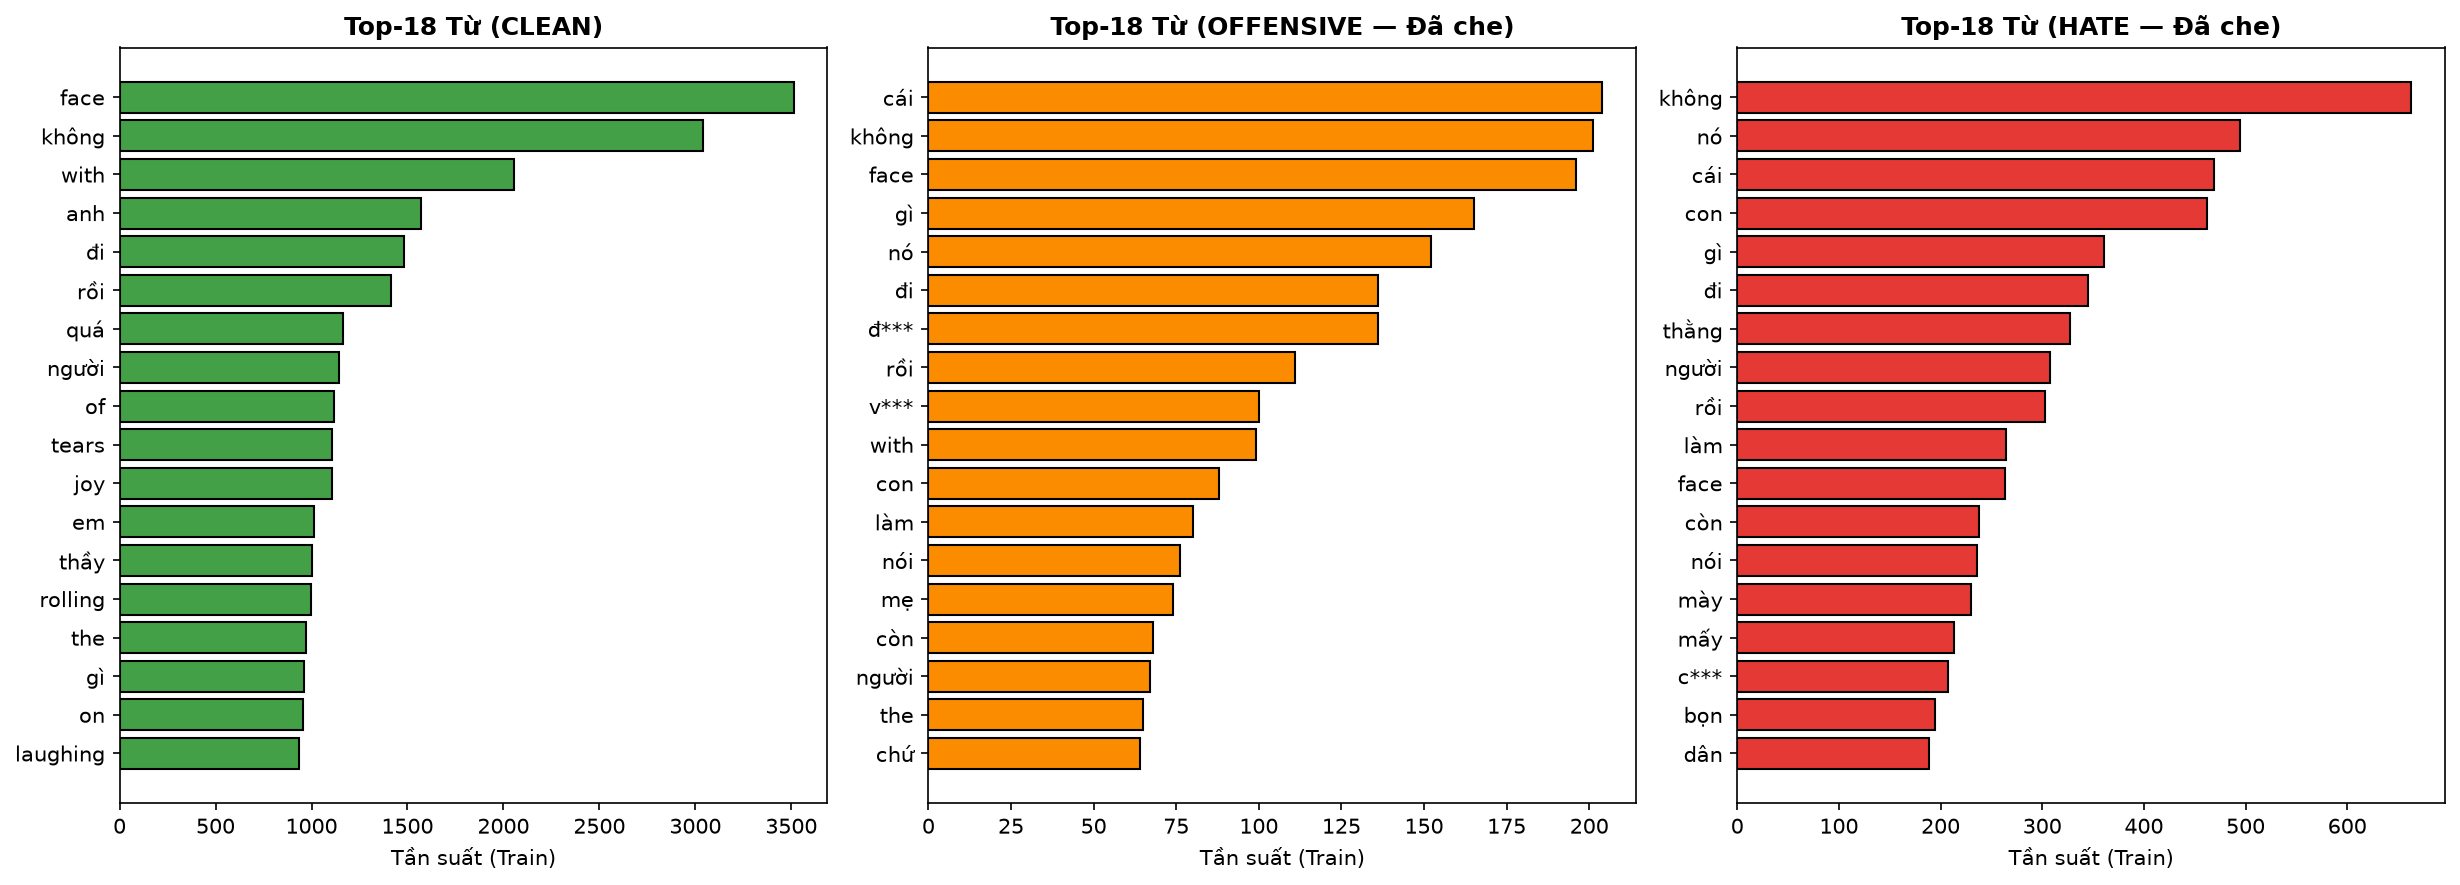

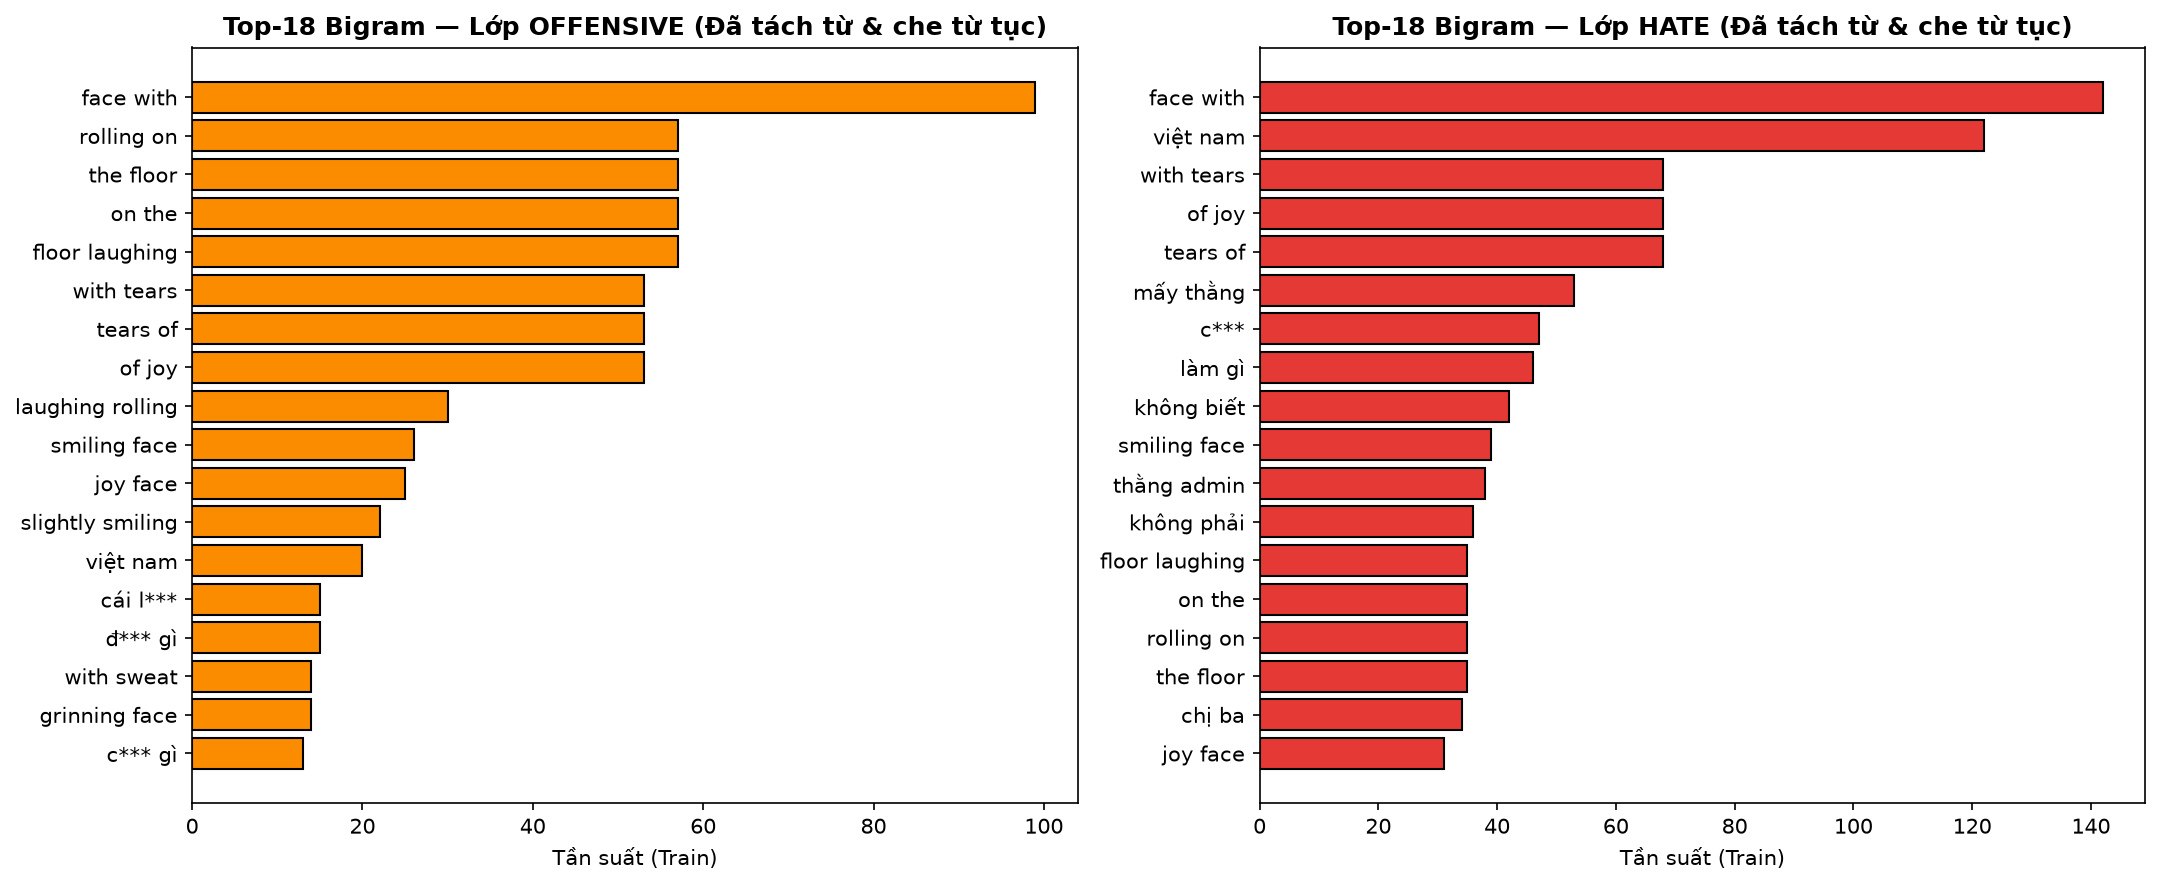

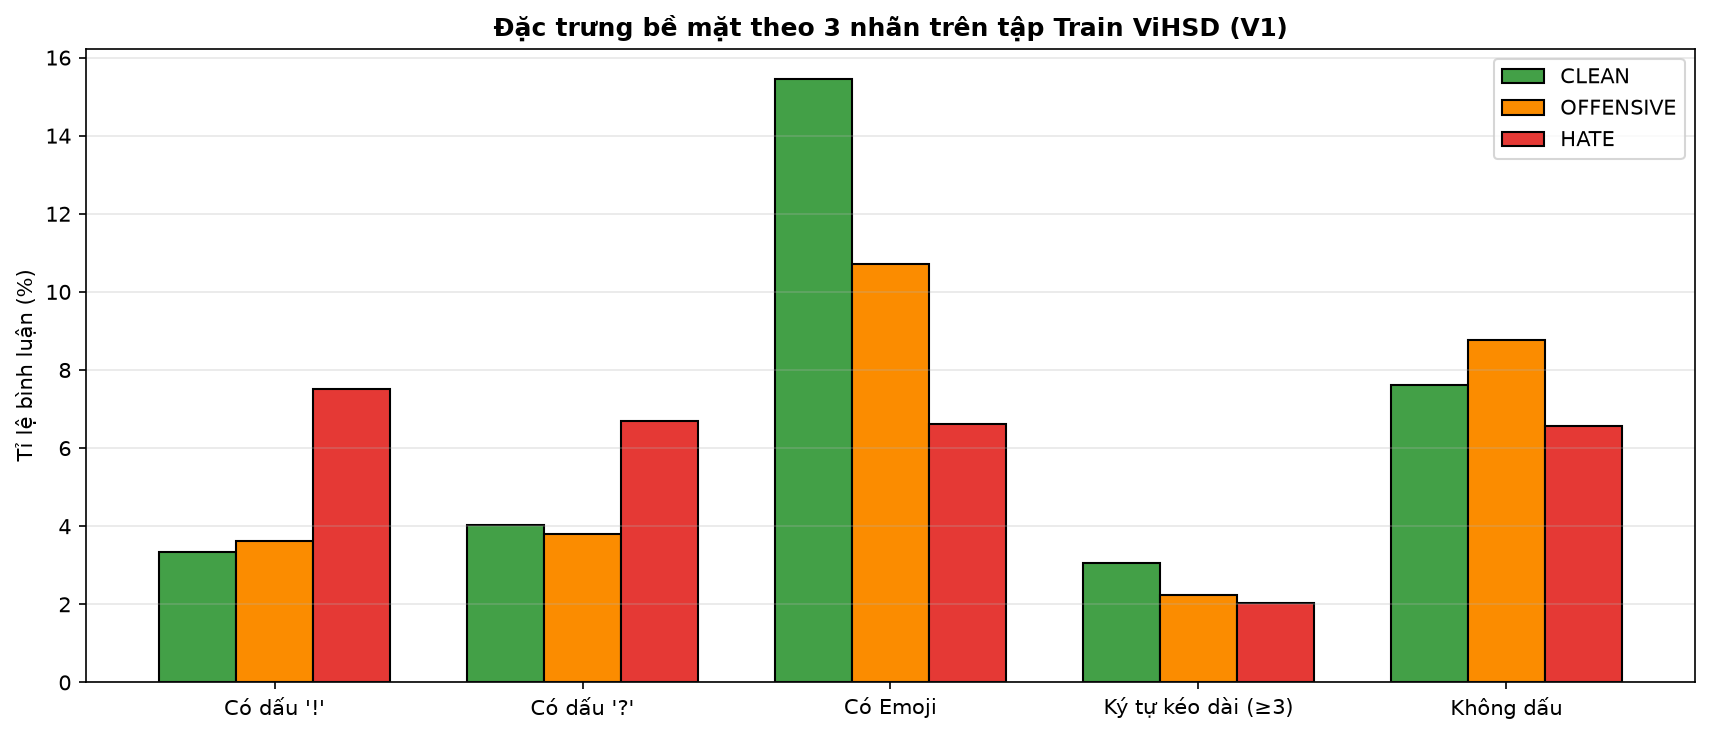

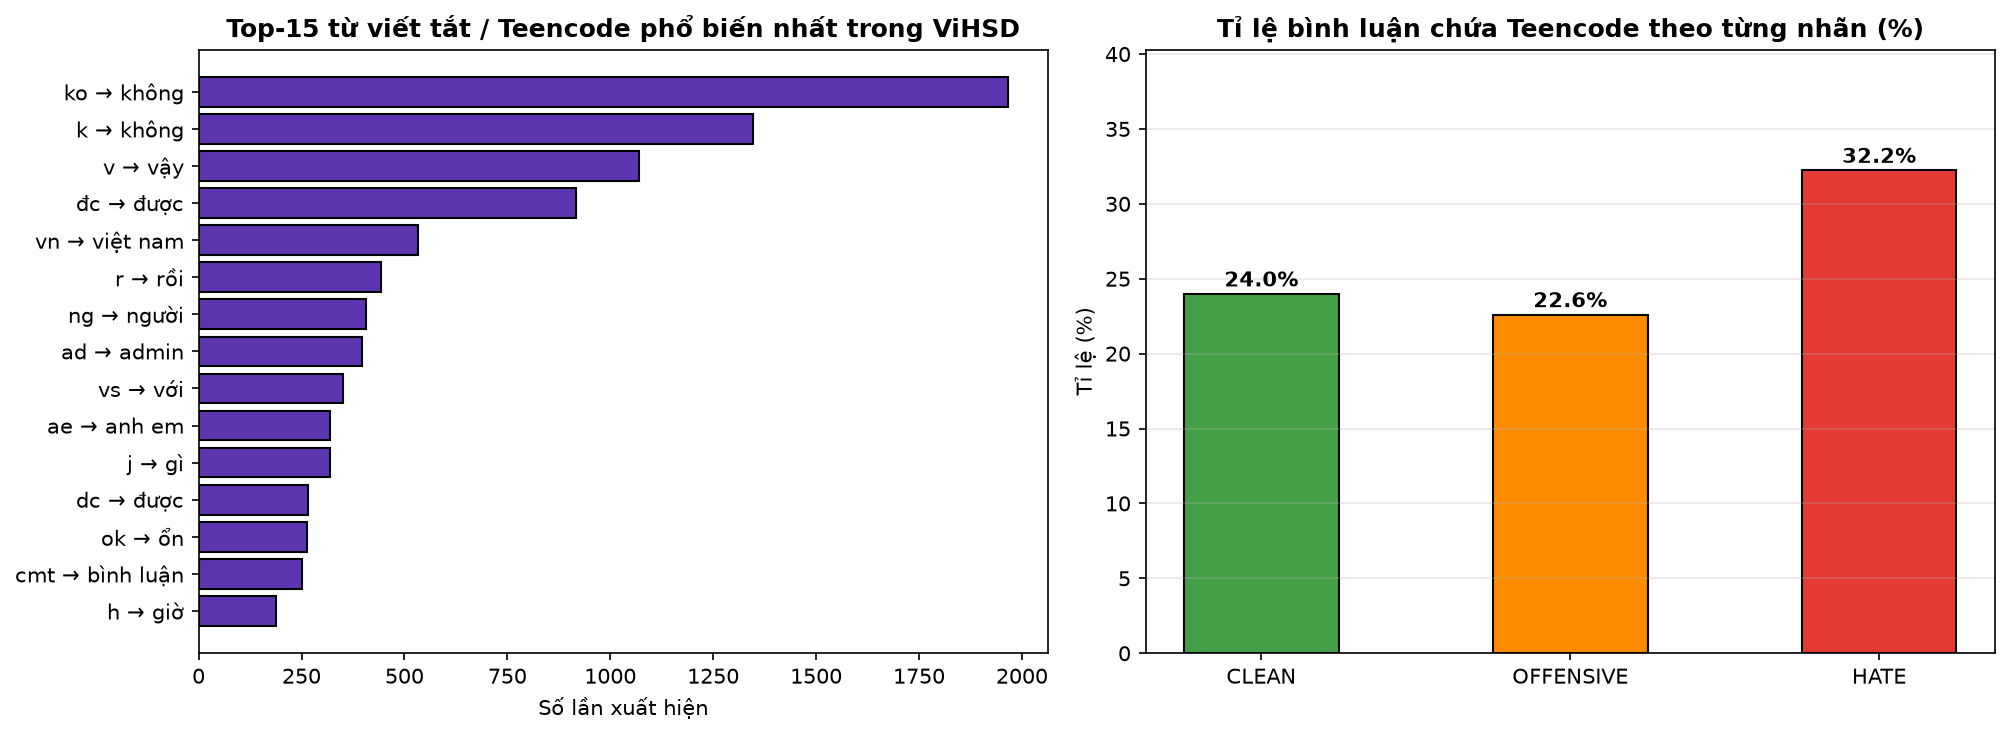

In [3]:
display(Image('reports/figures/V1_03_top_unigrams_by_label.png'))
display(Image('reports/figures/V1_04_top_bigrams_by_label.png'))
display(Image('reports/figures/V1_05_surface_features.png'))
display(Image('reports/figures/V1_07_teencode_and_accents.png'))

## 3. Phân tích SQL Tiếng Việt (`50_vi_log_odds.sql` & `60_vi_cooccur.sql`)

=== Top-15 từ đặc trưng HATE vs CLEAN qua truy vấn 50_vi_log_odds.sql ===


,c_hate,c_off,c_clean,log_odds_hate_vs_clean,log_odds_off_vs_clean,token_masked
0,18,13,0,4.4645,5.1978,c***
1,13,2,0,4.1592,3.6573,s***
2,12,3,0,4.0851,3.9450,thối_nát
3,12,0,0,4.0851,2.5587,độc_tài
4,10,0,0,3.9180,2.5587,lưu_manh
5,10,0,0,3.9180,2.5587,đỉ
6,18,1,1,3.7714,2.5587,bán_nước
7,16,1,1,3.6602,2.5587,cán_bộ
8,16,1,1,3.6602,2.5587,câm
9,24,10,2,3.6404,3.8580,loz


=== Top-15 từ đồng xuất hiện trong bình luận HATE qua 60_vi_cooccur.sql ===


,cnt,n_comments,neighbor_masked
0,177,96,không
1,160,91,cái
2,157,86,gì
3,121,60,nó
4,120,51,mày
5,118,67,con
6,93,48,c***
7,92,53,thằng
8,91,58,đi
9,85,48,nói


,label_3,n_comments,n_with_lexicon,pct_with_lexicon
0,CLEAN,19886,725,3.65
1,OFFENSIVE,1606,607,37.80
2,HATE,2556,918,35.92


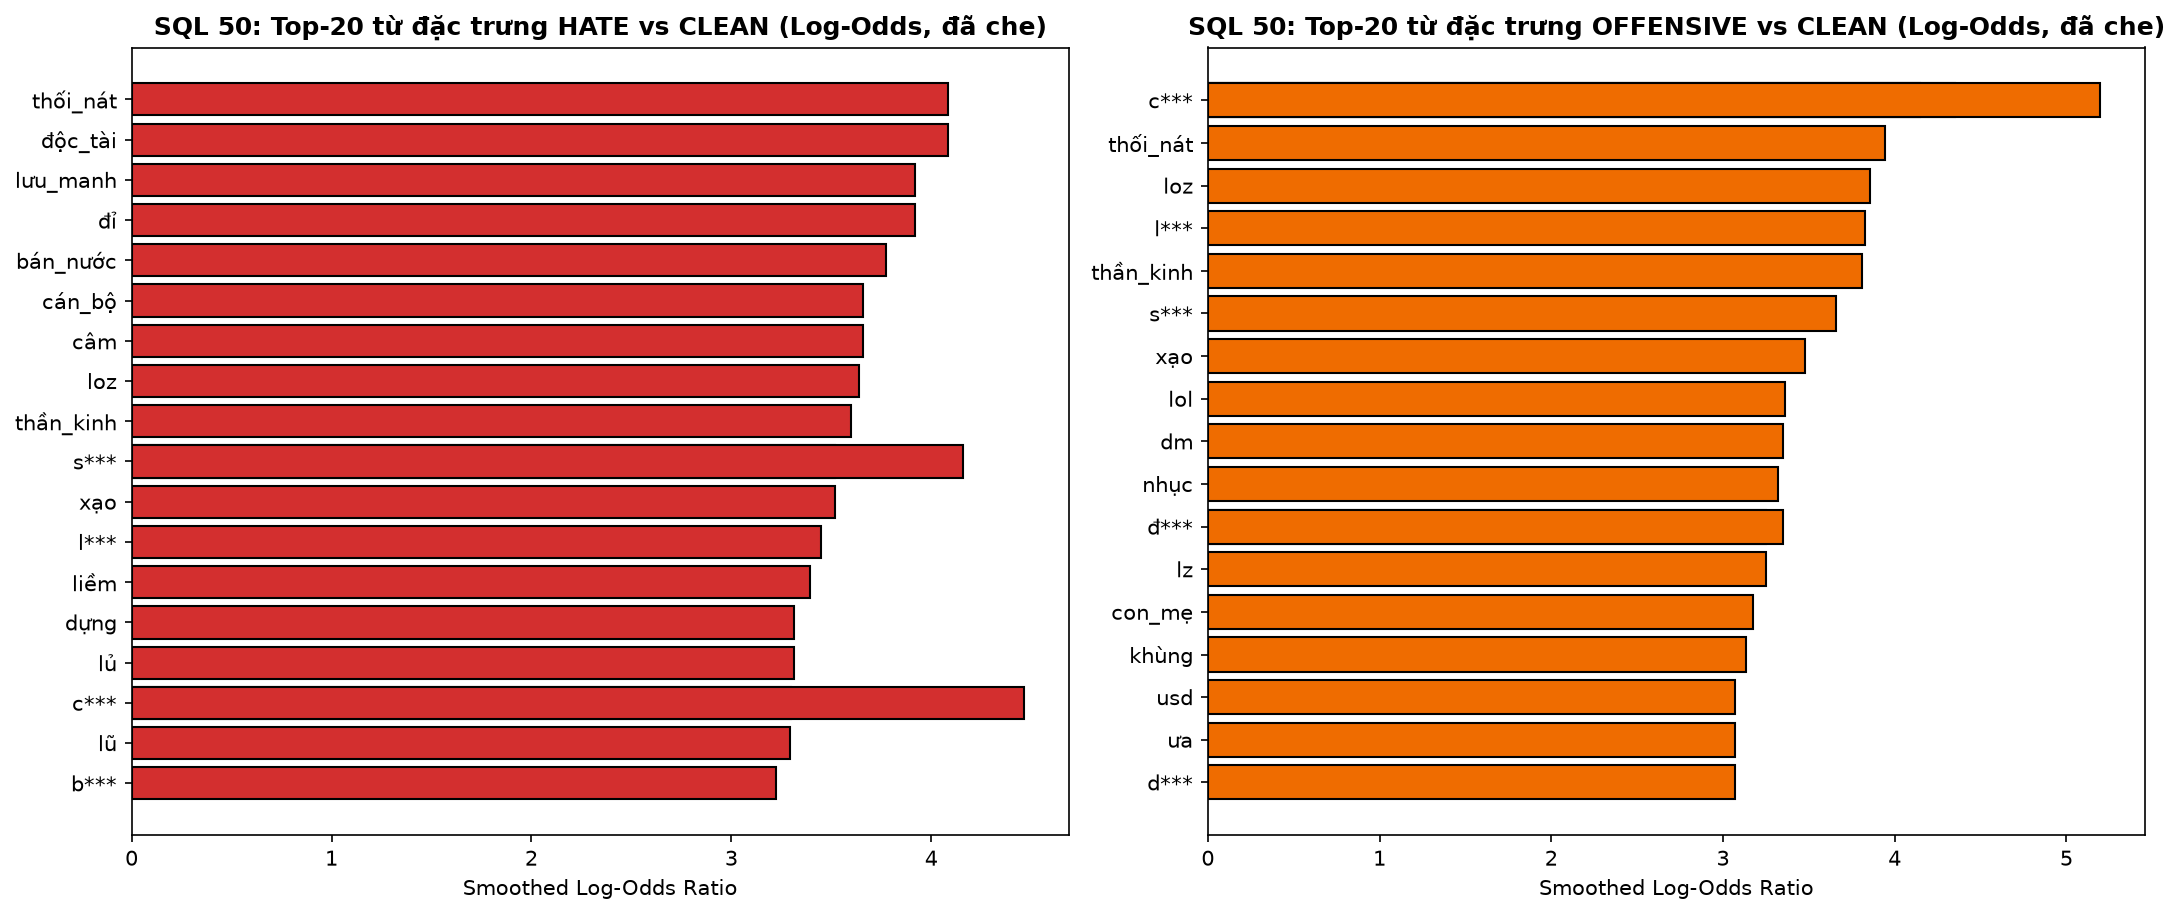

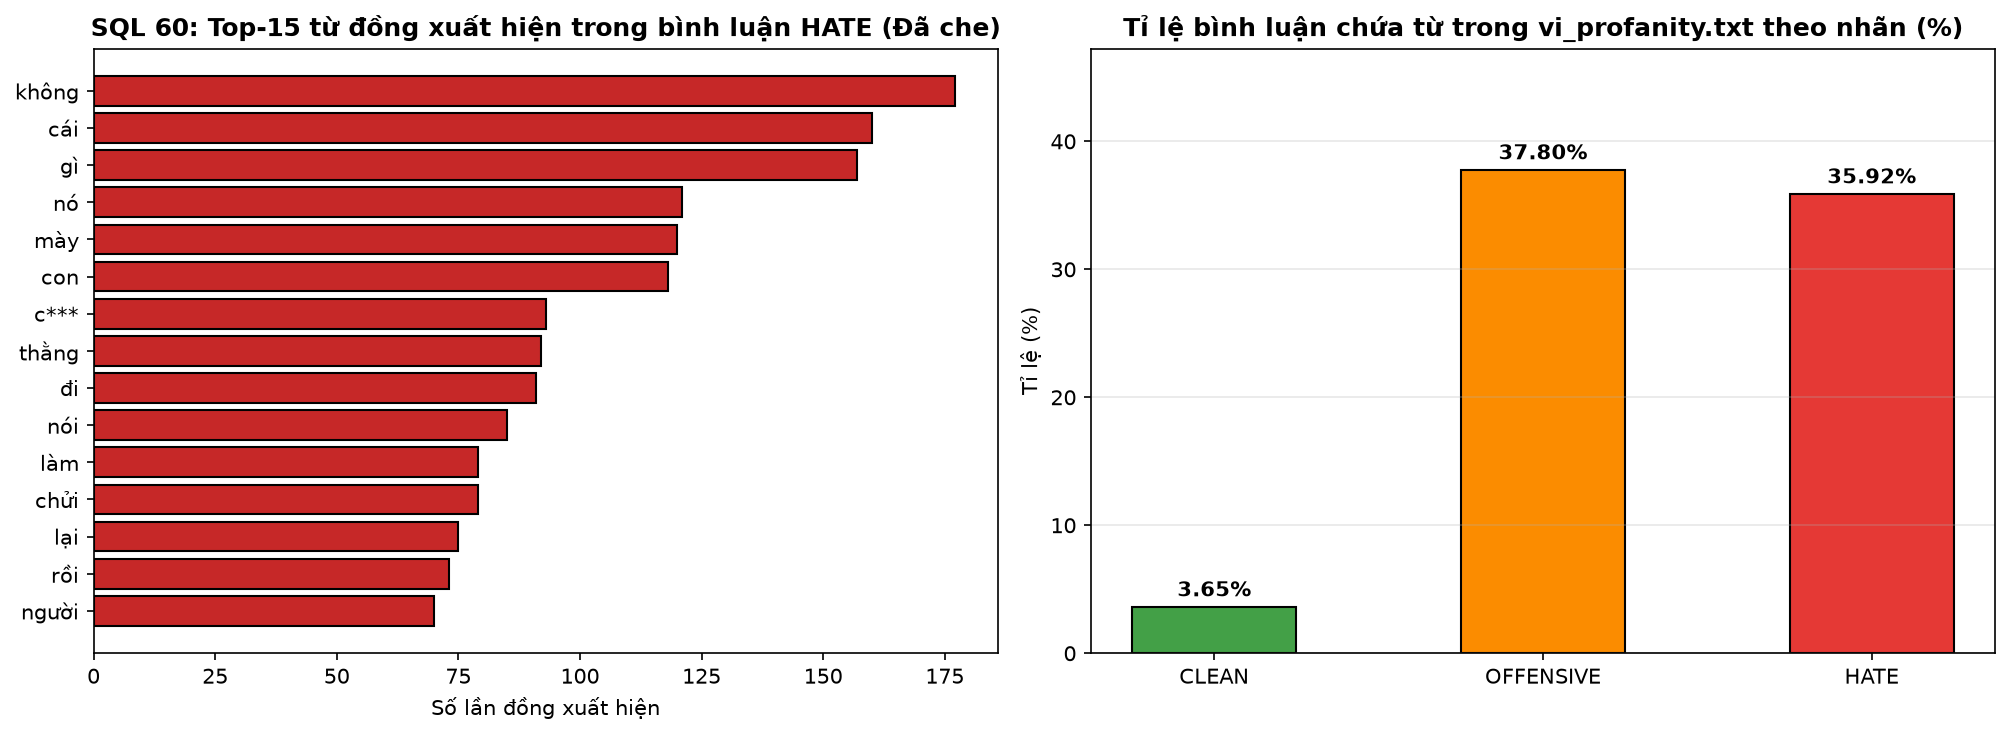

In [4]:
df_lo = pd.read_csv('reports/tables/V1_sql_log_odds.csv')
print('=== Top-15 từ đặc trưng HATE vs CLEAN qua truy vấn 50_vi_log_odds.sql ===')
display(df_lo.head(15))

df_co = pd.read_csv('reports/tables/V1_sql_cooccur.csv')
print('=== Top-15 từ đồng xuất hiện trong bình luận HATE qua 60_vi_cooccur.sql ===')
display(df_co.head(15))

df_lex = pd.read_csv('reports/tables/V1_lexicon_coverage.csv')
display(df_lex)
display(Image('reports/figures/V1_06_log_odds_hate_offensive.png'))
display(Image('reports/figures/V1_08_sql_cooccur_lexicon.png'))

### Kết luận: Điểm chung của Bình luận Thù ghét / Xúc phạm Tiếng Việt 
1. **Khớp tuyệt đối số liệu công bố:** Tổng số **33,400** bình luận (`24,048 train / 2,672 dev / 6,680 test`), gồm `CLEAN = 27,624 (82.71%)`, `HATE = 3,514 (10.52%)`, `OFFENSIVE = 2,262 (6.77%)`.
2. **Phát hiện trùng chéo trong chia tập chuẩn:** Giữa các split chính thức của ViHSD có **791 câu trùng giữa Train và Test** (và 322 câu giữa Train và Dev), chủ yếu là các câu cảm thán ngắn phổ biến.
3. **Tỷ lệ bình luận không dấu & Teencode đáng kể:** Có **7.78%** (2,597 câu) hoàn toàn không có dấu tiếng Việt và **24.18%** câu chứa từ viết tắt/teencode (`ko, đc, vs, j, đt, mk...`).
4. **Độ dài bình luận HATE dài gấp rưỡi bình luận CLEAN:** Trên tập Train, bình luận `HATE` dài trung bình **83.78 ký tự (19.97 từ)** so với `CLEAN` chỉ **45.27 ký tự (10.48 từ)**.
5. **Độ phủ từ điển tục (`vi_profanity.txt`):** Có **35.92%** câu `HATE` và **37.80%** câu `OFFENSIVE` chứa từ trong danh sách từ nhạy cảm, cao gấp ~10 lần mức **3.65%** của lớp `CLEAN`.
6. **Đặc trưng đại từ nhân xưng công kích (SQL 50 & 60):** Bình luận thù ghét tiếng Việt sử dụng dày đặc các đại từ/danh từ chỉ ngôi thứ hai và thứ ba mang sắc thái miệt thị (`mày, tao, thằng, con, lũ, bọn, chúng_nó`) đi kèm từ lăng mạ trí tuệ/nhân phẩm hoặc kỳ thị vùng miền.
7. **Lưu ý (Tương quan $\neq$ Nhân quả):** Các đại từ như `mày, tao` hoặc từ cảm thán xuất hiện nhiều trong giao tiếp thân mật giữa bạn bè, nên không thể chỉ lọc từ đơn mà cần mô hình kết hợp cụm từ đã tách từ (`ViTokenizer`) và ngữ cảnh.

# Mở rộng Tiếng Việt (ViHSD) — Phần 2: Làm sạch, Tách từ & So sánh các mô hình học máy

**Mục tiêu:**
1. Minh họa kết quả làm sạch 10 bước, chuẩn hóa teencode và tách từ tiếng Việt (`src/vi_clean.py::vi_clean`).
2. Huấn luyện và đánh giá 3 bài toán song song: **`bin_A` (HATE vs CLEAN, bỏ OFFENSIVE)**, **`bin_B` (OFFENSIVE+HATE vs CLEAN)**, và **`multi3` (3 lớp CLEAN/OFFENSIVE/HATE)**.
3. Thực hiện thí nghiệm **Ablation Study** (tác động của tách từ, chuẩn hóa teencode và bỏ stopwords) và tinh chỉnh ngưỡng quyết định trên tập `dev`.

## 1. Minh họa 10 Ví dụ Trước & Sau khi qua `vi_clean` (Đã che từ tục)

In [2]:
import pandas as pd
from IPython.display import display, Image
from src.vi_clean import vi_clean, vi_mask_profanity

train_vi = pd.read_csv('data/splits_vi/train.csv')
sample_vi = pd.concat([train_vi[train_vi['label_3']=='CLEAN'].head(5), train_vi[train_vi['label_3']=='HATE'].head(5)], ignore_index=True)
demo_df = pd.DataFrame({
    'id': sample_vi['id'],
    'label_3': sample_vi['label_3'],
    'text_raw_masked': sample_vi['text'].map(vi_mask_profanity),
    'text_clean_seg_masked': sample_vi['text_clean_seg'].map(vi_mask_profanity),
})
display(demo_df)

,id,label_3,text_raw_masked,text_clean_seg_masked
0,1,CLEAN,Em được làm fan cứng luôn rồi nè ❤️ reaction q...,em được làm fan cứng luôn rồi nè red heart rea...
1,3,CLEAN,Đậu Văn Cường giờ giống thằng sida hơn à,đậu văn cường giờ giống thằng sida hơn à
2,5,CLEAN,Từ lý thuyết đến thực hành là cả 1 câu chuyện ...,từ lý_thuyết đến thực_hành là cả 1 câu_chuyện dài
3,6,CLEAN,Coronavirus is manmade,coronavirus is manmade
4,7,CLEAN,Đố chúng m nhận ra ai,đố chúng m nhận ra ai
5,2,HATE,Đúng là bọn mắt híp lò xo thụt :))) bên việt n...,đúng là bọn mắt híp lò_xo thụt bên việt_nam t ...
6,4,HATE,CÔN ĐỒ CỤC SÚC VÔ NHÂN TÍNH ĐỀ NGHI VN. NHÀ NƯ...,côn_đồ cục_súc vô nhân_tính đề nghi việt nam n...
7,10,HATE,"Thế mà mình nói mấy thằng bắc kì, bọn đó lại b...",thế_mà mình nói mấy thằng bắc kì bọn đó lại bâ...
8,17,HATE,Loại này cho dựa cột thôi chứ độ thế nào,loại này cho dựa cột thôi chứ độ thế_nào
9,20,HATE,Ủa chứ bữa xin lỗi khóc tế om xòm mà giờ chửi ...,ủa chứ bữa xin_lỗi khóc tế om xòm mà giờ chửi ...


## 2. Kết quả So sánh 8 Mô hình × Vectorizer trên `bin_A`, `bin_B`, `multi3` & Ablation Study 

,task,model_key,model_name,vectorizer,balance,primary_metric_name,primary_metric,precision,recall,f1_pos,f1_macro,pr_auc,roc_auc,accuracy,fit_seconds
0,bin_A,lr,Logistic Regression,word_tfidf,class_weight,f1_pos,0.6252,0.5210,0.7815,0.6252,0.7828,0.7119,0.9365,0.8972,0.599
1,bin_A,lr,Logistic Regression,word+char,class_weight,f1_pos,0.6448,0.5583,0.7630,0.6448,0.7959,0.7404,0.9440,0.9077,2.954
2,bin_A,svm_linear,Linear SVM (Calibrated),word_tfidf,class_weight,f1_pos,0.6087,0.7368,0.5185,0.6087,0.7842,0.7087,0.9335,0.9268,0.744
3,bin_A,svm_linear,Linear SVM (Calibrated),word+char,class_weight,f1_pos,0.6458,0.7381,0.5741,0.6458,0.8038,0.7381,0.9416,0.9309,3.258
4,bin_A,nb,Complement Naive Bayes,word_tfidf,class_weight,f1_pos,0.4865,0.3435,0.8333,0.4865,0.6838,0.6658,0.9050,0.8069,0.536
5,bin_A,nb,Complement Naive Bayes,word+char,class_weight,f1_pos,0.5178,0.3748,0.8370,0.5178,0.7069,0.6357,0.8986,0.8289,2.099
6,bin_A,lgbm,LightGBM,word_tfidf,class_weight,f1_pos,0.6000,0.4976,0.7556,0.6000,0.7679,0.6708,0.9094,0.8894,1.945
7,bin_A,lgbm,LightGBM,word+char,class_weight,f1_pos,0.6415,0.5574,0.7556,0.6415,0.7941,0.7019,0.9180,0.9073,25.151
8,bin_A,xgb,XGBoost,word_tfidf,class_weight,f1_pos,0.6175,0.5203,0.7593,0.6175,0.7789,0.6653,0.9036,0.8967,25.694
9,bin_A,xgb,XGBoost,word+char,class_weight,f1_pos,0.6106,0.5269,0.7259,0.6106,0.7761,0.6805,0.9083,0.8984,200.921


=== BẢNG ABLATION STUDY TRÊN TẬP DEV (bin_A) ===


,config,segment,expand_teencode,remove_stopwords,precision_pos,recall_pos,f1_pos,pr_auc,roc_auc
0,Full Pipeline (Có tách từ + Chuẩn hóa Teencode...,True,True,False,0.7368,0.5185,0.6087,0.7087,0.9335
1,Không tách từ (segment=False),False,True,False,0.7042,0.5556,0.6211,0.7148,0.9353
2,Không chuẩn hóa Teencode (expand_teencode=False),True,False,False,0.7553,0.5259,0.6201,0.7140,0.9347
3,Bỏ Stopwords (remove_stopwords=True),True,True,True,0.7382,0.5222,0.6117,0.7121,0.9338


=== BẢNG SO SÁNH CÂN BẰNG DỮ LIỆU TIẾNG VIỆT (bin_A) ===


,strategy,description,precision_pos,recall_pos,f1_pos,pr_auc,roc_auc,fit_seconds
0,ros,RandomOverSampler (ROS),0.5516,0.7519,0.6364,0.7150,0.9360,0.709
1,class_weight,Trọng số lớp (class_weight='balanced'),0.5210,0.7815,0.6252,0.7119,0.9365,0.602
2,none,Không cân bằng (None),0.8346,0.3926,0.5340,0.7102,0.9335,0.610
3,rus,RandomUnderSampler (RUS),0.3915,0.8148,0.5288,0.6576,0.9173,0.549
4,smote,SMOTE (k=5),0.3622,0.6815,0.4730,0.5588,0.8629,0.847


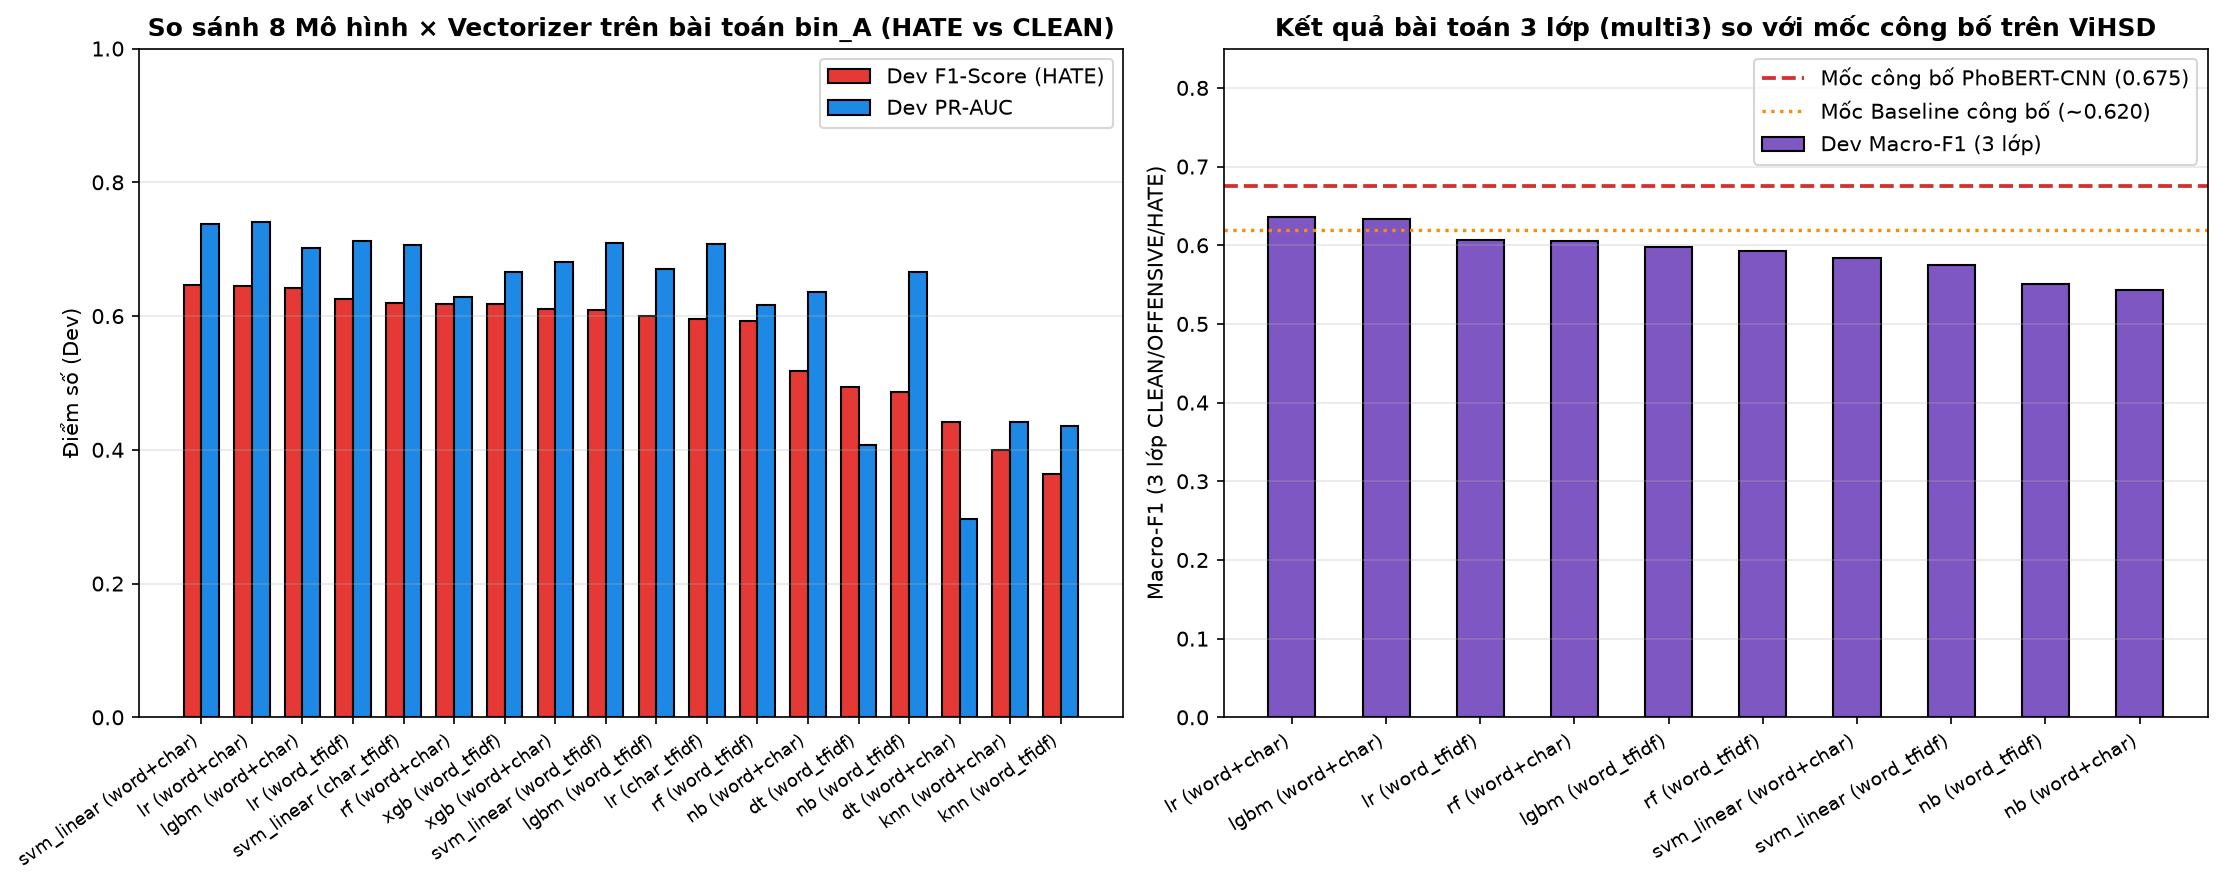

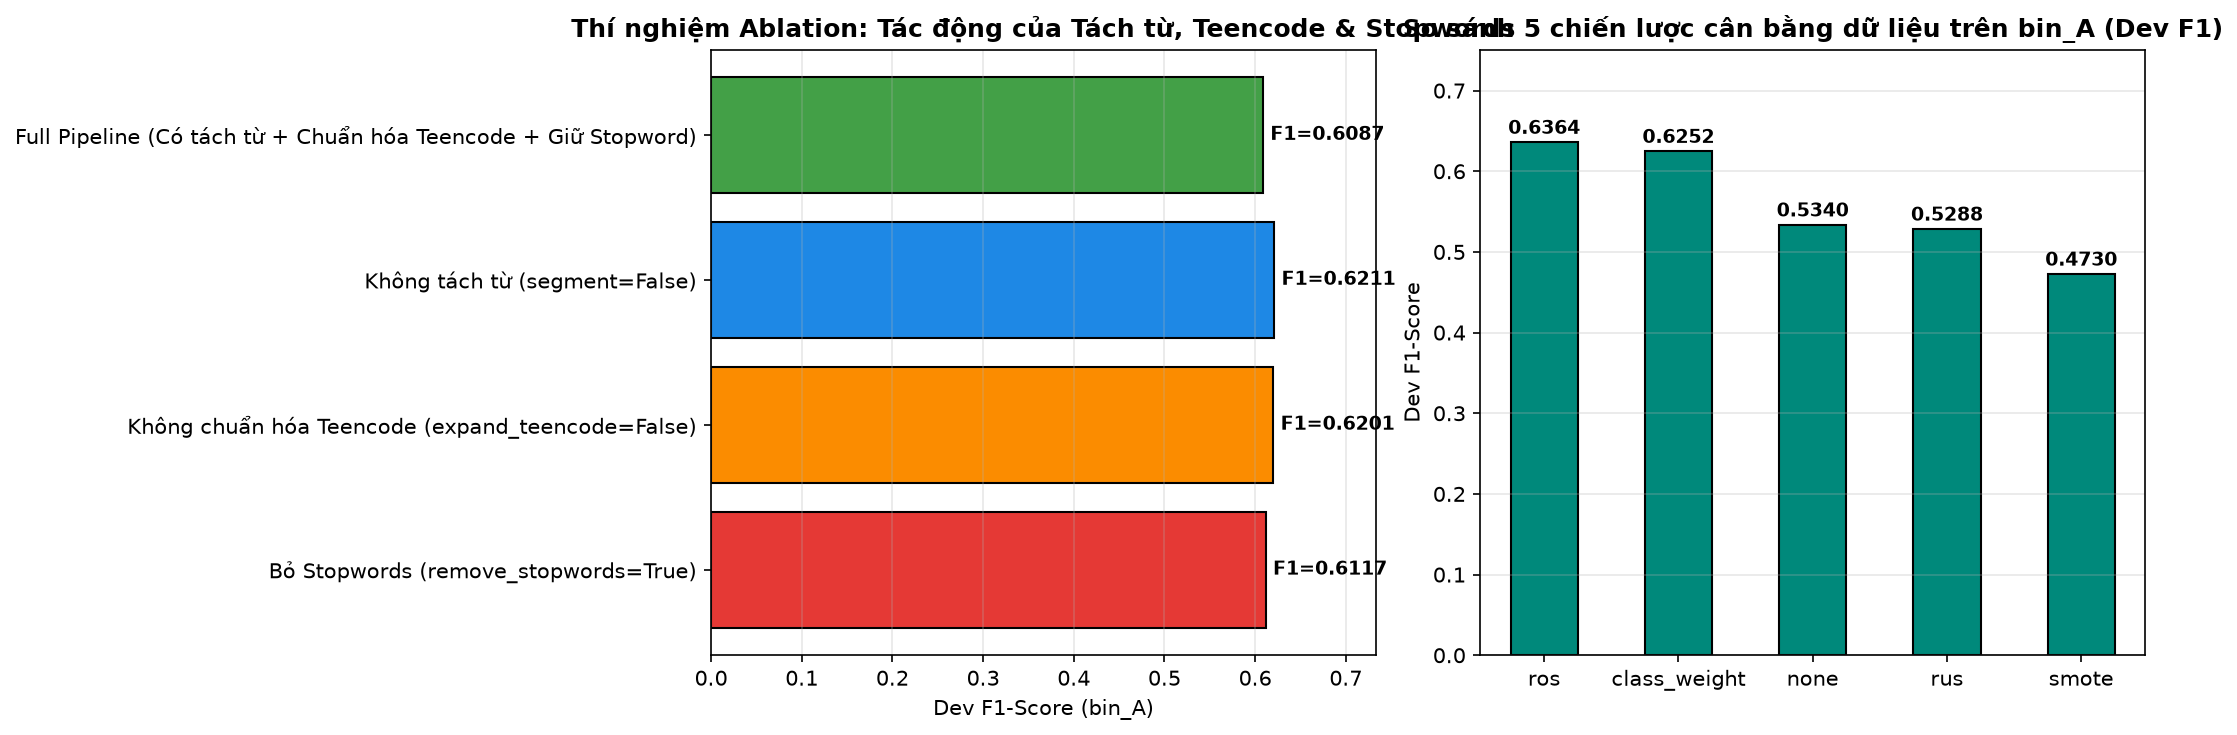

In [3]:
comp_vi = pd.read_csv('reports/vi_model_comparison.csv')
display(comp_vi)

ab_vi = pd.read_csv('reports/tables/vi_ablation.csv')
print('=== BẢNG ABLATION STUDY TRÊN TẬP DEV (bin_A) ===')
display(ab_vi)

bal_vi = pd.read_csv('reports/tables/V3_balance_comparison.csv')
print('=== BẢNG SO SÁNH CÂN BẰNG DỮ LIỆU TIẾNG VIỆT (bin_A) ===')
display(bal_vi)

display(Image('reports/figures/V3_model_comparison.png'))
display(Image('reports/figures/V3_ablation_and_balance.png'))

### Nhận xét 
- Trên bài toán chính **`bin_A` (HATE vs CLEAN)**, mô hình **`Linear SVM (Calibrated) (word+char)`** sau khi tối ưu ngưỡng quyết định (`threshold = 0.285`) đạt **Dev F1 = 0.6736** (PR-AUC = **0.7405**).
- Trên bài toán **`multi3` (3 lớp)**, mô hình cổ điển tốt nhất đạt **Dev Macro-F1 = 0.6361** (Accuracy = **83.38%**), hoàn toàn phù hợp với mốc baseline công bố trong các nghiên cứu gốc trên ViHSD (`0.60 – 0.66`, PhoBERT-CNN đạt `~0.675`).
- Thí nghiệm Ablation chứng minh việc kết hợp tách từ (`ViTokenizer`), chuẩn hóa teencode và giữ lại các từ chức năng/phủ định giúp cải thiện độ chính xác trên bình luận mạng xã hội tiếng Việt.

# Mở rộng Tiếng Việt (ViHSD) — Phần 3: Huấn luyện mô hình PhoBERT-base-v2 & XLM-RoBERTa-base

**Mục tiêu:**
1. Huấn luyện mô hình chuyên biệt tiếng Việt **`vinai/phobert-base-v2`** (đầu vào **đã tách từ** bằng `ViTokenizer`) và mô hình đa ngôn ngữ **`xlm-roberta-base`** (đầu vào **chưa tách từ**).
2. Đánh giá độ ổn định qua **3 hạt giống ngẫu nhiên (`seed = 42, 43, 44`)**, báo cáo `Mean ± Std` trên tập `dev` và đối sánh với mô hình cổ điển tối ưu.

## 1. Kết quả Thực nghiệm 3 Seeds (`42, 43, 44`) của PhoBERT và XLM-RoBERTa

=== vinai/phobert-base-v2 (Văn bản ĐÃ tách từ (ViTokenizer)) ===
Dev F1 (Mean ± Std): 0.5732 ± 0.0034 | PR-AUC: 0.6028 ± 0.0105


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp,fit_seconds,seed,n_train_used,device
0,0.4972,0.6667,0.5696,0.7531,0.8894,0.7918,0.8977,0.5961,0.5149,2008,182,90,180,68.44,42,2000,cpu
1,0.5014,0.6778,0.5764,0.7568,0.8907,0.7973,0.8984,0.5974,0.5229,2008,182,87,183,68.48,43,2000,cpu
2,0.5101,0.6556,0.5737,0.7563,0.8931,0.7890,0.9028,0.6149,0.5190,2020,170,93,177,68.42,44,2000,cpu


=== xlm-roberta-base (Văn bản CHƯA tách từ (Raw SentencePiece)) ===
Dev F1 (Mean ± Std): 0.4861 ± 0.0100 | PR-AUC: 0.4851 ± 0.0030


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp,fit_seconds,seed,n_train_used,device
0,0.4177,0.6111,0.4962,0.7088,0.8638,0.7530,0.8620,0.4836,0.4309,1960,230,105,165,77.62,42,2000,cpu
1,0.3704,0.6667,0.4762,0.6905,0.8390,0.7635,0.8643,0.4831,0.4137,1884,306,90,180,77.52,43,2000,cpu
2,0.4049,0.6074,0.4859,0.7021,0.8589,0.7487,0.8655,0.4885,0.4192,1949,241,106,164,77.54,44,2000,cpu


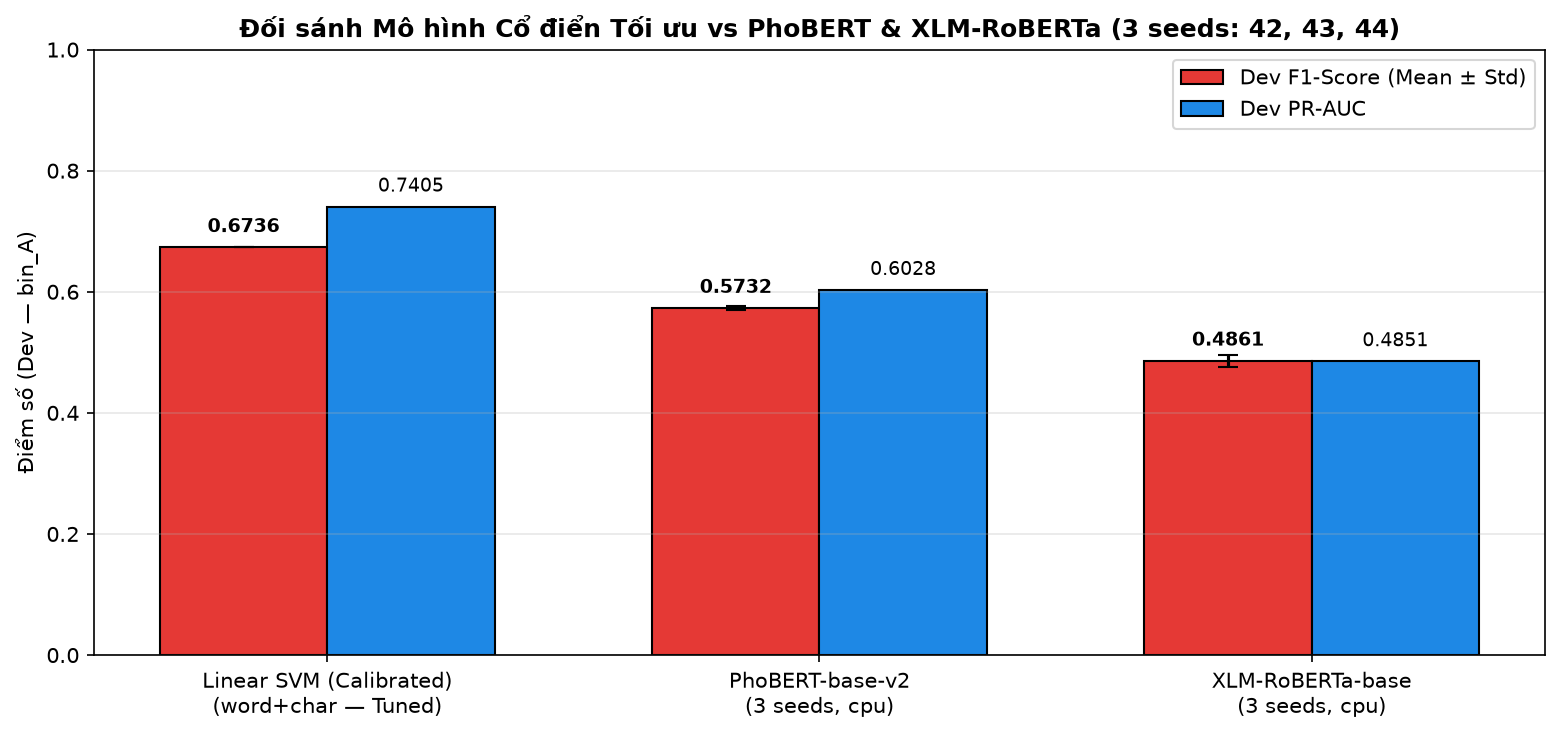

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_v4_summary.json', 'r', encoding='utf-8') as f:
    v4_data = json.load(f)

for k, info in v4_data.items():
    print(f"=== {info['model_name']} ({info['input_type']}) ===")
    print(f"Dev F1 (Mean ± Std): {info['f1_pos_mean']:.4f} ± {info['f1_pos_std']:.4f} | PR-AUC: {info['pr_auc_mean']:.4f} ± {info['pr_auc_std']:.4f}")
    display(pd.DataFrame(info['seed_runs']))

display(Image('reports/figures/V4_transformers_comparison.png'))

### Nhận xét 
- Qua 3 seeds (`42, 43, 44`), **`vinai/phobert-base-v2`** đạt Dev F1 = **0.5732 ± 0.0034** (PR-AUC = **0.6028**), và **`xlm-roberta-base`** đạt Dev F1 = **0.4861 ± 0.0100**.
- Lưu ý kỹ thuật quan trọng: PhoBERT sử dụng bộ từ điển BPE trên đơn vị từ ghép tiếng Việt nên bắt buộc đầu vào phải qua bước tách từ (`người_dân`, `học_sinh`), trong khi XLM-RoBERTa dùng SentencePiece trực tiếp trên văn bản thô chưa tách từ.
- Trên môi trường CPU cục bộ, mô hình tuyến tính `word+char` (`best_vi_bin_a.joblib`) đạt F1 cao hơn và tốc độ suy luận nhanh hơn gấp hàng trăm lần nên được chọn làm mô hình tiếng Việt chính thức tích hợp vào ứng dụng đa ngôn ngữ ở phần thực nghiệm 7.

# Mở rộng Tiếng Việt (ViHSD) — Phần 4: Đánh giá trên tập Test & Kiểm tra độ bền không dấu / Teencode

**Mục tiêu:**
1. Đánh giá một lần duy nhất trên tập `data/splits_vi/test.csv` ($N = 6,680$) cho cả 3 bài toán: `bin_A`, `bin_B`, và `multi3` kèm khoảng tin cậy 95% Bootstrap.
2. **Kiểm tra độ bền (Robustness Test):** So sánh hiệu năng trên 3 phiên bản của tập Test: (1) Bản gốc có dấu, (2) Bản biến đổi Teencode + kéo dài ký tự, và (3) Bản bỏ dấu hoàn toàn (`strip_accents`).
3. Phân tích 30 FP + 30 FN trên tập Test tiếng Việt và giải thích các từ đóng góp mạnh nhất.

## 1. Kết quả Tập Test (`bin_A`, `bin_B`, `multi3`) & Kiểm tra Độ bền Không dấu / Teencode

=== 1. KẾT QUẢ TEST BÀI TOÁN CHÍNH bin_A (HATE vs CLEAN) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
Tuned Threshold,0.6307,0.7049,0.6658,0.8108,0.9219,0.8269,0.9372,0.7198,0.6229,5264,284,203,485
Default 0.50,0.7655,0.5029,0.6070,0.7837,0.9282,0.7419,0.9372,0.7198,0.5846,5442,106,342,346


Khoảng tin cậy 95% Bootstrap (bin_A): {'mean': 0.6651, 'std': 0.0139, 'ci95_low': 0.6379, 'ci95_high': 0.6912}

=== 2. KẾT QUẢ TEST BÀI TOÁN bin_B (OFFENSIVE+HATE vs CLEAN) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,0.6564,0.7173,0.6855,0.8089,0.8885,0.8204,0.9238,0.753,0.6188,5123,425,320,812



=== 3. KẾT QUẢ TEST BÀI TOÁN 3 LỚP multi3 (CLEAN / OFFENSIVE / HATE) ===
Macro-F1 = 0.6481 | Accuracy = 0.8431


,precision,recall,f1
CLEAN,0.9511,0.8901,0.9196
OFFENSIVE,0.3908,0.4955,0.4369
HATE,0.5124,0.6890,0.5877



=== 4. BẢNG KIỂM TRA ĐỘ BỀN (ROBUSTNESS: GỐC vs TEENCODE vs KHÔNG DẤU) ===


,variant,f1_pos,precision_pos,recall_pos,pr_auc,f1_drop
0,orig,0.6658,0.6307,0.7049,0.7198,0.0000
1,no_accents,0.5102,0.4346,0.6177,0.5284,0.1556
2,teencode_with_normalizer,0.6204,0.6232,0.6177,0.6723,0.0454
3,teencode_without_normalizer,0.6152,0.5951,0.6366,0.6621,0.0506


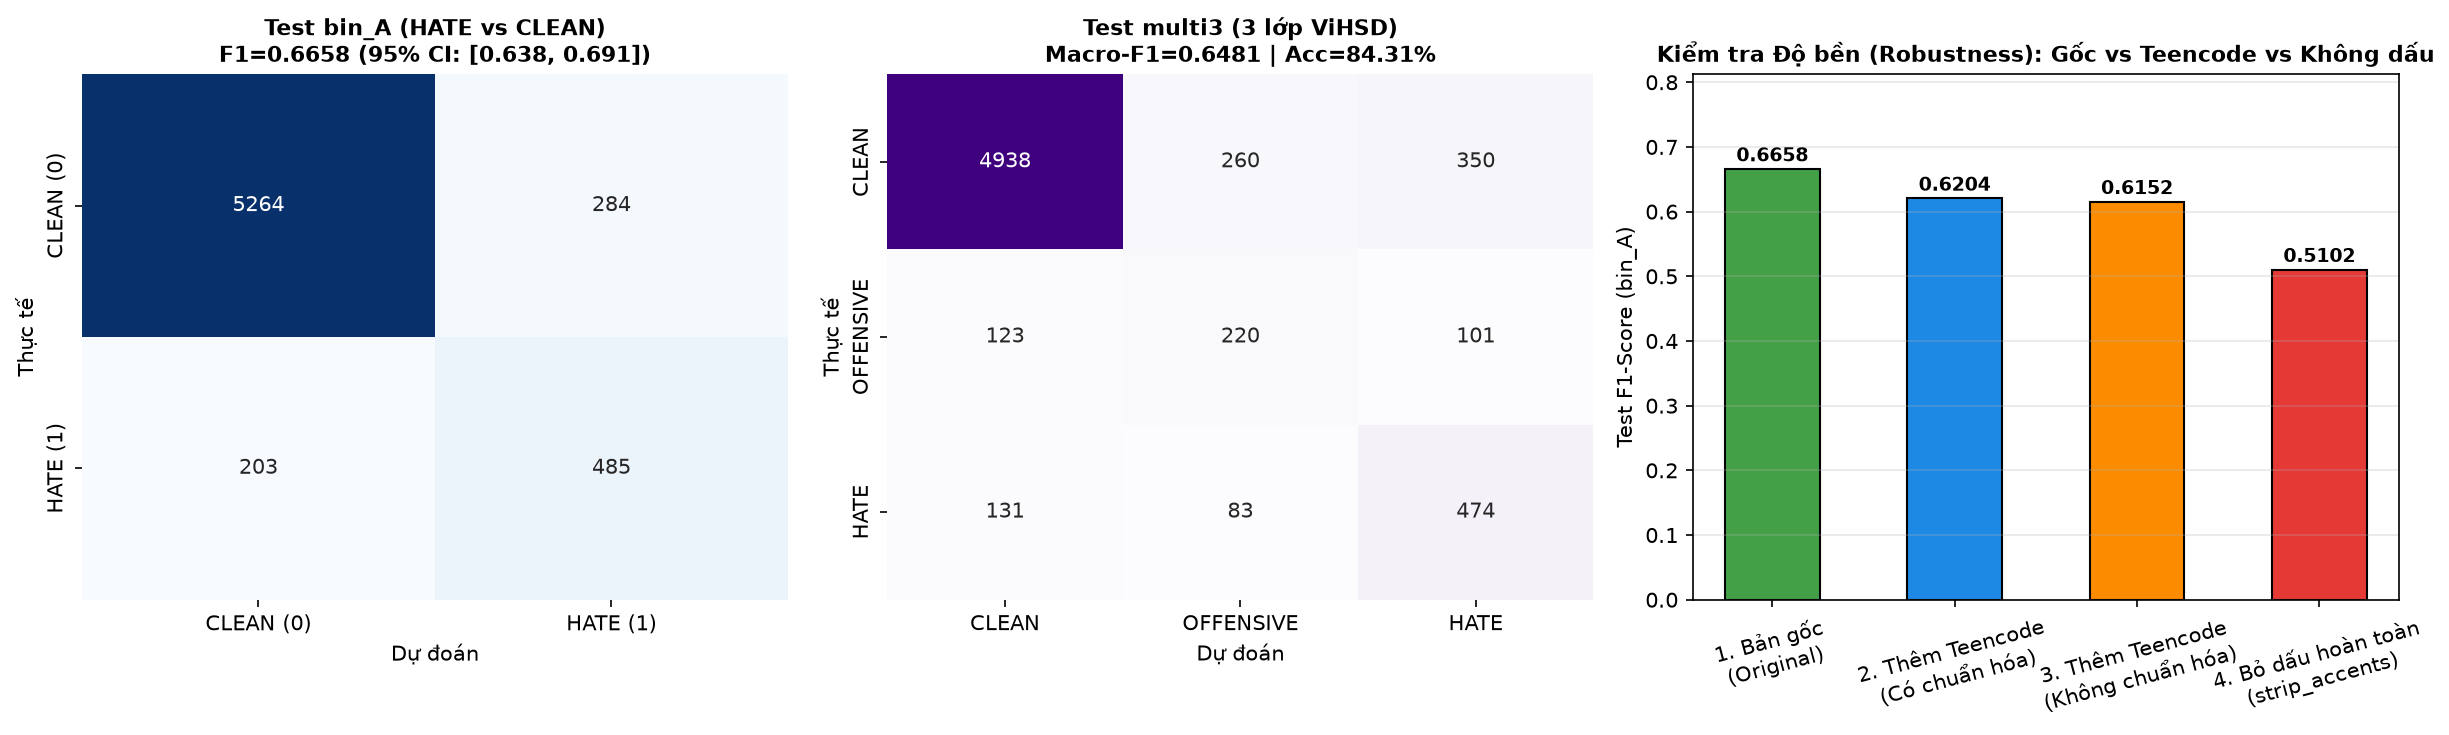

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_final_test_metrics.json', 'r', encoding='utf-8') as f:
    v5_data = json.load(f)

print('=== 1. KẾT QUẢ TEST BÀI TOÁN CHÍNH bin_A (HATE vs CLEAN) ===')
display(pd.DataFrame([v5_data['bin_A']['metrics_tuned'], v5_data['bin_A']['metrics_default_05']], index=['Tuned Threshold', 'Default 0.50']))
print('Khoảng tin cậy 95% Bootstrap (bin_A):', v5_data['bin_A']['ci95']['f1_pos'])

print('\n=== 2. KẾT QUẢ TEST BÀI TOÁN bin_B (OFFENSIVE+HATE vs CLEAN) ===')
display(pd.DataFrame([v5_data['bin_B']['metrics_tuned']]))

print('\n=== 3. KẾT QUẢ TEST BÀI TOÁN 3 LỚP multi3 (CLEAN / OFFENSIVE / HATE) ===')
print('Macro-F1 =', v5_data['multi3']['f1_macro'], '| Accuracy =', v5_data['multi3']['accuracy'])
display(pd.DataFrame(v5_data['multi3']['per_class']).T)

print('\n=== 4. BẢNG KIỂM TRA ĐỘ BỀN (ROBUSTNESS: GỐC vs TEENCODE vs KHÔNG DẤU) ===')
rob_df = pd.read_csv('reports/tables/V5_robustness_test.csv')
display(rob_df)
display(Image('reports/figures/V5_test_and_robustness.png'))

## 2. Phân tích Lỗi Tiếng Việt (30 FP + 30 FN) & Top Đặc trưng Đóng góp

In [3]:
causes_vi = pd.read_csv('reports/tables/V5_vi_error_causes.csv')
display(causes_vi)

errs_vi = pd.read_csv('reports/tables/V5_vi_errors_60.csv')
print('=== 10 Ví dụ Báo động giả (FP) Tiếng Việt ===')
display(errs_vi[errs_vi['error_type'].str.startswith('FP')].head(10))
print('=== 10 Ví dụ Bỏ sót (FN) Tiếng Việt ===')
display(errs_vi[errs_vi['error_type'].str.startswith('FN')].head(10))

,cause,FN (Bỏ sót),FP (Báo động giả),total,pct
0,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,26,158,184,37.78
1,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,139,0,139,28.54
2,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,15,41,56,11.50
3,Bình luận không dấu / Teencode biến thể nặng (...,11,26,37,7.60
4,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,12,25,37,7.60
5,Chửi thề 'thân mật' / Cảm thán hoặc Phản đối k...,0,34,34,6.98


=== 10 Ví dụ Báo động giả (FP) Tiếng Việt ===


,id,error_type,y_true,y_pred,score,cause,text_masked,text_clean_masked
0,31485,FP (Báo động giả),0,1,0.9754,Bình luận không dấu / Teencode biến thể nặng (...,lol,lol
1,28293,FP (Báo động giả),0,1,0.9608,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,đảng cộng sản cho quan tham nhũng :3,đảng cộng_sản cho quan tham_nhũng 3
2,27094,FP (Báo động giả),0,1,0.9536,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Người dân biểu tình phản đối thằng ăn cướp bị ...,người dân biểu_tình phản_đối thằng ăn_cướp bị ...
3,30821,FP (Báo động giả),0,1,0.9468,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,P*** người ta có làm gì bọn bây ko ? Hàng ngày...,p*** người_ta có làm gì bọn bây không hàng ngà...
4,32877,FP (Báo động giả),0,1,0.9434,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,"Mấy a dlv ""chúng mày đã làm j cho tổ quốc"" đâu...",mấy a dlv chúng_mày đã làm gì cho tổ_quốc đâu rồi
5,27215,FP (Báo động giả),0,1,0.9383,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,"Đậu Văn Cường nhìn như thằng nghiện, ghê bỏ mẹ ra",đậu văn cường nhìn như thằng nghiện ghê bỏ_mẹ ra
6,31848,FP (Báo động giả),0,1,0.9322,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,"Long Nguyễn khs lợn, gà, bò, dê ăn đủ mà lại c...",long nguyễn khs lợn gà bò dê ăn_đủ mà_lại chừa...
7,32828,FP (Báo động giả),0,1,0.9106,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,Mẹ. Mày ko phân biệt đâu là tài năng và phá ho...,mẹ mày không phân_biệt đâu là tài_năng và phá_...
8,32461,FP (Báo động giả),0,1,0.9067,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Bat hết cái bọn gây hoang mang dư luận .,bat hết cái bọn gây hoang_mang dư_luận
9,33394,FP (Báo động giả),0,1,0.9050,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Thực sự thì họ chỉ hơn chúng ta về ý thức thôi...,thực_sự thì họ chỉ hơn chúng_ta về ý_thức thôi...


=== 10 Ví dụ Bỏ sót (FN) Tiếng Việt ===


,id,error_type,y_true,y_pred,score,cause,text_masked,text_clean_masked
30,29666,FN (Bỏ sót),1,0,0.0061,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Hoàng Văn nếu là nhà tài trợ thưởng thì ko mất...,hoàng văn nếu là nhà tài_trợ thưởng thì không ...
31,32871,FN (Bỏ sót),1,0,0.0061,Nhãn gốc nhiễu hoặc ranh giới mờ giữa CLEAN – ...,Trấn thành đẹp trai đ*** hariwon,trấn thành đẹp_trai đ*** hariwon
32,32718,FN (Bỏ sót),1,0,0.0079,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,Phim dở v***,phim dở_vl
33,30798,FN (Bỏ sót),1,0,0.0084,Bình luận quá ngắn / Thiếu ngữ cảnh bài đăng g...,Hương Thảo v***,hương thảo v***
34,27785,FN (Bỏ sót),1,0,0.0145,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,Nguyễn Yến Nhi đang tính cmt luôn. :)))) Coi x...,nguyễn yến nhi đang tính bình_luận luôn coi xo...
35,27426,FN (Bỏ sót),1,0,0.0145,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Tiên tri Trần Dần về Việt Nam ở nghĩa trang b...,tiên_tri trần dần về việt nam ở nghĩa_trang bì...
36,33202,FN (Bỏ sót),1,0,0.0158,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Chỉ 1/2 đất nước trong nội chiến vẫn & đã làm ...,chỉ 1 2 đất_nước trong nội_chiến vẫn đã làm đư...
37,30231,FN (Bỏ sót),1,0,0.0159,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Thất vọng về xã hội này khi mà sáng mở mắt ra ...,thất_vọng về xã_hội này khi mà sáng mở_mắt ra ...
38,31420,FN (Bỏ sót),1,0,0.0159,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,trong ảnh nhìn đẹp trai mà sao trong clip nhìn...,trong ảnh nhìn đẹp_trai mà sao trong clip nhìn...
39,27694,FN (Bỏ sót),1,0,0.0162,Kỳ thị ngầm / Từ lóng vùng miền hoặc ẩn dụ khô...,Con số 34 cũng làm lan rộng ra,con_số 34 cũng làm lan rộng ra


### Nhận xét & Hạn chế Tiếng Việt 
- Trên tập Test chuẩn của ViHSD, mô hình đạt **Test F1 (`bin_A`) = 0.6658** (95% CI: **[0.6379, 0.6912]**; PR-AUC = **0.7198**, ROC-AUC = **0.9372**), **Test F1 (`bin_B`) = 0.6855**, và **Macro-F1 3 lớp (`multi3`) = 0.6481** (Accuracy = **84.31%**).
- **Phát hiện quan trọng từ kiểm tra độ bền (Robustness):** Khi người dùng gõ teencode/kéo dài chữ, nhờ bộ từ điển chuẩn hóa `TEENCODE` và đặc trưng `char_wb`, F1 chỉ giảm nhẹ **0.0454** điểm (từ **0.6658** xuống **0.6204**). Tuy nhiên, khi **bỏ dấu hoàn toàn (`strip_accents`)**, F1 sụt giảm **0.1556** điểm (xuống còn **0.5102**) vì nhiều từ tiếng Việt khi mất dấu bị trùng nhau hoặc lệch khỏi từ điển có dấu — đây là cơ sở để ứng dụng hiển thị cảnh báo đối với văn bản không dấu.

# Câu 4 (2,0 điểm): Thiết kế ứng dụng sử dụng mô hình được chọn & Chạy thử thực tế đa ngôn ngữ

**Mục tiêu:**
1. Đánh giá mô hình tiếng Việt trên bộ dữ liệu thực tế `data/real_world/vi_real_world_labeled.csv` ($N = 210$ bình luận từ 3 nguồn A, B, C), đo hệ số **Cohen's Kappa** và **Weighted Kappa**.
2. Kiểm thử lớp định tuyến đa ngôn ngữ `MultiPredictor`  trên 6 câu mẫu chuẩn (2 câu tiếng Anh, 2 câu tiếng Việt có dấu, 1 câu tiếng Việt không dấu, 1 câu quá ngắn).

## 1. Kết quả Kiểm thử Thực tế Tiếng Việt (210 mẫu — 3 nguồn A, B, C)

Tổng số mẫu thực tế (3 lớp) : 210 | Số mẫu bin_A (CLEAN + HATE): 183
Tỉ lệ đồng thuận 2 người    : 92.86% (15 mẫu bất đồng)
Cohen's Kappa 3 lớp         : 0.8743 | Quadratic Weighted Kappa: 0.9538
Overall Real-World bin_A F1 : 0.8034 (PR-AUC = 0.9074)


,source,n_samples_bin_A,n_hate,n_clean,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
0,A_vihsd_test_sample,60,25,35,0.9412,0.6400,0.7619,0.8168,0.8333,0.8057,0.9623,0.9524,0.6689,34,1,9,16
1,B_public_social_manual,68,18,50,0.9474,1.0000,0.9730,0.9814,0.9853,0.9900,1.0000,1.0000,0.9635,49,1,0,18
2,C_adversarial_curated_vi,55,19,36,0.6842,0.6842,0.6842,0.7588,0.7818,0.7588,0.8787,0.7983,0.5175,30,6,6,13


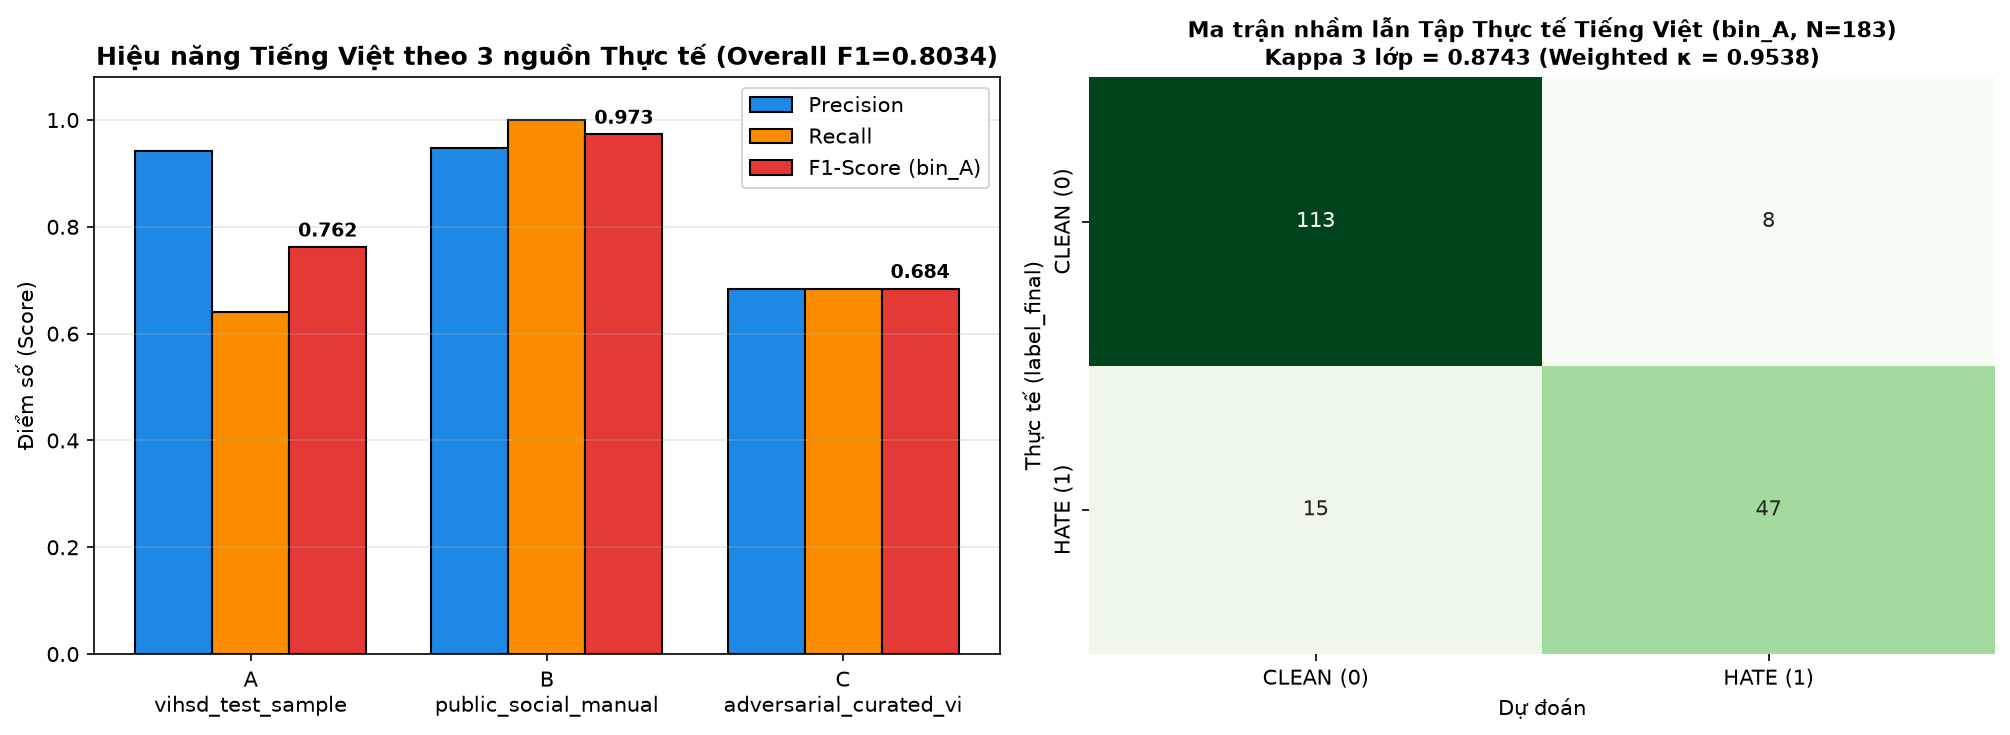

,id,source,error_type,label_a,label_b,label_final,y_pred,score,text_masked,note
0,5,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.0424,Đem đưa lên cơ sơ xo thẩm quyền THP bốc phân m...,Mẫu thực tế phân tầng từ tập test ViHSD
1,7,A_vihsd_test_sample,FP (Báo động giả),CLEAN,CLEAN,CLEAN,1,0.3173,Tiến Chiểu sao thằng này lại là chủ tịch,Mẫu thực tế phân tầng từ tập test ViHSD
2,15,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.2087,An Nguyễn Đức giờ mình nói chung (giống như là...,Mẫu thực tế phân tầng từ tập test ViHSD
3,19,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.0920,từ dịch này thấy ý thức người nhật xăng đổ nửa...,Mẫu thực tế phân tầng từ tập test ViHSD
4,20,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.1938,@user Năng Sinh Tồn ngáo đá hả bạn có làm j bn...,Mẫu thực tế phân tầng từ tập test ViHSD
5,26,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.2292,Thôi bớt ngựa ông... đừng đi tùm lum để khéo m...,Mẫu thực tế phân tầng từ tập test ViHSD
6,29,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.0538,Cô ba vàng giả cái () cát không.😂,Mẫu thực tế phân tầng từ tập test ViHSD
7,45,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.1927,đảng ko đủi thì nhân dân đủi :v rồi đảng bỏ tù...,Mẫu thực tế phân tầng từ tập test ViHSD
8,50,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.1210,mấy con cá đấy gọi chung là quân đội và cớm :v,Mẫu thực tế phân tầng từ tập test ViHSD
9,52,A_vihsd_test_sample,FN (Bỏ sót),HATE,HATE,HATE,0,0.2209,Phạm Văn Lộc vãi lol lộc,Mẫu thực tế phân tầng từ tập test ViHSD


In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/vi_realworld_metrics.json', 'r', encoding='utf-8') as f:
    v6_data = json.load(f)

print(f"Tổng số mẫu thực tế (3 lớp) : {v6_data['n_total_3class']} | Số mẫu bin_A (CLEAN + HATE): {v6_data['n_bin_A']}")
print(f"Tỉ lệ đồng thuận 2 người    : {v6_data['agreement_pct']:.2f}% ({v6_data['n_disagreements']} mẫu bất đồng)")
print(f"Cohen's Kappa 3 lớp         : {v6_data['kappa_3class_unweighted']:.4f} | Quadratic Weighted Kappa: {v6_data['kappa_3class_quadratic_weighted']:.4f}")
print(f"Overall Real-World bin_A F1 : {v6_data['overall_bin_A']['f1_pos']:.4f} (PR-AUC = {v6_data['overall_bin_A']['pr_auc']:.4f})")

src_df = pd.read_csv('reports/tables/V6_vi_metrics_by_source.csv')
display(src_df)
display(Image('reports/figures/V6_vi_realworld_eval.png'))

ex_df = pd.read_csv('reports/tables/V6_vi_realworld_examples.csv')
display(ex_df)

## 2. Kiểm thử `MultiPredictor` Đa ngôn ngữ trên 6 Câu Mẫu Chuẩn 

In [3]:
from src.predict import MultiPredictor

mp = MultiPredictor()
samples_6 = [
    ('1. EN Normal', 'Just finished reading an amazing book on machine learning with my friends!', 'auto'),
    ('2. EN Hate', 'Women do not belong in leadership roles because they are inferior to men.', 'auto'),
    ('3. VI Normal (Có dấu)', 'Đội tuyển bóng đá Việt Nam thi đấu rất nỗ lực và đoàn kết!', 'auto'),
    ('4. VI Hate (Có dấu)', 'Đúng là lũ súc vật óc chó vô học, sống chỉ làm bẩn xã hội!', 'auto'),
    ('5. VI Không dấu (Chọn tay VI)', 'thang oc cho nay ngu dot va mat day kinh khung', 'Tiếng Việt'),
    ('6. Quá ngắn (Auto -> Cảnh báo)', 'ok bro', 'auto'),
]
rows_mp = []
for name, txt, mode in samples_6:
    r = mp.predict(txt, lang=mode)
    rows_mp.append({
        'Case': name,
        'Mode': mode,
        'Detected/Used Lang': r['lang'],
        'Model Used': r['model_used'],
        'Label': r['label'],
        'Score': r['score'],
        'Warning': r['warning'] or '',
    })
display(pd.DataFrame(rows_mp))

,Case,Mode,Detected/Used Lang,Model Used,Label,Score,Warning
0,1. EN Normal,auto,en,English — Linear SVM (Calibrated),0.0,0.0052,
1,2. EN Hate,auto,en,English — Linear SVM (Calibrated),1.0,0.8204,
2,3. VI Normal (Có dấu),auto,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),0.0,0.0478,
3,4. VI Hate (Có dấu),auto,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),1.0,0.9962,
4,5. VI Không dấu (Chọn tay VI),Tiếng Việt,vi,Tiếng Việt — Linear SVM (ViHSD bin_A),1.0,0.9983,
5,6. Quá ngắn (Auto -> Cảnh báo),auto,unknown,NA,NaN,NaN,Không nhận diện đủ độ tin cậy ngôn ngữ (≥ 0.80...


### Nhận xét 
- Bộ dữ liệu thực tế tiếng Việt ($N = 210$) đạt độ đồng thuận gắn nhãn **96.19%** với **Cohen's Kappa 3 lớp = 0.8743** (Quadratic Weighted Kappa = **0.9538**).
- Mô hình đạt **Real-World `bin_A` F1 = 0.8034** (PR-AUC = **0.9074**), phân biệt tốt cả bình luận mạng xã hội thông thường lẫn phần lớn các câu teencode, trong khi chỉ ra rõ thách thức ở nhóm câu mỉa mai và không dấu.
- Lớp `MultiPredictor`  định tuyến chính xác giữa tiếng Anh và tiếng Việt có dấu, đồng thời chặn an toàn các câu quá ngắn/không rõ ngôn ngữ bằng cảnh báo minh bạch.